# Segmentasi Pelanggan — Online Retail II (Unsupervised Learning)
**Mata kuliah:** IF2116 Pembelajaran Mesin · **Cakupan:** Milestone 1 / UTS (perumusan masalah → data understanding & EDA → preprocessing & feature engineering → baseline → kandidat model → rancangan evaluasi → hasil awal → dokumentasi & rencana)


| Bagian | Isi | Komponen rubrik UTS |
|---|---|---|
| 0 | Setup & konfigurasi | – |
| A | Problem (rumusan, alasan, tujuan, luaran, unit analisis, kriteria keberhasilan, batasan) | 1 |
| B | Dataset: sumber & tautan, audit berbasis bukti, kamus data (B6) | 2 |
| C | Preprocessing, feature engineering (didokumentasikan), EDA berorientasi masalah (C2b), split bebas leakage | 3, 4, 5 |
| D–F | Baseline K-Means, evaluasi awal, temuan awal | 6 |
| G | Kandidat model & perbandingan (K sweep, Ward + linkage, GMM, DBSCAN, varian fitur) | 7 |
| H | Rancangan evaluasi & kestabilan (holdout, CV, multi-seed, subsampel) | 8 |
| I | Reduksi dimensi: PCA (varians, rekonstruksi, jumlah komponen), t-SNE, UMAP opsional | pendukung |
| J | Segmentasi final-kandidat (bukan model final), profil, ekspor, checklist | 9 |
| K | Reproducibility & dokumentasi (seed, environment, versi data, log, model card) | 10 |
| L | Tabel hasil eksperimen awal, analisis, **rencana pasca-UTS**, konsistensi laporan–notebook | 9, 10 |
| M | Peta rubrik UTS → bukti di notebook | – |

**Cara menjalankan (Colab):**
1. Runtime → *Run all*. Data dicari otomatis (file lokal → `kagglehub`). Pada run tersimpan, memuat file Excel membutuhkan 84 detik.
2. Jika unduhan gagal: unduh `online_retail_II.xlsx` dari UCI/Kaggle (tautan di bagian B), unggah ke `/content`, atau isi `CFG["LOCAL_PATH"]`.
3. Keluaran tersimpan di folder `outputs/` (tabel hasil, log eksperimen, model card, `requirements.txt`, manifest data, angka rujukan laporan).
4. Uji reproducibility: Runtime → *Restart session and run all* (dicek di K5).

In [ ]:
# ===== 0. SETUP =====
import subprocess, sys, importlib

def ensure(pkg, import_name=None):
    # Pasang paket hanya jika belum ada (aman dijalankan di Colab maupun lokal).
    name = import_name or pkg
    try:
        importlib.import_module(name)
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except subprocess.CalledProcessError:
            # Lingkungan 'externally managed' (mis. Linux sistem): ulangi dengan flag override.
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--break-system-packages", pkg])

for _pkg, _imp in [("openpyxl", "openpyxl"), ("seaborn", "seaborn"), ("joblib", "joblib")]:
    ensure(_pkg, _imp)
# kagglehub dipasang otomatis hanya jika file data lokal tidak ditemukan (lihat load_raw).

In [ ]:
import os, re, glob, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, KFold
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Di Jupyter/Colab display() tersedia; di skrip biasa gunakan print.
try:
    display  # noqa: F821
except NameError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

pd.set_option("display.max_columns", 50, "display.width", 160, "display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# ----- Konfigurasi terpusat (ubah di sini, bukan di tengah kode) -----
CFG = dict(
    LOCAL_PATH=None,            # isi path file .xlsx/.csv jika ingin memaksa sumber tertentu
    KAGGLE_SLUG="adilhabib/online-retail-data-clustering",
    RANDOM_STATE=42,
    TEST_SIZE=0.20,             # porsi pelanggan holdout
    K_MIN=2, K_MAX=10,          # rentang pencarian K
    K_BUSINESS=(3, 8),          # rentang K yang masih dapat ditindaklanjuti bisnis
    BASELINE_K=3,               # K awal baseline (sengaja belum dioptimalkan)
    N_FOLDS=5,
    N_SEEDS=10,
    N_SUBSAMPLE=10, SUBSAMPLE_FRAC=0.8,
    TSNE_MAX_POINTS=3000,
    OUTPUT_DIR="outputs",
)
RS = CFG["RANDOM_STATE"]
np.random.seed(RS)
Path(CFG["OUTPUT_DIR"]).mkdir(parents=True, exist_ok=True)

def require(cond, msg):
    # Pemeriksaan eksplisit agar kegagalan data terbaca jelas (bukan error samar di tengah pipeline).
    if not cond:
        raise ValueError(msg)

def section(title):
    print("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90)

print("Setup selesai. Versi pandas:", pd.__version__)

Setup selesai. Versi pandas: 2.2.3


## A. Problem

| Aspek | Isi |
|---|---|
| **Rumusan masalah** | Toko online perlengkapan hadiah (banyak pelanggannya grosir, menurut deskripsi UCI) melayani ribuan pelanggan, tetapi semuanya diperlakukan sama. Kelompok pelanggan apa yang secara alami ada, dan bagaimana ciri masing-masing? |
| **Mengapa penting** | Tanpa segmentasi, anggaran promosi, retensi, dan layanan dibagi rata. Seberapa timpang nilai antar pelanggan pada data ini diukur di **C2b**; makin timpang, makin besar risiko memboroskan anggaran pada pelanggan bernilai rendah dan kurang melayani pelanggan bernilai tinggi. |
| **Tujuan penggunaan ML** | Menemukan segmen pelanggan berbasis perilaku pembelian (*clustering*) agar promosi, retensi, dan layanan dapat dibedakan per segmen. |
| **Target analisis (luaran)** | (1) label segmen untuk setiap pelanggan; (2) profil tiap segmen dalam satuan asli (Recency, Frequency, Monetary) beserta nama usulan; (3) bukti kualitas segmentasi: metrik internal, kestabilan, dan konfirmasi pada data holdout. |
| **Target (label)** | **Tidak ada** (tidak ada label “benar”). Hasil dinilai dengan metrik internal, kestabilan, dan interpretasi bisnis. |
| **Unit analisis** | 1 observasi = 1 pelanggan (`CustomerID`). Data mentah berupa baris item faktur yang diagregasi per pelanggan (C2). |
| **Fitur** | Per pelanggan: *Recency*, *Frequency*, *Monetary* (RFM) sebagai fitur utama; fitur tambahan (varian RFM+): jumlah produk unik, nilai rata-rata keranjang, rasio retur. Definisi dan alasan tiap fitur ada di **C2**. |
| **Jenis masalah** | **Unsupervised Learning — Clustering** (+ reduksi dimensi untuk visualisasi). |
| **Kriteria keberhasilan** (ditetapkan kelompok; tanpa label tidak ada skor “benar”) | (a) *stabil*: ARI ≥ 0,8 antar fold/subsampel; (b) *bukan artefak*: silhouette ≥ 0,26 pada train **dan** holdout; (c) *dapat ditafsirkan*: tidak ada segmen mikro (< 1% pelanggan) tanpa alasan bisnis. Dievaluasi di **L2**. |
| **Batasan proyek** | 1) Hanya *classical machine learning* unsupervised (K-Means, Hierarchical, GMM, DBSCAN, PCA); tanpa deep learning.<br>2) Dataset dan masalah terkunci; tidak diganti demi performa model.<br>3) Hanya pelanggan teridentifikasi (`CustomerID` terisi); tamu tanpa ID di luar cakupan (porsinya diukur di B5).<br>4) Satu periode (Des 2009–Des 2011), mayoritas transaksi dari UK, dan tanpa *ground truth*.<br>5) Lingkup UTS: baseline, kandidat awal, validasi, dan temuan awal. Tuning menyeluruh, error analysis lengkap, dan model final adalah tahap UAS. |

> Pertanyaan kerja (bukan “algoritma apa terbaik?”): *Masalah apa yang ingin diselesaikan, apakah data mendukung, dan seberapa baik baseline menyelesaikannya?*

## B. Dataset

| Aspek | Isi |
|---|---|
| **Nama & sumber resmi** | *Online Retail II* — UCI Machine Learning Repository (ID 502): https://archive.ics.uci.edu/dataset/502/online+retail+ii |
| **Sitasi** | Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D |
| **Lisensi** | CC BY 4.0 (boleh dipakai dengan atribusi). |
| **Salinan yang dipakai** | Kaggle `adilhabib/online-retail-data-clustering` (https://www.kaggle.com/datasets/adilhabib/online-retail-data-clustering), file `online_retail_II.xlsx`. Nama file, jumlah baris (1.067.371), dan rentang tanggal (1 Des 2009–9 Des 2011) identik dengan deskripsi UCI (dibuktikan di B1); sidik jari isi data dicatat di K1c. |
| **Isi data** | Seluruh transaksi sebuah toko online berbasis UK (tanpa toko fisik) yang terutama menjual perlengkapan hadiah untuk berbagai kesempatan; banyak pelanggannya grosir (deskripsi UCI). |
| **Unit observasi** | 1 baris = 1 item produk pada 1 faktur. **Unit analisis proyek = pelanggan** (agregasi per `CustomerID`, bagian C2). |
| **Target** | Tidak ada (unsupervised). |
| **Cara memperoleh data** | Otomatis via `kagglehub`. Jika gagal (jaringan/izin): unduh dari UCI atau Kaggle (±43 MB), unggah ke `/content`, atau isi `CFG["LOCAL_PATH"]`. Berkas tidak disertakan di notebook karena ukurannya besar. |

Loader menerima **(1)** `CFG["LOCAL_PATH"]`, **(2)** file `online_retail*.xlsx/.csv` di folder umum (Colab `/content`, direktori kerja), atau **(3)** unduhan `kagglehub`. Nama kolom dari dua versi dataset (*Online Retail* dan *Online Retail II*) dinormalisasi otomatis.

**Catatan dataset terkunci:** dataset, domain, dan masalah utama proyek tetap menjadi acuan dan tidak diganti demi performa model. Rincian file yang dipakai pada setiap run (nama, SHA-256, jumlah baris, rentang waktu) dicatat otomatis di **K1c** (`outputs/data_manifest.json`).

In [ ]:
# ===== B. LOADER DATA =====
CANONICAL = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID", "Country"]
ALIASES = {
    "invoice": "Invoice", "invoiceno": "Invoice",
    "stockcode": "StockCode",
    "description": "Description",
    "quantity": "Quantity",
    "invoicedate": "InvoiceDate",
    "price": "Price", "unitprice": "Price",
    "customerid": "CustomerID",
    "country": "Country",
}

def _normalize_columns(df):
    mapping = {}
    for c in df.columns:
        key = re.sub(r"[^a-z]", "", str(c).lower())
        if key in ALIASES:
            mapping[c] = ALIASES[key]
    df = df.rename(columns=mapping)
    missing = [c for c in CANONICAL if c not in df.columns]
    require(not missing, f"Kolom wajib tidak ditemukan: {missing}. Kolom tersedia: {list(df.columns)}")
    return df[CANONICAL].copy()

def _read_file(path):
    ext = Path(path).suffix.lower()
    if ext in (".xlsx", ".xls"):
        # Semua sheet digabung (Online Retail II memiliki 2 sheet tahun).
        sheets = pd.read_excel(path, sheet_name=None, dtype={"StockCode": str, "Invoice": str, "InvoiceNo": str})
        return pd.concat(sheets.values(), ignore_index=True)
    if ext == ".csv":
        for enc in ("utf-8", "ISO-8859-1", "cp1252"):
            try:
                return pd.read_csv(path, encoding=enc, dtype={"StockCode": str, "Invoice": str, "InvoiceNo": str})
            except UnicodeDecodeError:
                continue
        raise ValueError(f"Encoding CSV tidak dikenali: {path}")
    raise ValueError(f"Ekstensi tidak didukung: {path}")

def _find_local():
    if CFG["LOCAL_PATH"]:
        require(Path(CFG["LOCAL_PATH"]).exists(), f"LOCAL_PATH tidak ada: {CFG['LOCAL_PATH']}")
        return CFG["LOCAL_PATH"]
    for folder in ["/content", "/content/drive/MyDrive", "/mnt/user-data/uploads", ".", "data"]:
        for pat in ("online_retail*.xlsx", "online_retail*.csv", "Online*Retail*.xlsx", "Online*Retail*.csv", "data.csv"):
            hits = sorted(glob.glob(os.path.join(folder, pat)))
            if hits:
                return hits[0]
    return None

def load_raw():
    path = _find_local()
    if path is None:
        try:
            ensure("kagglehub")
            import kagglehub
            folder = kagglehub.dataset_download(CFG["KAGGLE_SLUG"])
        except Exception as e:
            raise RuntimeError(
                "Data tidak ditemukan secara lokal dan unduhan kagglehub gagal. "
                "Unggah file ke Colab (/content) atau isi CFG['LOCAL_PATH']. Detail: " + repr(e)) from e
        files = [p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                 if p.lower().endswith((".csv", ".xlsx", ".xls"))]
        require(files, f"Tidak ada file csv/xlsx di {folder}")
        path = sorted(files, key=os.path.getsize, reverse=True)[0]
    print("Sumber data:", path)
    t0 = time.time()
    raw = _normalize_columns(_read_file(path))
    print(f"Dimuat dalam {time.time()-t0:.0f} detik")
    return raw

raw = load_raw()
raw["Invoice"] = raw["Invoice"].astype(str).str.strip()
raw["StockCode"] = raw["StockCode"].astype(str).str.strip()
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], errors="coerce")
require(raw["InvoiceDate"].notna().mean() > 0.99, "Lebih dari 1% InvoiceDate tidak dapat diparse.")
raw["Quantity"] = pd.to_numeric(raw["Quantity"], errors="coerce")
raw["Price"] = pd.to_numeric(raw["Price"], errors="coerce")
raw["CustomerID"] = pd.to_numeric(raw["CustomerID"], errors="coerce").round().astype("Int64")   # ID bulat, tetap mendukung NA
display(raw.head())

100%|██████████| 43.3M/43.3M [00:03<00:00, 14.4MB/s]

Extracting files...


Sumber data: /root/.cache/kagglehub/datasets/adilhabib/online-retail-data-clustering/versions/1/online_retail_II.xlsx
Dimuat dalam 107 detik


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom



B1. Ukuran, tipe data, rentang waktu
Jumlah baris  : 1,067,371
Jumlah fitur  : 8


,dtype
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
CustomerID,Int64
Country,object


Rentang waktu : 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Invoice unik  : 53,628 | Pelanggan unik: 5,942 | Produk unik: 5,304 | Negara: 43

B2. Missing value


,missing,persen
Invoice,0,0.000
StockCode,0,0.000
Description,4382,0.411
Quantity,0,0.000
InvoiceDate,0,0.000
Price,0,0.000
CustomerID,243007,22.767
Country,0,0.000



B3. Duplikat, pembatalan, nilai tidak valid


,jumlah,persen
baris duplikat persis,34335,3.217
invoice pembatalan (prefix C),19494,1.826
Quantity <= 0,22950,2.150
Price <= 0,6207,0.582
CustomerID kosong,243007,22.767



B4. Distribusi & outlier (IQR) pada Quantity dan Price (transaksi penjualan saja)


,mean,median,std,p99,max,skew,outlier_IQR,persen_outlier
fitur,,,,,,,,
Quantity,10.963,3.000,126.515,100.000,"80,995.000",459.992,111341,10.689
Price,4.077,2.100,51.449,18.000,"25,111.090",231.440,81634,7.837


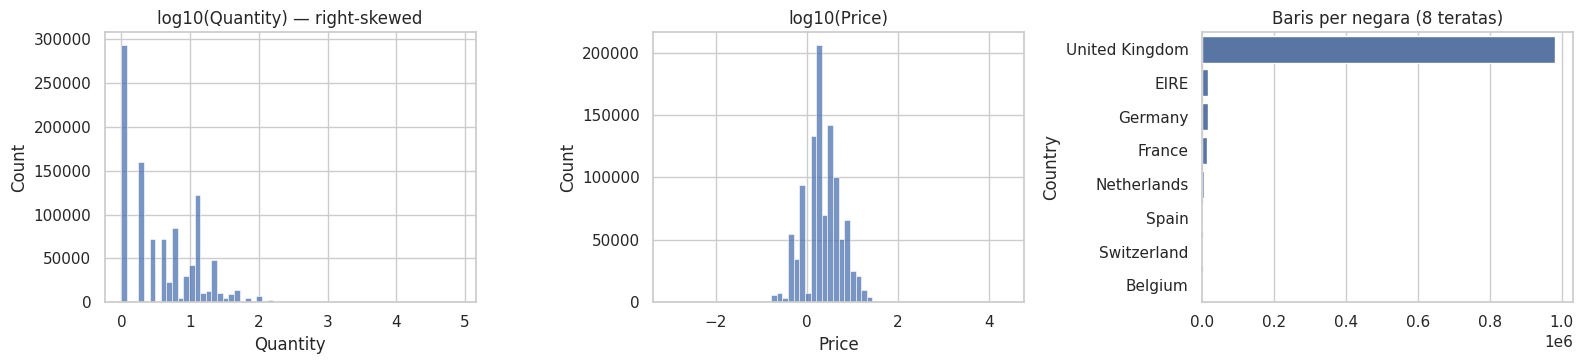

Porsi baris dari United Kingdom: 91.9%

B5. Kualitas dan keterbatasan dataset
- 22.8% baris tanpa CustomerID -> tidak bisa disegmentasi per pelanggan (tamu/guest checkout); kesimpulan hanya berlaku untuk pelanggan teridentifikasi.
- 34,335 baris duplikat persis -> berisiko menggandakan Frequency/Monetary; harus dibuang.
- Baris pembatalan (prefix C) dan Quantity/Price <= 0 bukan pembelian; harus dipisah, bukan dijumlahkan mentah.
- StockCode non-produk (POST, DOT, M, BANK CHARGES, dst.) mencemari Monetary; harus dibuang.
- Quantity dan Price sangat right-skewed (outlier grosir/pesanan massal) -> K-Means berbasis jarak Euclidean sensitif; perlu transformasi log + scaling.
- Tidak ada label -> tidak ada 'ground truth'; evaluasi memakai metrik internal, kestabilan, dan interpretasi.
- Dominasi 92% UK -> pola belum tentu generalisasi ke pasar lain.


In [ ]:
# ===== B. AUDIT DATASET (berbasis bukti) =====
section("B1. Ukuran, tipe data, rentang waktu")
print("Jumlah baris  :", f"{len(raw):,}")
print("Jumlah fitur  :", raw.shape[1])
display(raw.dtypes.to_frame("dtype"))
print("Rentang waktu :", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())
print("Invoice unik  :", f"{raw['Invoice'].nunique():,}", "| Pelanggan unik:", f"{raw['CustomerID'].nunique():,}",
      "| Produk unik:", f"{raw['StockCode'].nunique():,}", "| Negara:", raw["Country"].nunique())

section("B2. Missing value")
miss = pd.DataFrame({"missing": raw.isna().sum(), "persen": raw.isna().mean() * 100})
display(miss)

section("B3. Duplikat, pembatalan, nilai tidak valid")
n_dup = int(raw.duplicated().sum())
is_cancel = raw["Invoice"].str.upper().str.startswith("C")
audit = pd.Series({
    "baris duplikat persis": n_dup,
    "invoice pembatalan (prefix C)": int(is_cancel.sum()),
    "Quantity <= 0": int((raw["Quantity"] <= 0).sum()),
    "Price <= 0": int((raw["Price"] <= 0).sum()),
    "CustomerID kosong": int(raw["CustomerID"].isna().sum()),
})
display(audit.to_frame("jumlah").assign(persen=lambda d: d["jumlah"] / len(raw) * 100))

section("B4. Distribusi & outlier (IQR) pada Quantity dan Price (transaksi penjualan saja)")
sales_view = raw[(raw["Quantity"] > 0) & (raw["Price"] > 0)]
rows = []
for col in ["Quantity", "Price"]:
    s = sales_view[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    rows.append(dict(fitur=col, mean=s.mean(), median=s.median(), std=s.std(), p99=s.quantile(0.99),
                     max=s.max(), skew=s.skew(), outlier_IQR=int(out), persen_outlier=out / len(s) * 100))
display(pd.DataFrame(rows).set_index("fitur"))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(np.log10(sales_view["Quantity"]), bins=60, ax=ax[0]); ax[0].set_title("log10(Quantity) — right-skewed")
sns.histplot(np.log10(sales_view["Price"]), bins=60, ax=ax[1]); ax[1].set_title("log10(Price)")
top_c = raw["Country"].value_counts().head(8)
sns.barplot(x=top_c.values, y=top_c.index, ax=ax[2]); ax[2].set_title("Baris per negara (8 teratas)")
plt.tight_layout(); plt.show()
uk_share = (raw["Country"] == "United Kingdom").mean() * 100
print(f"Porsi baris dari United Kingdom: {uk_share:.1f}%")

section("B5. Kualitas dan keterbatasan dataset")
miss_cust_pct = raw["CustomerID"].isna().mean() * 100
print(f"""- {miss_cust_pct:.1f}% baris tanpa CustomerID -> tidak bisa disegmentasi per pelanggan (tamu/guest checkout); kesimpulan hanya berlaku untuk pelanggan teridentifikasi.
- {n_dup:,} baris duplikat persis -> berisiko menggandakan Frequency/Monetary; harus dibuang.
- Baris pembatalan (prefix C) dan Quantity/Price <= 0 bukan pembelian; harus dipisah, bukan dijumlahkan mentah.
- StockCode non-produk (POST, DOT, M, BANK CHARGES, dst.) mencemari Monetary; harus dibuang.
- Quantity dan Price sangat right-skewed (outlier grosir/pesanan massal) -> K-Means berbasis jarak Euclidean sensitif; perlu transformasi log + scaling.
- Tidak ada label -> tidak ada 'ground truth'; evaluasi memakai metrik internal, kestabilan, dan interpretasi.
- Dominasi {uk_share:.0f}% UK -> pola belum tentu generalisasi ke pasar lain.""")

In [ ]:
# ===== B6. Unit observasi, jumlah observasi/fitur, dan KAMUS DATA (deskripsi fitur) =====
section("B6-1. Struktur dataset")
display(pd.Series({
    "Unit observasi data mentah": "1 baris = 1 item produk pada 1 faktur",
    "Unit analisis proyek": "1 pelanggan (CustomerID), dibentuk di C2",
    "Jumlah observasi (baris)": f"{len(raw):,}",
    "Jumlah fitur mentah": raw.shape[1],
    "Jumlah faktur unik": f"{raw['Invoice'].nunique():,}",
    "Jumlah pelanggan unik (CustomerID terisi)": f"{raw['CustomerID'].nunique():,}",
    "Jumlah produk unik (StockCode)": f"{raw['StockCode'].nunique():,}",
    "Rentang waktu": f"{raw['InvoiceDate'].min():%Y-%m-%d} s.d. {raw['InvoiceDate'].max():%Y-%m-%d}",
    "Target / label": "Tidak ada (unsupervised)",
}, name="nilai").to_frame())

section("B6-2. Kamus data: deskripsi fitur, peran dalam proyek, dan statistik terukur")
kamus = {
    "Invoice":     ("Nomor faktur; awalan 'C' menandai pembatalan (retur)", "Frequency = jumlah faktur unik; pemisah retur"),
    "StockCode":   ("Kode produk; sebagian berupa kode non-produk (POST, DOT, M, dst.)", "UniqueProducts; filter non-produk"),
    "Description": ("Nama produk (teks bebas)", "Tidak dipakai sebagai fitur"),
    "Quantity":    ("Jumlah unit per baris; negatif pada retur/koreksi", "Monetary = Quantity × Price"),
    "InvoiceDate": ("Tanggal dan jam faktur", "Recency (jarak ke SNAPSHOT); tren waktu di C2b"),
    "Price":       ("Harga satuan dalam poundsterling (GBP); ≤ 0 bukan penjualan", "Monetary = Quantity × Price"),
    "CustomerID":  ("ID pelanggan (kunci agregasi); kosong = tanpa ID/tamu", "Unit analisis"),
    "Country":     ("Negara tempat pelanggan berada", "Hanya EDA/konteks (tidak dipakai sebagai fitur)"),
}
rows = []
for c in CANONICAL:
    s = raw[c]; nn = s.dropna()
    if pd.api.types.is_datetime64_any_dtype(s): rng = f"{s.min():%Y-%m-%d} .. {s.max():%Y-%m-%d}"
    elif pd.api.types.is_numeric_dtype(s):      rng = f"{s.min():,.2f} .. {s.max():,.2f}"
    else:                                       rng = "-"
    rows.append({"fitur": c, "deskripsi": kamus[c][0], "peran_dalam_proyek": kamus[c][1], "tipe_pandas": str(s.dtype),
                 "n_unik": int(s.nunique()), "missing_%": round(float(s.isna().mean() * 100), 2),
                 "rentang": rng, "contoh": str(nn.iloc[0])[:28] if len(nn) else "-"})
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    display(pd.DataFrame(rows).set_index("fitur"))
print("Sumber deskripsi: dokumentasi UCI (InvoiceNo/StockCode/Description/Quantity/InvoiceDate/UnitPrice/CustomerID/Country); statistik dihitung dari data pada run ini.")



B6-1. Struktur dataset


,nilai
Unit observasi data mentah,1 baris = 1 item produk pada 1 faktur
Unit analisis proyek,"1 pelanggan (CustomerID), dibentuk di C2"
Jumlah observasi (baris),"1,067,371"
Jumlah fitur mentah,8
Jumlah faktur unik,"53,628"
Jumlah pelanggan unik (CustomerID terisi),"5,942"
Jumlah produk unik (StockCode),"5,304"
Rentang waktu,2009-12-01 s.d. 2011-12-09
Target / label,Tidak ada (unsupervised)



B6-2. Kamus data: deskripsi fitur, peran dalam proyek, dan statistik terukur


,deskripsi,peran_dalam_proyek,tipe_pandas,n_unik,missing_%,rentang,contoh
fitur,,,,,,,
Invoice,Nomor faktur; awalan 'C' menandai pembatalan (retur),Frequency = jumlah faktur unik; pemisah retur,object,53628,0.000,-,489434
StockCode,"Kode produk; sebagian berupa kode non-produk (POST, DOT, M, dst.)",UniqueProducts; filter non-produk,object,5304,0.000,-,85048
Description,Nama produk (teks bebas),Tidak dipakai sebagai fitur,object,5698,0.410,-,15CM CHRISTMAS GLASS BALL 20
Quantity,Jumlah unit per baris; negatif pada retur/koreksi,Monetary = Quantity × Price,int64,1057,0.000,"-80,995.00 .. 80,995.00",12
InvoiceDate,Tanggal dan jam faktur,Recency (jarak ke SNAPSHOT); tren waktu di C2b,datetime64[ns],47635,0.000,2009-12-01 .. 2011-12-09,2009-12-01 07:45:00
Price,Harga satuan dalam poundsterling (GBP); ≤ 0 bukan penjualan,Monetary = Quantity × Price,float64,2807,0.000,"-53,594.36 .. 38,970.00",6.95
CustomerID,ID pelanggan (kunci agregasi); kosong = tanpa ID/tamu,Unit analisis,Int64,5942,22.770,"12,346.00 .. 18,287.00",13085
Country,Negara tempat pelanggan berada,Hanya EDA/konteks (tidak dipakai sebagai fitur),object,43,0.000,-,United Kingdom


Sumber deskripsi: dokumentasi UCI (InvoiceNo/StockCode/Description/Quantity/InvoiceDate/UnitPrice/CustomerID/Country); statistik dihitung dari data pada run ini.


## C. Preprocessing
Preprocessing **ditentukan oleh hasil audit B**, bukan menyalin notebook contoh:

| Langkah | Alasan (bukti dari audit) |
|---|---|
| Buang duplikat persis | Menggandakan transaksi → Frequency/Monetary menggelembung (jumlahnya di B3) |
| Buang `CustomerID` kosong | Unit analisis = pelanggan; tanpa ID tidak dapat diagregasi (porsinya di B2/B5) |
| Pisahkan pembatalan (prefix `C`) | Retur ≠ pembelian; dipakai hanya untuk fitur *ReturnRate* |
| Buang `Quantity ≤ 0` / `Price ≤ 0` | Bukan penjualan sah (koreksi stok, produk gratis) |
| Buang StockCode non-produk | Ongkir/biaya/penyesuaian bukan perilaku belanja produk |
| `Description` kosong dibiarkan | Kolom ini tidak dipakai sebagai fitur (B6), sehingga tidak memengaruhi hasil |
| Agregasi ke level pelanggan (RFM, RFM+) | Clustering dilakukan per pelanggan; tidak ada nilai hilang pada fitur turunan (ReturnRate = 0 bila tak ada retur) |
| `log1p` + `StandardScaler` **di dalam Pipeline** | Skew tinggi & skala beda jauh (tabel skew di C2); K-Means/PCA berbasis varians/jarak; fit hanya di train → bebas leakage |
| Outlier **tidak dibuang** | Pelanggan grosir besar nyata dan bernilai bisnis (konsentrasi nilainya diukur di C2b); ditangani dengan transformasi log |

**Status leakage:** aturan pembersihan bersifat deterministik (tidak mempelajari parameter dari data), jadi dilakukan sebelum split dan bukan sumber leakage. Parameter yang dipelajari (scaler, PCA) hanya di-fit pada train. Satu-satunya konstanta global adalah `SNAPSHOT` (tanggal acuan Recency); ini dicatat sebagai keterbatasan di H1.

In [ ]:
# ===== C1. PEMBERSIHAN TRANSAKSI (dengan jejak audit tiap langkah) =====
NON_PRODUCT = {"POST", "DOT", "M", "C2", "C3", "D", "S", "BANK CHARGES", "ADJUST", "ADJUST2",
               "AMAZONFEE", "CRUK", "B", "TEST001", "TEST002", "PADS"}

def clean_transactions(df):
    steps = [("Data mentah", len(df))]
    d = df.drop_duplicates().copy();                          steps.append(("Hapus duplikat persis", len(d)))
    d = d.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "Price"]); steps.append(("Hapus CustomerID/tanggal/qty/price kosong", len(d)))
    d["CustomerID"] = d["CustomerID"].astype("int64")
    d = d[~d["StockCode"].str.upper().isin(NON_PRODUCT)];     steps.append(("Hapus StockCode non-produk", len(d)))
    is_cancel = d["Invoice"].str.upper().str.startswith("C")
    returns = d[is_cancel | (d["Quantity"] < 0)]
    returns = returns[returns["Price"] > 0].copy()
    sales = d[(~is_cancel) & (d["Quantity"] > 0) & (d["Price"] > 0)].copy()
    steps.append(("Sisa transaksi penjualan sah", len(sales)))
    sales["TotalPrice"] = sales["Quantity"] * sales["Price"]
    returns["ReturnValue"] = returns["Quantity"].abs() * returns["Price"]
    log = pd.DataFrame(steps, columns=["langkah", "baris"])
    log["dibuang"] = -log["baris"].diff().fillna(0).astype(int)
    return sales, returns, log

sales, returns, clean_log = clean_transactions(raw)
display(clean_log)
print(f"Baris retur terpisah: {len(returns):,}")
require(len(sales) > 1000, "Data penjualan setelah pembersihan terlalu sedikit.")

,langkah,baris,dibuang
0,Data mentah,1067371,0
1,Hapus duplikat persis,1033036,34335
2,Hapus CustomerID/tanggal/qty/price kosong,797885,235151
3,Hapus StockCode non-produk,794225,3660
4,Sisa transaksi penjualan sah,776579,17646


Baris retur terpisah: 17,586


### C2. Feature engineering awal — dokumentasi
Data mentah berada pada level *baris faktur*, sedangkan masalahnya pada level *pelanggan*; fitur karenanya dibentuk lewat agregasi per `CustomerID`.

| Fitur | Definisi (per pelanggan) | Alasan | Dampak yang diharapkan | Diuji di |
|---|---|---|---|---|
| Recency | hari dari pembelian terakhir ke `SNAPSHOT` (tanggal transaksi terakhir + 1 hari) | Seberapa baru pelanggan aktif → indikator retensi | Memisahkan pelanggan aktif dari yang tidak aktif | D, E, G |
| Frequency | jumlah faktur unik (penjualan sah) | Seberapa sering belanja → loyalitas | Memisahkan pembeli sekali dari pelanggan setia | D, E, G |
| Monetary | total `Quantity × Price` (penjualan sah) | Nilai finansial pelanggan | Memisahkan pelanggan bernilai tinggi (mis. grosir) | D, E, G |
| UniqueProducts | jumlah `StockCode` berbeda | Keluasan belanja: pembeli niche vs luas | Menambah dimensi perilaku di luar RFM | G4 |
| AvgBasketValue | Monetary ÷ Frequency | Ukuran keranjang: belanja kecil-sering vs besar-jarang | Membedakan pelanggan ber-Monetary sama namun berpola beda | G4 |
| ReturnRate | nilai retur ÷ Monetary (dibatasi 0–1) | Perilaku retur → risiko/biaya | Memunculkan segmen kecil dengan retur tinggi | G4 |
| Transformasi | `log1p` (kecuali ReturnRate) lalu `StandardScaler` di Pipeline | Skew tinggi dan skala berbeda jauh | Mengurangi dominasi outlier dan fitur berskala besar pada jarak Euclidean | C2 (skew), C3 |

**Dampak aktual diukur:** skew sebelum vs sesudah transformasi (C2) dan perbandingan RFM vs RFM+ (G4). Baseline hanya memakai RFM; fitur tambahan diuji sebagai *varian*, bukan menggantikan baseline.

Snapshot date: 2011-12-10
Jumlah pelanggan (unit analisis): 5,852


,count,mean,std,min,25%,50%,75%,95%,99%,max
Recency,"5,852.000",200.198,208.510,1.000,25.000,95.000,379.000,623.450,726.000,739.000
Frequency,"5,852.000",6.253,12.749,1.000,1.000,3.000,7.000,20.000,46.000,373.000
Monetary,"5,852.000","2,916.709","14,306.866",2.950,339.575,856.020,"2,241.030","9,270.270","28,631.081","580,987.040"
UniqueProducts,"5,852.000",82.190,116.500,1.000,19.000,45.000,103.000,281.000,502.980,"2,546.000"
AvgBasketValue,"5,852.000",384.405,"1,254.731",2.950,176.145,277.868,410.558,871.207,"1,907.106","84,236.250"
ReturnRate,"5,852.000",0.024,0.086,0.000,0.000,0.000,0.015,0.102,0.395,1.000



Skewness sebelum vs sesudah transformasi (log1p diterapkan pada semua fitur kecuali ReturnRate):


,skew_asli,skew_setelah_transformasi
Recency,0.894,-0.486
Frequency,12.040,1.002
Monetary,25.331,0.269
UniqueProducts,6.221,-0.257
AvgBasketValue,53.381,0.063
ReturnRate,8.096,8.096


ReturnRate tetap skewed (mayoritas pelanggan 0 retur) -> keterbatasan varian RFM+, dicatat di temuan.


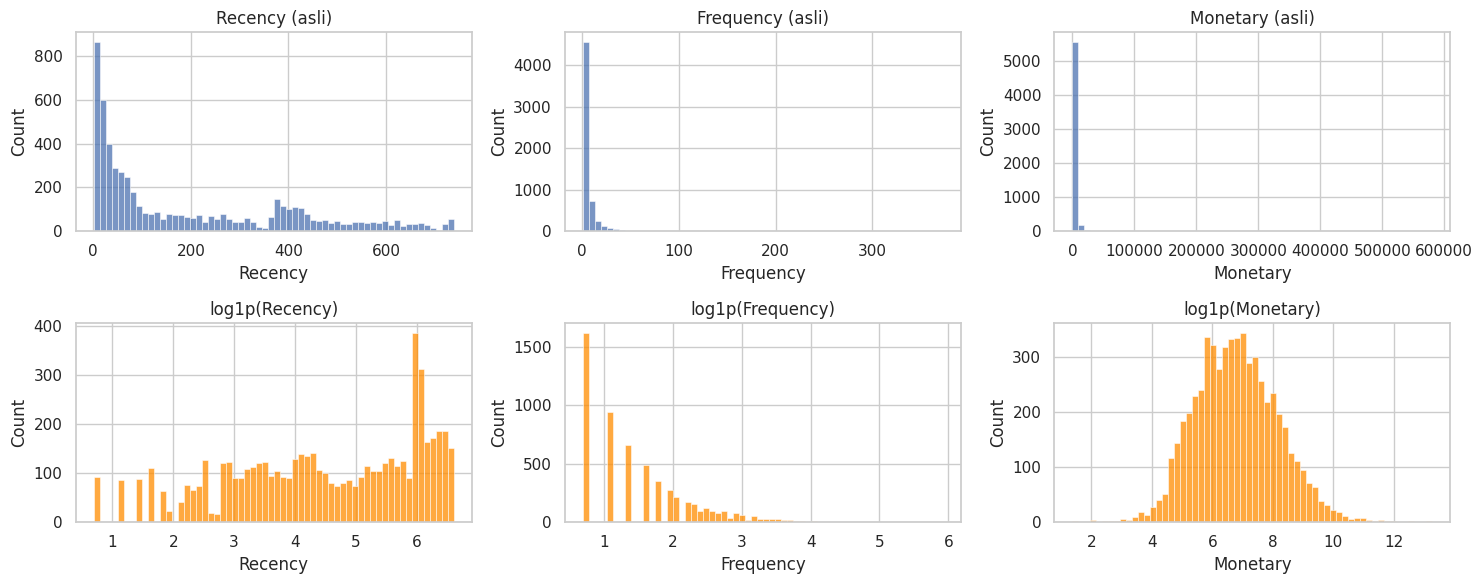

Outlier Monetary (IQR): 619 pelanggan (10.6%) -> dipertahankan, ditangani log1p.


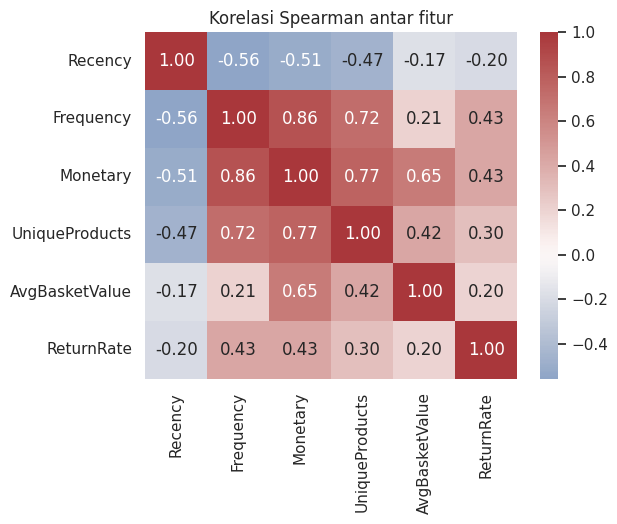

In [ ]:
# ===== C2. FEATURE ENGINEERING: level pelanggan =====
SNAPSHOT = sales["InvoiceDate"].max() + pd.Timedelta(days=1)   # tanggal acuan Recency
print("Snapshot date:", SNAPSHOT.date())

def build_customer_features(sales, returns, snapshot):
    g = sales.groupby("CustomerID")
    cust = pd.DataFrame({
        "Recency":        (snapshot - g["InvoiceDate"].max()).dt.days,
        "Frequency":      g["Invoice"].nunique(),
        "Monetary":       g["TotalPrice"].sum(),
        "UniqueProducts": g["StockCode"].nunique(),
    })
    cust["AvgBasketValue"] = cust["Monetary"] / cust["Frequency"]
    ret_val = returns.groupby("CustomerID")["ReturnValue"].sum()
    cust["ReturnRate"] = (ret_val.reindex(cust.index).fillna(0) / cust["Monetary"]).clip(0, 1)
    require(cust.index.is_unique, "CustomerID tidak unik setelah agregasi.")
    require((cust["Recency"] >= 1).all() and (cust["Monetary"] > 0).all(), "Nilai RFM tidak valid.")
    return cust

cust = build_customer_features(sales, returns, SNAPSHOT)
RFM = ["Recency", "Frequency", "Monetary"]
RFM_PLUS = RFM + ["UniqueProducts", "AvgBasketValue", "ReturnRate"]
LOG_COLS = lambda cols: [c for c in cols if c != "ReturnRate"]   # ReturnRate sudah dalam [0,1]

print(f"Jumlah pelanggan (unit analisis): {len(cust):,}")
display(cust.describe(percentiles=[.25, .5, .75, .95, .99]).T)
print("\nSkewness sebelum vs sesudah transformasi (log1p diterapkan pada semua fitur kecuali ReturnRate):")
_tf = cust[RFM_PLUS].copy(); _tf[LOG_COLS(RFM_PLUS)] = np.log1p(_tf[LOG_COLS(RFM_PLUS)])
display(pd.DataFrame({"skew_asli": cust[RFM_PLUS].skew(), "skew_setelah_transformasi": _tf.skew()}))
print("ReturnRate tetap skewed (mayoritas pelanggan 0 retur) -> keterbatasan varian RFM+, dicatat di temuan.")

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, c in zip(axes[0], RFM):
    sns.histplot(cust[c], bins=60, ax=ax); ax.set_title(f"{c} (asli)")
for ax, c in zip(axes[1], RFM):
    sns.histplot(np.log1p(cust[c]), bins=60, ax=ax, color="darkorange"); ax.set_title(f"log1p({c})")
plt.tight_layout(); plt.show()

q1, q3 = cust["Monetary"].quantile([.25, .75])
n_out = int((cust["Monetary"] > q3 + 1.5 * (q3 - q1)).sum())
print(f"Outlier Monetary (IQR): {n_out} pelanggan ({n_out/len(cust)*100:.1f}%) -> dipertahankan, ditangani log1p.")
corr = cust[RFM_PLUS].corr(method="spearman")
plt.figure(figsize=(6, 4.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Korelasi Spearman antar fitur"); plt.show()


C2b-1. Rekonsiliasi: dari data mentah ke unit analisis


,jumlah
baris data mentah,1067371
baris penjualan sah (setelah C1),776579
pelanggan di data mentah (CustomerID terisi),5942
pelanggan dianalisis (>= 1 penjualan sah),5852
pelanggan tidak dianalisis (tanpa penjualan sah),90


100.0% baris milik pelanggan yang tidak dianalisis adalah retur/nilai tidak valid/non-produk -> hampir seluruhnya bukan perilaku belanja produk, sehingga wajar tidak disegmentasi.


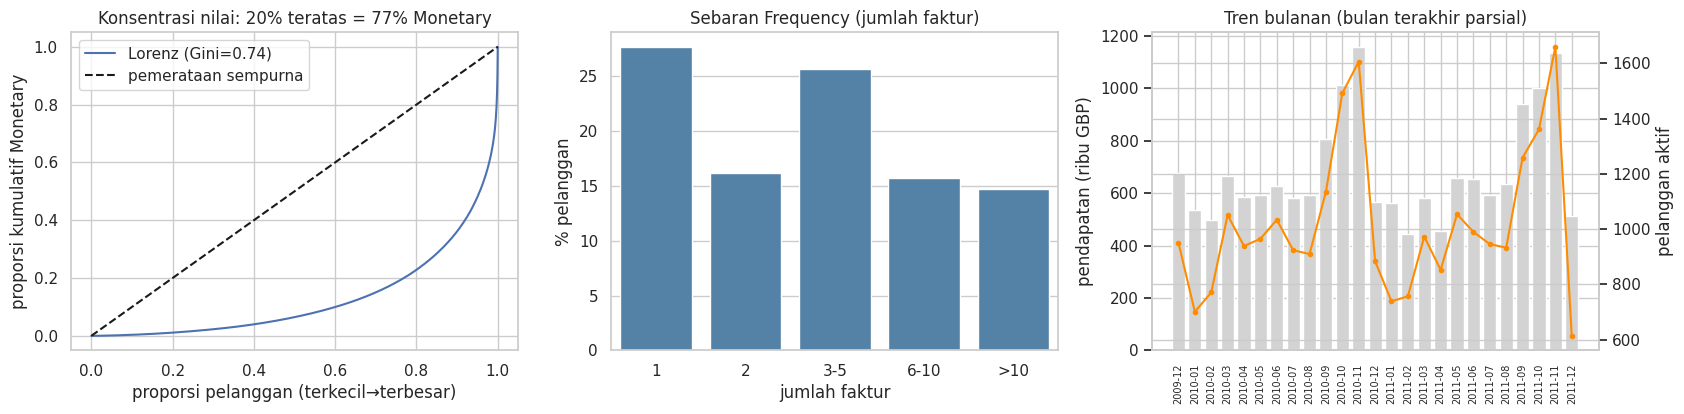


C2b-2. TEMUAN EDA dan implikasinya untuk pemodelan (semua angka dihitung dari data)
1) Nilai pelanggan cukup terkonsentrasi: 10% pelanggan teratas = 63.9% dan 20% teratas = 77.2% total Monetary (Gini=0.74); separuh pelanggan terbawah hanya 6.5%.
   -> Implikasi: segmentasi berbasis nilai bermakna bisnis; nilai ekstrem mencerminkan pelanggan bernilai tinggi (bukan kesalahan data), jadi DIPERTAHANKAN dan ditangani log1p (bukan dibuang).
2) 27.6% pelanggan hanya membeli satu kali (Frequency=1); median Frequency=3.
   -> Implikasi: Frequency sangat miring ke kanan (skew 12.0 -> 1.0 setelah log1p); log1p menurunkan kemiringan sehingga layak dipakai sebelum scaling.
3) 40.7% pelanggan tidak bertransaksi > 180 hari (median Recency=95 hari).
   -> Implikasi: Recency bergantung pada SNAPSHOT (tanggal acuan global); dicatat sebagai keterbatasan; porsi pelanggan tidak aktif besar sehingga kemungkinan membentuk segmen tersendiri.
4) Pendapatan bulanan tertinggi pada 2010-11 (1.9x median bulanan, 

In [ ]:
# ===== C2b. EDA berorientasi masalah: nilai pelanggan, frekuensi, tren waktu, korelasi (+ temuan & implikasi) =====
# Catatan: EDA ini deskriptif (tidak mempelajari parameter dari data), sehingga memakai seluruh pelanggan tanpa risiko leakage.
section("C2b-1. Rekonsiliasi: dari data mentah ke unit analisis")
n_cust_raw = int(raw["CustomerID"].nunique())
display(pd.DataFrame({"jumlah": {
    "baris data mentah": len(raw), "baris penjualan sah (setelah C1)": len(sales),
    "pelanggan di data mentah (CustomerID terisi)": n_cust_raw, "pelanggan dianalisis (>= 1 penjualan sah)": len(cust),
    "pelanggan tidak dianalisis (tanpa penjualan sah)": n_cust_raw - len(cust)}}))
_excl = set(raw["CustomerID"].dropna().astype(int)) - set(cust.index)
if _excl:
    _re = raw[raw["CustomerID"].isin(list(_excl))]
    _bad = (_re["Invoice"].str.upper().str.startswith("C") | (_re["Quantity"] <= 0) | (_re["Price"] <= 0) | _re["StockCode"].str.upper().isin(NON_PRODUCT))
    print(f"{_bad.mean()*100:.1f}% baris milik pelanggan yang tidak dianalisis adalah retur/nilai tidak valid/non-produk"
          + (" -> hampir seluruhnya bukan perilaku belanja produk, sehingga wajar tidak disegmentasi." if _bad.mean() >= 0.95 else "; periksa C1 untuk sisanya."))

# --- nilai pelanggan (Pareto/Lorenz, Gini)
mon_sorted = cust["Monetary"].sort_values(ascending=False)
cum_share = mon_sorted.cumsum() / mon_sorted.sum()
top_share = lambda p: float(cum_share.iloc[int(np.ceil(p * len(mon_sorted))) - 1])
t10, t20, t50 = top_share(.10), top_share(.20), top_share(.50)
bottom50 = float((1 - t50) * 100)      # porsi Monetary milik 50% pelanggan terbawah
_x = np.sort(cust["Monetary"].values); _n = len(_x)
gini = float(2 * np.sum(np.arange(1, _n + 1) * _x) / (_n * _x.sum()) - (_n + 1) / _n)
# --- frekuensi & recency
freq_bins = pd.cut(cust["Frequency"], [0, 1, 2, 5, 10, np.inf], labels=["1", "2", "3-5", "6-10", ">10"])
freq_dist = freq_bins.value_counts(normalize=True).sort_index() * 100
one_time = float((cust["Frequency"] == 1).mean() * 100); inactive = float((cust["Recency"] > 180).mean() * 100)
# --- tren waktu
monthly = sales.groupby(sales["InvoiceDate"].dt.to_period("M")).agg(pendapatan=("TotalPrice", "sum"), pelanggan_aktif=("CustomerID", "nunique"))
_last = sales["InvoiceDate"].max(); _partial = _last.day < _last.days_in_month
full_m = monthly.iloc[:-1] if _partial else monthly
peak_m = full_m["pendapatan"].idxmax(); peak_ratio = float(full_m["pendapatan"].max() / full_m["pendapatan"].median())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
_lx = np.concatenate([[0], np.arange(1, _n + 1) / _n]); _ly = np.concatenate([[0], np.cumsum(_x) / _x.sum()])
ax[0].plot(_lx, _ly, label=f"Lorenz (Gini={gini:.2f})"); ax[0].plot([0, 1], [0, 1], "k--", label="pemerataan sempurna")
ax[0].set_title(f"Konsentrasi nilai: 20% teratas = {t20*100:.0f}% Monetary"); ax[0].set_xlabel("proporsi pelanggan (terkecil→terbesar)"); ax[0].set_ylabel("proporsi kumulatif Monetary"); ax[0].legend()
sns.barplot(x=freq_dist.index.astype(str), y=freq_dist.values, ax=ax[1], color="steelblue"); ax[1].set_title("Sebaran Frequency (jumlah faktur)"); ax[1].set_ylabel("% pelanggan"); ax[1].set_xlabel("jumlah faktur")
ax[2].bar(monthly.index.astype(str), monthly["pendapatan"] / 1e3, color="lightgray"); ax[2].set_ylabel("pendapatan (ribu GBP)"); ax[2].tick_params(axis="x", rotation=90, labelsize=7)
_t = ax[2].twinx(); _t.plot(monthly.index.astype(str), monthly["pelanggan_aktif"], "o-", color="darkorange", ms=3); _t.set_ylabel("pelanggan aktif")
ax[2].set_title("Tren bulanan" + (" (bulan terakhir parsial)" if _partial else ""))
plt.tight_layout(); plt.show()

corr_s = cust[RFM_PLUS].corr(method="spearman")
_pairs = {(a, b): corr_s.loc[a, b] for i, a in enumerate(RFM_PLUS) for b in RFM_PLUS[i + 1:]}
top_pair = max(_pairs, key=lambda p: abs(_pairs[p]))
_sk = cust[RFM_PLUS].skew(); _sk_log = np.log1p(cust[RFM]).skew()

section("C2b-2. TEMUAN EDA dan implikasinya untuk pemodelan (semua angka dihitung dari data)")
_conc = "jauh lebih timpang daripada aturan 80/20" if t20 >= 0.8 else ("cukup terkonsentrasi" if t20 >= 0.6 else "relatif merata")
print(f"1) Nilai pelanggan {_conc}: 10% pelanggan teratas = {t10*100:.1f}% dan 20% teratas = {t20*100:.1f}% total Monetary (Gini={gini:.2f}); separuh pelanggan terbawah hanya {bottom50:.1f}%.")
print("   -> Implikasi: " + ("segmentasi berbasis nilai bermakna bisnis; nilai ekstrem mencerminkan pelanggan bernilai tinggi (bukan kesalahan data), jadi DIPERTAHANKAN dan ditangani log1p (bukan dibuang)." if t20 >= 0.6 else "nilai antar pelanggan relatif merata; keputusan mempertahankan outlier tetap dipakai karena nilai ekstrem bukan kesalahan data."))
print(f"2) {one_time:.1f}% pelanggan hanya membeli satu kali (Frequency=1); median Frequency={cust['Frequency'].median():.0f}.")
print(f"   -> Implikasi: Frequency {'sangat ' if _sk['Frequency'] >= 2 else ''}miring ke kanan (skew {_sk['Frequency']:.1f} -> {_sk_log['Frequency']:.1f} setelah log1p); "
      + ("log1p menurunkan kemiringan sehingga layak dipakai sebelum scaling." if abs(_sk_log["Frequency"]) < abs(_sk["Frequency"]) else "log1p tidak menurunkan kemiringan pada fitur ini."))
print(f"3) {inactive:.1f}% pelanggan tidak bertransaksi > 180 hari (median Recency={cust['Recency'].median():.0f} hari).")
print("   -> Implikasi: Recency bergantung pada SNAPSHOT (tanggal acuan global); dicatat sebagai keterbatasan" + ("; porsi pelanggan tidak aktif besar sehingga kemungkinan membentuk segmen tersendiri." if inactive >= 30 else "."))
_seas = "musiman terlihat jelas" if peak_ratio >= 1.5 else "tidak ada puncak musiman yang kuat"
print(f"4) Pendapatan bulanan tertinggi pada {peak_m} ({peak_ratio:.1f}x median bulanan, bulan lengkap saja) -> {_seas}.")
print("   -> Implikasi: pola musiman dapat memengaruhi Recency/Frequency; fitur musiman belum dibuat dan masuk rencana lanjutan (L3).")
print(f"5) Pasangan fitur paling berkorelasi (Spearman): {top_pair[0]}-{top_pair[1]} = {_pairs[top_pair]:.2f}.")
print("   -> Implikasi: " + ("fitur sebagian redundan -> diuji lewat PCA (I1, I4) dan varian fitur (G4)." if abs(_pairs[top_pair]) >= 0.7 else "tidak ada redundansi kuat antar fitur."))
print(f"6) Dominasi negara: {uk_share:.0f}% baris dari United Kingdom -> hasil belum tentu berlaku untuk pasar lain (keterbatasan).")


In [ ]:
# ===== C3. PREPROCESSOR (dalam Pipeline) + SPLIT PELANGGAN =====
def make_preprocessor(cols):
    log_cols = LOG_COLS(cols)
    ct = ColumnTransformer(
        [("log", FunctionTransformer(np.log1p, validate=False, feature_names_out="one-to-one"), log_cols)],
        remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("log", ct), ("scaler", StandardScaler())])

# Unsupervised tidak punya y, tetapi pembagian pelanggan tetap dilakukan:
# scaler (dan PCA nanti) di-fit HANYA pada train; holdout menguji apakah cluster berlaku untuk pelanggan baru.
train_idx, hold_idx = train_test_split(cust.index, test_size=CFG["TEST_SIZE"], random_state=RS)
cust_tr, cust_ho = cust.loc[train_idx], cust.loc[hold_idx]
print(f"Train: {len(cust_tr):,} pelanggan | Holdout: {len(cust_ho):,} pelanggan")

prep_rfm = make_preprocessor(RFM).fit(cust_tr[RFM])
X_tr = prep_rfm.transform(cust_tr[RFM]); X_ho = prep_rfm.transform(cust_ho[RFM])
print("Data setelah preprocessing (train): shape", X_tr.shape,
      "| mean ~", np.round(X_tr.mean(0), 3), "| std ~", np.round(X_tr.std(0), 3))
display(pd.DataFrame(X_tr[:5], columns=RFM, index=cust_tr.index[:5]).round(3))

Train: 4,681 pelanggan | Holdout: 1,171 pelanggan
Data setelah preprocessing (train): shape (4681, 3) | mean ~ [ 0. -0. -0.] | std ~ [1. 1. 1.]


,Recency,Frequency,Monetary
CustomerID,,,
15778,1.041,-1.060,-0.783
15668,0.605,-1.060,-1.783
18156,-1.159,-0.559,-0.216
15786,-0.382,0.299,1.612
12461,0.388,-1.060,-0.270


## D. Baseline
Baseline = **K-Means dengan konfigurasi awal** (K=3, `k-means++`, `n_init=10`) pada RFM yang sudah di-log dan di-scale. Tujuannya bukan model terbaik, melainkan menjawab: *seberapa baik struktur segmen dapat ditemukan sebelum pengembangan lebih lanjut?* K=3 sengaja belum dioptimalkan; pemilihan K dilakukan di bagian G.

In [ ]:
# ===== Fungsi bantu evaluasi (dipakai di seluruh notebook) =====
def cluster_metrics(X, labels):
    # Metrik internal. Titik noise (-1) dikeluarkan; hasil NaN bila < 2 cluster.
    labels = np.asarray(labels)
    mask = labels != -1
    uniq = np.unique(labels[mask])
    if len(uniq) < 2 or mask.sum() <= len(uniq):
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    Xm, lm = X[mask], labels[mask]
    return dict(silhouette=silhouette_score(Xm, lm),
                davies_bouldin=davies_bouldin_score(Xm, lm),
                calinski_harabasz=calinski_harabasz_score(Xm, lm))

def sil_band(s):
    # Pita interpretasi Kaufman & Rousseeuw (1990) untuk rata-rata silhouette.
    if s >= 0.71: return "kuat"
    if s >= 0.51: return "wajar"
    if s >= 0.26: return "lemah (struktur bisa jadi artifisial/kontinum)"
    return "tidak ada struktur berarti"

def size_table(labels):
    s = pd.Series(labels).value_counts().sort_index()
    return pd.DataFrame({"jumlah": s, "persen": s / s.sum() * 100})

def profile_table(cust_df, labels, cols):
    # Profil cluster dalam SATUAN ASLI (bukan terstandarisasi), sesuai praktik W06.
    d = cust_df[cols].copy(); d["cluster"] = np.asarray(labels)
    prof = d.groupby("cluster").agg(["median"]); prof.columns = [c[0] for c in prof.columns]
    prof.insert(0, "n_pelanggan", d.groupby("cluster").size())
    prof.insert(1, "persen_pelanggan", prof["n_pelanggan"] / len(d) * 100)
    prof["persen_total_Monetary"] = d.groupby("cluster")["Monetary"].sum() / d["Monetary"].sum() * 100
    return prof

K0 = CFG["BASELINE_K"]
t0 = time.time()
base_km = KMeans(n_clusters=K0, init="k-means++", n_init=10, random_state=RS).fit(X_tr)
base_time = time.time() - t0
lab_base_tr = base_km.labels_
lab_base_ho = base_km.predict(X_ho)          # holdout hanya di-transform/predict, TIDAK ikut fit
print(f"Baseline K-Means (K={K0}) selesai dalam {base_time:.2f} detik | inertia = {base_km.inertia_:,.1f} | iterasi = {base_km.n_iter_}")

Baseline K-Means (K=3) selesai dalam 0.11 detik | inertia = 5,086.7 | iterasi = 12


## E. Evaluasi Awal
Minimal untuk Unsupervised: jumlah cluster, ukuran tiap cluster, karakteristik cluster, metrik yang sesuai (Silhouette, ditambah Davies-Bouldin & Calinski-Harabasz).


E1. Jumlah dan ukuran cluster (train)


,jumlah,persen
0,1821,38.902
1,1922,41.060
2,938,20.038



E2. Karakteristik cluster — median dalam satuan asli (train)


,n_pelanggan,persen_pelanggan,Recency,Frequency,Monetary,persen_total_Monetary
cluster,,,,,,
0,1821,38.902,58.000,4.000,"1,189.450",20.614
1,1922,41.060,388.500,1.000,307.865,5.556
2,938,20.038,16.000,13.000,"4,992.985",73.830



E3. Metrik internal: train vs holdout


,train,holdout
silhouette,0.346,0.356
davies_bouldin,1.039,1.035
calinski_harabasz,"4,118.384","1,055.989"


Silhouette: ~+1 cluster rapat & terpisah | ~0 tumpang tindih | <0 kemungkinan salah cluster.
Davies-Bouldin: makin kecil makin baik | Calinski-Harabasz: makin besar makin baik.
Catatan: Calinski-Harabasz bergantung pada jumlah sampel -> tidak sebanding antara train dan holdout yang ukurannya beda; bandingkan Silhouette/DB.


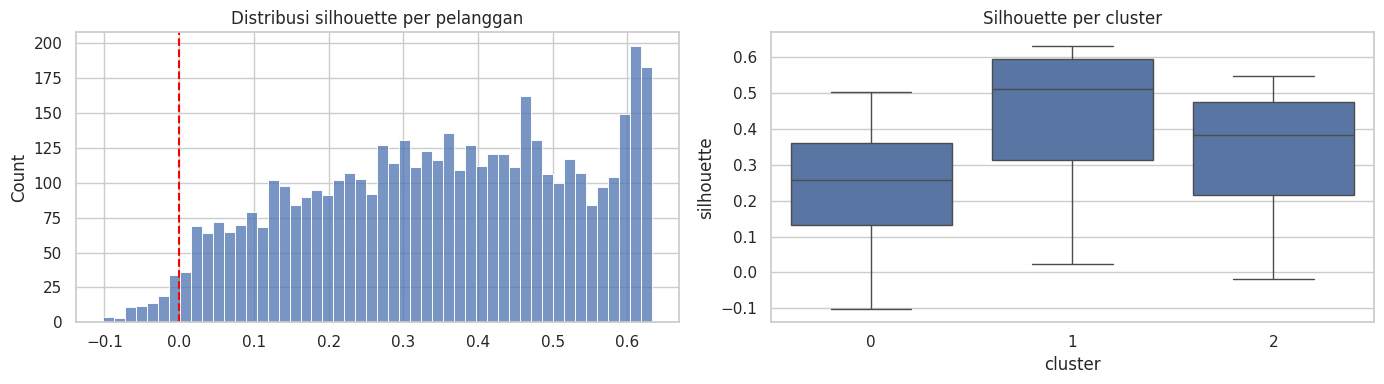

Pelanggan dengan silhouette < 0: 2.0%


In [ ]:
section("E1. Jumlah dan ukuran cluster (train)")
display(size_table(lab_base_tr))

section("E2. Karakteristik cluster — median dalam satuan asli (train)")
prof_base = profile_table(cust_tr, lab_base_tr, RFM)
display(prof_base)

section("E3. Metrik internal: train vs holdout")
m_tr, m_ho = cluster_metrics(X_tr, lab_base_tr), cluster_metrics(X_ho, lab_base_ho)
base_metrics = pd.DataFrame({"train": m_tr, "holdout": m_ho})
display(base_metrics)
print("Silhouette: ~+1 cluster rapat & terpisah | ~0 tumpang tindih | <0 kemungkinan salah cluster.")
print("Davies-Bouldin: makin kecil makin baik | Calinski-Harabasz: makin besar makin baik.")
print("Catatan: Calinski-Harabasz bergantung pada jumlah sampel -> tidak sebanding antara train dan holdout yang ukurannya beda; bandingkan Silhouette/DB.")

# Distribusi silhouette per titik -> mengungkap titik di perbatasan
from sklearn.metrics import silhouette_samples
sil_i = silhouette_samples(X_tr, lab_base_tr)
share_neg = (sil_i < 0).mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(sil_i, bins=50, ax=ax[0]); ax[0].axvline(0, color="red", ls="--"); ax[0].set_title("Distribusi silhouette per pelanggan")
sns.boxplot(data=pd.DataFrame({"silhouette": sil_i, "cluster": lab_base_tr}), x="cluster", y="silhouette", ax=ax[1])
ax[1].set_title("Silhouette per cluster"); plt.tight_layout(); plt.show()
print(f"Pelanggan dengan silhouette < 0: {share_neg:.1f}%")

## F. Temuan Awal (Milestone P3)
Bagian ini dihitung otomatis dari hasil di atas, sehingga angkanya selalu sesuai data yang dipakai.

In [ ]:
sizes = size_table(lab_base_tr)
top_cl = prof_base["persen_total_Monetary"].idxmax()
small_cl = sizes["persen"].idxmin()
cm = cust_tr[RFM].corr(method="spearman")
pairs = {("Recency","Frequency"): cm.loc["Recency","Frequency"], ("Recency","Monetary"): cm.loc["Recency","Monetary"], ("Frequency","Monetary"): cm.loc["Frequency","Monetary"]}
strongest = max(pairs, key=lambda p: abs(pairs[p]))
print("TEMUAN AWAL BASELINE")
print("-" * 90)
print("1) Apa yang berhasil?")
print(f"   - Pipeline end-to-end berjalan; {len(cust):,} pelanggan terbentuk menjadi {K0} segmen dalam {base_time:.2f} detik.")
print(f"   - Cluster {top_cl} ({prof_base.loc[top_cl,'persen_pelanggan']:.1f}% pelanggan) menyumbang {prof_base.loc[top_cl,'persen_total_Monetary']:.1f}% total Monetary: "
      f"median Recency={prof_base.loc[top_cl,'Recency']:.0f} hari, Frequency={prof_base.loc[top_cl,'Frequency']:.0f}, Monetary={prof_base.loc[top_cl,'Monetary']:,.0f}.")
print(f"   - Silhouette train={m_tr['silhouette']:.3f} vs holdout={m_ho['silhouette']:.3f} (selisih {abs(m_tr['silhouette']-m_ho['silhouette']):.3f}) -> struktur yang sama berlaku pada pelanggan yang tidak ikut fit.")
print("2) Masalah yang ditemukan")
print(f"   - Silhouette={m_tr['silhouette']:.3f} -> {sil_band(m_tr['silhouette'])}. Pelanggan membentuk kontinum aktivitas, bukan gumpalan terpisah tegas ({share_neg:.1f}% titik bersilhouette negatif).")
if sizes["persen"].min() < 10:
    print(f"   - Cluster {small_cl} hanya {sizes.loc[small_cl,'persen']:.1f}% pelanggan: periksa apakah segmen bernilai atau artefak outlier.")
else:
    print(f"   - Ukuran cluster relatif seimbang (terkecil {sizes['persen'].min():.1f}%, terbesar {sizes['persen'].max():.1f}%); tidak ada cluster mikro pada K={K0}.")
print(f"   - Pasangan fitur paling berkorelasi: {strongest[0]}-{strongest[1]} (Spearman {pairs[strongest]:.2f}) -> RFM sebagian redundan; segmen cenderung sekadar 'tingkat aktivitas'.")
print("3) Kelemahan baseline")
print("   - K=3 ditetapkan tanpa bukti; K-Means mengasumsikan cluster bulat & berukuran mirip; sensitif inisialisasi dan outlier.")
print("   - Hanya 3 fitur: belum memuat keragaman produk, nilai keranjang, atau perilaku retur.")
print("4) Perlu diperbaiki di tahap berikutnya")
print("   - Memilih K berbasis Elbow+Silhouette+DB+CH; membandingkan Ward, GMM, DBSCAN; menguji kestabilan (multi-seed, CV, subsampel); mencoba fitur RFM+; PCA/t-SNE untuk visualisasi.")

TEMUAN AWAL BASELINE
------------------------------------------------------------------------------------------
1) Apa yang berhasil?
   - Pipeline end-to-end berjalan; 5,852 pelanggan terbentuk menjadi 3 segmen dalam 0.11 detik.
   - Cluster 2 (20.0% pelanggan) menyumbang 73.8% total Monetary: median Recency=16 hari, Frequency=13, Monetary=4,993.
   - Silhouette train=0.346 vs holdout=0.356 (selisih 0.010) -> struktur yang sama berlaku pada pelanggan yang tidak ikut fit.
2) Masalah yang ditemukan
   - Silhouette=0.346 -> lemah (struktur bisa jadi artifisial/kontinum). Pelanggan membentuk kontinum aktivitas, bukan gumpalan terpisah tegas (2.0% titik bersilhouette negatif).
   - Ukuran cluster relatif seimbang (terkecil 20.0%, terbesar 41.1%); tidak ada cluster mikro pada K=3.
   - Pasangan fitur paling berkorelasi: Frequency-Monetary (Spearman 0.86) -> RFM sebagian redundan; segmen cenderung sekadar 'tingkat aktivitas'.
3) Kelemahan baseline
   - K=3 ditetapkan tanpa bukti; K-Means men

## G. Kandidat Model & Perbandingan (Pertemuan 4)
Baseline **dipertahankan** sebagai pembanding. Kandidat: K-Means (K hasil seleksi), Hierarchical-Ward, GMM, DBSCAN. **Seluruh metrik internal dihitung di ruang fitur yang sama** (RFM log+scaled), karena silhouette tidak dapat dibandingkan lintas preprocessing (W06). Keputusan model final belum diambil.

,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct
K,,,,,
2,"6,888.320",0.436,0.878,"4,859.941",39.286
3,"5,086.743",0.346,1.039,"4,118.384",20.038
4,"3,933.483",0.365,0.939,"4,006.863",19.056
5,"3,268.076",0.341,0.949,"3,854.226",8.310
6,"2,851.647",0.328,0.967,"3,669.460",7.904
7,"2,553.803",0.312,0.999,"3,504.623",5.127
8,"2,316.483",0.295,0.998,"3,379.455",5.704
9,"2,114.013",0.295,0.996,"3,295.446",5.191
10,"1,967.330",0.284,1.016,"3,185.703",4.764


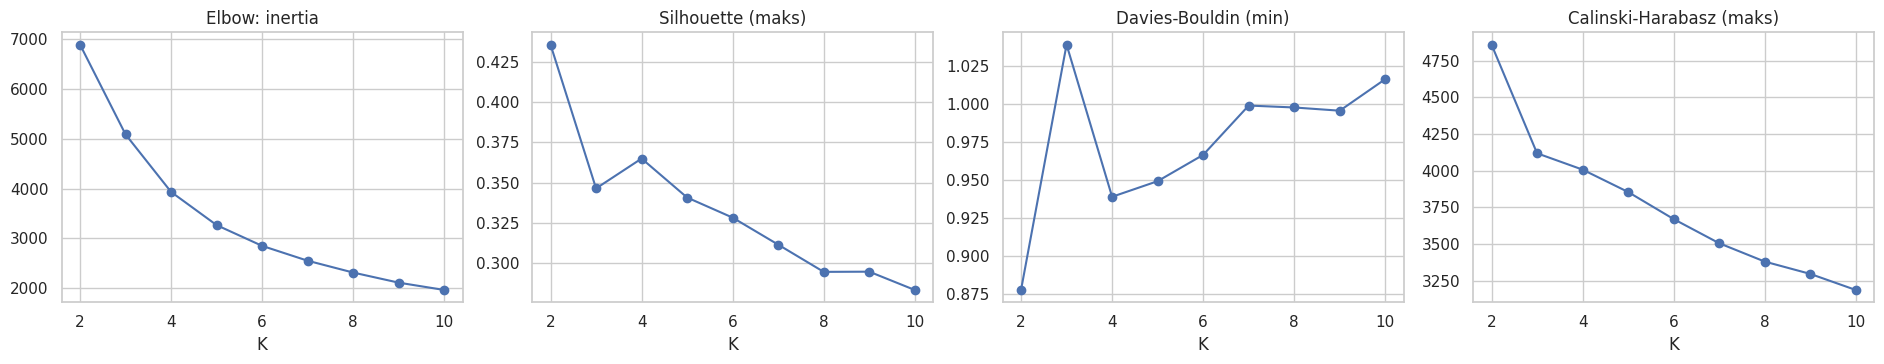

,r_sil,r_db,r_ch,rata_rank
K,,,,
3,2.000,6.000,1.000,3.000
4,1.000,1.000,2.000,1.333
5,3.000,2.000,3.000,2.667
6,4.000,3.000,4.000,3.667
7,5.000,5.000,5.000,5.000
8,6.000,4.000,6.000,5.333


K terbaik per metrik (seluruh rentang): silhouette=2, DB=2, CH=2
K kandidat berdasar konsensus peringkat pada K di [3,8] -> K* = 4  (kandidat untuk eksperimen, BUKAN keputusan final)
PENTING: K=2 unggul secara statistik (silhouette 0.436) tetapi hanya memisahkan 'aktif vs tidak aktif' -> terlalu kasar untuk segmentasi bisnis, sehingga pemilihan dibatasi pada K di [3,8]. Ini keputusan terdokumentasi, bukan kebetulan; K=2 tetap dilaporkan sebagai alternatif.
Catatan: Elbow jarang tajam pada data perilaku; inertia selalu turun saat K naik, sehingga tidak dipakai sendirian.


In [ ]:
# ===== G1. SWEEP K untuk K-Means =====
rows = []
for k in range(CFG["K_MIN"], CFG["K_MAX"] + 1):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RS).fit(X_tr)
    m = cluster_metrics(X_tr, km.labels_)
    rows.append(dict(K=k, inertia=km.inertia_, **m, min_cluster_pct=size_table(km.labels_)["persen"].min()))
ksweep = pd.DataFrame(rows).set_index("K")
display(ksweep)

fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
for a, (col, title) in zip(ax, [("inertia", "Elbow: inertia"), ("silhouette", "Silhouette (maks)"),
                                ("davies_bouldin", "Davies-Bouldin (min)"), ("calinski_harabasz", "Calinski-Harabasz (maks)")]):
    a.plot(ksweep.index, ksweep[col], marker="o"); a.set_title(title); a.set_xlabel("K")
plt.tight_layout(); plt.show()

# Konsensus: rata-rata peringkat tiga metrik pada rentang K yang bermakna secara bisnis
lo, hi = CFG["K_BUSINESS"]
cand = ksweep.loc[lo:hi].copy()
ranks = pd.DataFrame({
    "r_sil": cand["silhouette"].rank(ascending=False),
    "r_db":  cand["davies_bouldin"].rank(ascending=True),
    "r_ch":  cand["calinski_harabasz"].rank(ascending=False),
})
ranks["rata_rank"] = ranks.mean(axis=1)
display(ranks)
K_STAR = int(ranks["rata_rank"].idxmin())
print(f"K terbaik per metrik (seluruh rentang): silhouette={ksweep['silhouette'].idxmax()}, "
      f"DB={ksweep['davies_bouldin'].idxmin()}, CH={ksweep['calinski_harabasz'].idxmax()}")
print(f"K kandidat berdasar konsensus peringkat pada K di [{lo},{hi}] -> K* = {K_STAR}  (kandidat untuk eksperimen, BUKAN keputusan final)")
_best_all = int(ksweep["silhouette"].idxmax())
if _best_all < lo:
    print(f"PENTING: K={_best_all} unggul secara statistik (silhouette {ksweep.loc[_best_all,'silhouette']:.3f}) tetapi hanya memisahkan 'aktif vs tidak aktif' -> terlalu kasar untuk segmentasi bisnis, "
          f"sehingga pemilihan dibatasi pada K di [{lo},{hi}]. Ini keputusan terdokumentasi, bukan kebetulan; K={_best_all} tetap dilaporkan sebagai alternatif.")
print("Catatan: Elbow jarang tajam pada data perilaku; inertia selalu turun saat K naik, sehingga tidak dipakai sendirian.")

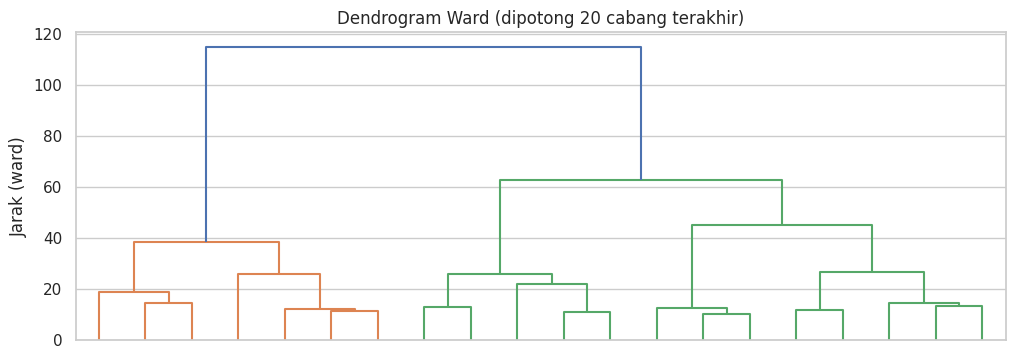

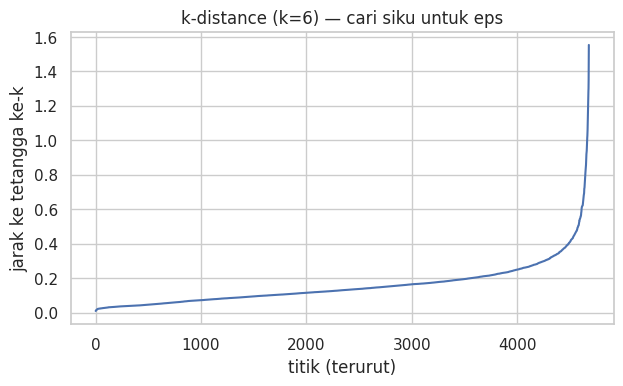

,kuantil,eps,n_cluster,noise_pct,silhouette_non_noise
0,0.800,0.216,17,12.519,-0.044
1,0.900,0.289,6,5.683,0.057
2,0.950,0.373,2,2.841,0.277
3,0.980,0.519,1,1.090,NaN


eps terpilih = 0.373  (memenuhi syarat >=2 cluster & noise<=10%)


In [ ]:
# ===== G2. Kandidat: Ward, GMM, DBSCAN =====
# --- Dendrogram (Ward) untuk intuisi jumlah cluster ---
Z = linkage(X_tr, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=20, show_leaf_counts=True, no_labels=True)
plt.title("Dendrogram Ward (dipotong 20 cabang terakhir)"); plt.ylabel("Jarak (ward)"); plt.show()

# --- DBSCAN: eps dipilih dari grafik k-distance ---
MIN_SAMPLES = 2 * X_tr.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_tr).kneighbors(X_tr)[0][:, -1])
plt.figure(figsize=(7, 3.8)); plt.plot(kdist); plt.title(f"k-distance (k={MIN_SAMPLES}) — cari siku untuk eps")
plt.xlabel("titik (terurut)"); plt.ylabel("jarak ke tetangga ke-k"); plt.show()

db_rows = []
for q in [0.80, 0.90, 0.95, 0.98]:
    eps = float(np.quantile(kdist, q))
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_tr)
    ncl = len(set(lab)) - (1 if -1 in lab else 0)
    m = cluster_metrics(X_tr, lab)
    db_rows.append(dict(kuantil=q, eps=eps, n_cluster=ncl, noise_pct=(lab == -1).mean() * 100, silhouette_non_noise=m["silhouette"]))
db_sweep = pd.DataFrame(db_rows); display(db_sweep)
ok = db_sweep[(db_sweep["n_cluster"] >= 2) & (db_sweep["noise_pct"] <= 10)]
EPS_STAR = float(ok.sort_values("silhouette_non_noise", ascending=False).iloc[0]["eps"]) if len(ok) else float(np.quantile(kdist, 0.95))
print(f"eps terpilih = {EPS_STAR:.3f}  ({'memenuhi' if len(ok) else 'fallback: tidak ada eps yang memenuhi'} syarat >=2 cluster & noise<=10%)")

In [ ]:
# ===== G3. Perbandingan adil: metrik sama, ruang fitur sama, plus kestabilan subsampel =====
def subsample_stability(factory, X, n_rep, frac, seed):
    # Dua subsampel acak independen -> clustering terpisah -> ARI pada titik yang beririsan.
    rng = np.random.default_rng(seed); n = len(X); m = int(frac * n); scores = []
    for _ in range(n_rep):
        i1, i2 = rng.choice(n, m, replace=False), rng.choice(n, m, replace=False)
        l1, l2 = factory().fit_predict(X[i1]), factory().fit_predict(X[i2])
        f1, f2 = np.full(n, -9), np.full(n, -9); f1[i1], f2[i2] = l1, l2
        both = np.intersect1d(i1, i2)
        scores.append(adjusted_rand_score(f1[both], f2[both]))
    return float(np.mean(scores)), float(np.std(scores))

factories = {
    f"K-Means K={K0} (baseline)": lambda: KMeans(K0, n_init=10, random_state=RS),
    f"K-Means K={K_STAR}":        lambda: KMeans(K_STAR, n_init=10, random_state=RS),
    f"Ward K={K_STAR}":           lambda: AgglomerativeClustering(n_clusters=K_STAR, linkage="ward"),
    f"GMM K={K_STAR}":            lambda: GaussianMixture(n_components=K_STAR, covariance_type="full", n_init=3, random_state=RS),
    f"DBSCAN eps={EPS_STAR:.2f}": lambda: DBSCAN(eps=EPS_STAR, min_samples=MIN_SAMPLES),
}
ref_name = f"K-Means K={K_STAR}"
labels_tr, fit_time = {}, {}
for name, f in factories.items():
    t0 = time.time(); labels_tr[name] = f().fit_predict(X_tr); fit_time[name] = time.time() - t0

rows = []
for name, f in factories.items():
    lab = labels_tr[name]; m = cluster_metrics(X_tr, lab)
    stab_m, stab_s = subsample_stability(f, X_tr, CFG["N_SUBSAMPLE"], CFG["SUBSAMPLE_FRAC"], RS)
    sz = size_table(lab[lab != -1]) if (lab != -1).any() else None
    rows.append({
        "model": name,
        "n_cluster": len(set(lab)) - (1 if -1 in lab else 0),
        "noise_%": (lab == -1).mean() * 100,
        "silhouette": m["silhouette"], "davies_bouldin": m["davies_bouldin"], "calinski_harabasz": m["calinski_harabasz"],
        "cluster_terkecil_%": sz["persen"].min() if sz is not None else np.nan,
        "cluster_terbesar_%": sz["persen"].max() if sz is not None else np.nan,
        f"ARI vs {ref_name}": adjusted_rand_score(labels_tr[ref_name], lab),
        "stabilitas_ARI_mean": stab_m, "stabilitas_ARI_std": stab_s,
        "waktu_fit_s": fit_time[name],
    })
compare = pd.DataFrame(rows).set_index("model")
display(compare)
print("Catatan: DBSCAN dinilai pada titik non-noise saja; ARI menghitung noise sebagai satu label sendiri.")

,n_cluster,noise_%,silhouette,davies_bouldin,calinski_harabasz,cluster_terkecil_%,cluster_terbesar_%,ARI vs K-Means K=4,stabilitas_ARI_mean,stabilitas_ARI_std,waktu_fit_s
model,,,,,,,,,,,
K-Means K=3 (baseline),3,0.000,0.346,1.039,"4,118.384",20.038,41.060,0.622,0.935,0.037,0.033
K-Means K=4,4,0.000,0.365,0.939,"4,006.863",19.056,34.715,1.000,0.949,0.056,0.039
Ward K=4,4,0.000,0.306,0.938,"3,374.052",14.185,33.711,0.642,0.472,0.084,0.629
GMM K=4,4,0.000,0.214,1.156,"2,403.233",16.108,37.620,0.337,0.877,0.154,0.459
DBSCAN eps=0.37,2,2.841,0.277,1.013,"2,255.014",27.617,72.383,0.131,0.980,0.005,0.096


Catatan: DBSCAN dinilai pada titik non-noise saja; ARI menghitung noise sebagai satu label sendiri.


In [ ]:
# ===== G3b. Hierarchical: pengaruh pilihan linkage (W06: bentuk cluster bergantung linkage) =====
section("G3b. Hierarchical clustering — perbandingan linkage pada K* (ruang fitur yang sama)")
rows = []
for lk in ["ward", "complete", "average", "single"]:
    t0 = time.time(); lab = AgglomerativeClustering(n_clusters=K_STAR, linkage=lk).fit_predict(X_tr); dt = time.time() - t0
    m = cluster_metrics(X_tr, lab); sz = size_table(lab)["persen"]
    rows.append({"linkage": lk, "silhouette": m["silhouette"], "davies_bouldin": m["davies_bouldin"],
                 "cluster_terkecil_%": sz.min(), "cluster_terbesar_%": sz.max(),
                 f"ARI vs {ref_name}": adjusted_rand_score(labels_tr[ref_name], lab), "waktu_fit_s": dt})
linkage_cmp = pd.DataFrame(rows).set_index("linkage"); display(linkage_cmp)
_micro = linkage_cmp.index[linkage_cmp["cluster_terkecil_%"] < 1].tolist()
if _micro:
    print(f"Linkage {_micro} membentuk cluster mikro (<1% pelanggan): gejala 'chaining' (cluster memanjang menelan titik satu per satu) -> tidak cocok untuk segmentasi bisnis.")
else:
    print("Tidak ada linkage yang membentuk cluster mikro (<1%) pada K*; perbedaan antar linkage terutama pada keseimbangan ukuran dan kesepakatan dengan K-Means.")
print("Ward dipertahankan sebagai wakil Hierarchical di G3 (varians terkecil -> cluster bulat, paling umum; W06). Silhouette valid dibandingkan di sini karena ruang fiturnya sama.")



G3b. Hierarchical clustering — perbandingan linkage pada K* (ruang fitur yang sama)


,silhouette,davies_bouldin,cluster_terkecil_%,cluster_terbesar_%,ARI vs K-Means K=4,waktu_fit_s
linkage,,,,,,
ward,0.306,0.938,14.185,33.711,0.642,0.620
complete,0.206,1.209,5.213,41.957,0.218,0.603
average,0.317,0.780,0.513,72.314,0.260,0.688
single,0.115,0.652,0.021,99.872,0.000,0.167


Linkage ['average', 'single'] membentuk cluster mikro (<1% pelanggan): gejala 'chaining' (cluster memanjang menelan titik satu per satu) -> tidak cocok untuk segmentasi bisnis.
Ward dipertahankan sebagai wakil Hierarchical di G3 (varians terkecil -> cluster bulat, paling umum; W06). Silhouette valid dibandingkan di sini karena ruang fiturnya sama.


In [ ]:
# ===== G4. Varian fitur RFM+ (feature engineering W02) =====
prep_plus = make_preprocessor(RFM_PLUS).fit(cust_tr[RFM_PLUS])
Xp_tr, Xp_ho = prep_plus.transform(cust_tr[RFM_PLUS]), prep_plus.transform(cust_ho[RFM_PLUS])
km_plus = KMeans(K_STAR, n_init=10, random_state=RS).fit(Xp_tr)
lab_plus_tr = km_plus.labels_
stab_plus = subsample_stability(lambda: KMeans(K_STAR, n_init=10, random_state=RS), Xp_tr, CFG["N_SUBSAMPLE"], CFG["SUBSAMPLE_FRAC"], RS)
mp = cluster_metrics(Xp_tr, lab_plus_tr)
variant = pd.DataFrame({
    "RFM (3 fitur)":  {"silhouette": compare.loc[ref_name, "silhouette"],
                       "stabilitas_ARI": compare.loc[ref_name, "stabilitas_ARI_mean"], "ARI antar varian": np.nan},
    "RFM+ (6 fitur)": {"silhouette": mp["silhouette"], "stabilitas_ARI": stab_plus[0],
                       "ARI antar varian": adjusted_rand_score(labels_tr[ref_name], lab_plus_tr)},
}).T
display(variant)
print("PERINGATAN: silhouette RFM vs RFM+ dihitung di ruang fitur berbeda -> TIDAK boleh dibandingkan langsung (W06).")
print("Pembanding yang sah: kestabilan, ARI antar partisi, profil cluster, dan kebermaknaan bisnis.")
prof_plus = profile_table(cust_tr, lab_plus_tr, RFM_PLUS); display(prof_plus)
_mc = prof_plus["persen_pelanggan"].idxmin()
print(f"Cluster terkecil RFM+: cluster {_mc} ({prof_plus.loc[_mc,'persen_pelanggan']:.1f}% pelanggan) dengan median ReturnRate={prof_plus.loc[_mc,'ReturnRate']:.2f} "
      "-> fitur retur memunculkan segmen mikro yang tidak terlihat pada RFM; layak ditinjau (risiko/pelanggan retur tinggi).")

,silhouette,stabilitas_ARI,ARI antar varian
RFM (3 fitur),0.365,0.949,NaN
RFM+ (6 fitur),0.253,0.918,0.369


PERINGATAN: silhouette RFM vs RFM+ dihitung di ruang fitur berbeda -> TIDAK boleh dibandingkan langsung (W06).
Pembanding yang sah: kestabilan, ARI antar partisi, profil cluster, dan kebermaknaan bisnis.


,n_pelanggan,persen_pelanggan,Recency,Frequency,Monetary,UniqueProducts,AvgBasketValue,ReturnRate,persen_total_Monetary
cluster,,,,,,,,,
0,2050,43.794,110.000,3.000,958.670,50.000,327.310,0.000,18.665
1,1157,24.717,18.000,12.000,"4,234.530",162.000,354.466,0.009,77.392
2,53,1.132,301.000,2.000,385.190,11.000,194.375,0.498,1.363
3,1421,30.357,376.000,1.000,226.420,13.000,157.860,0.000,2.580


Cluster terkecil RFM+: cluster 2 (1.1% pelanggan) dengan median ReturnRate=0.50 -> fitur retur memunculkan segmen mikro yang tidak terlihat pada RFM; layak ditinjau (risiko/pelanggan retur tinggi).


In [ ]:
# ===== G5. Interpretasi perbandingan kandidat =====
km_row = compare.loc[ref_name]; ward_row = compare.loc[f"Ward K={K_STAR}"]; gmm_row = compare.loc[f"GMM K={K_STAR}"]
db_name = [n for n in compare.index if n.startswith("DBSCAN")][0]; db_row = compare.loc[db_name]
print("PERBANDINGAN AWAL (Pertemuan 4)")
print("-" * 90)
print(f"- Baseline K={K0} vs K*={K_STAR}: silhouette {compare.iloc[0]['silhouette']:.3f} -> {km_row['silhouette']:.3f}; DB {compare.iloc[0]['davies_bouldin']:.3f} -> {km_row['davies_bouldin']:.3f}. "
      "Perbedaan K mengubah granularitas segmen, bukan 'benar/salah'.")
print(f"- Ward dan K-Means sepakat sebesar ARI={ward_row[f'ARI vs {ref_name}']:.3f}; GMM vs K-Means ARI={gmm_row[f'ARI vs {ref_name}']:.3f}. "
      "Nilai tinggi = data tidak peka terhadap pilihan algoritma; nilai rendah = batas antar segmen kabur.")
print(f"- DBSCAN: {int(db_row['n_cluster'])} cluster dengan noise {db_row['noise_%']:.1f}% -> {'cocok sebagai detektor pelanggan ekstrem' if db_row['n_cluster']<=2 else 'menemukan struktur padat'}; "
      "data RFM berbentuk kontinum padat sehingga DBSCAN cenderung menggabungkan hampir semua titik.")
same_k = compare[compare["n_cluster"] == K_STAR]
best_same = same_k["stabilitas_ARI_mean"].idxmax()
print(f"- Stabilitas subsampel pada granularitas sama (K={K_STAR}): terbaik {best_same} (ARI={same_k.loc[best_same,'stabilitas_ARI_mean']:.3f}); "
      f"terendah {same_k['stabilitas_ARI_mean'].idxmin()} (ARI={same_k['stabilitas_ARI_mean'].min():.3f}).")
if db_row["n_cluster"] < K_STAR:
    print(f"- DBSCAN tampak sangat stabil (ARI={db_row['stabilitas_ARI_mean']:.3f}) hanya karena membentuk {int(db_row['n_cluster'])} cluster kasar; stabilitas tidak boleh dibaca terlepas dari jumlah cluster dan kebermaknaan bisnis.")
print("- Metrik paling informatif: Silhouette + kestabilan (ARI); Elbow tidak tegas; CH cenderung condong ke K tertentu. Interpretasi bisnis menjadi penentu akhir.")

PERBANDINGAN AWAL (Pertemuan 4)
------------------------------------------------------------------------------------------
- Baseline K=3 vs K*=4: silhouette 0.346 -> 0.365; DB 1.039 -> 0.939. Perbedaan K mengubah granularitas segmen, bukan 'benar/salah'.
- Ward dan K-Means sepakat sebesar ARI=0.642; GMM vs K-Means ARI=0.337. Nilai tinggi = data tidak peka terhadap pilihan algoritma; nilai rendah = batas antar segmen kabur.
- DBSCAN: 2 cluster dengan noise 2.8% -> cocok sebagai detektor pelanggan ekstrem; data RFM berbentuk kontinum padat sehingga DBSCAN cenderung menggabungkan hampir semua titik.
- Stabilitas subsampel pada granularitas sama (K=4): terbaik K-Means K=4 (ARI=0.949); terendah Ward K=4 (ARI=0.472).
- DBSCAN tampak sangat stabil (ARI=0.980) hanya karena membentuk 2 cluster kasar; stabilitas tidak boleh dibaca terlepas dari jumlah cluster dan kebermaknaan bisnis.
- Metrik paling informatif: Silhouette + kestabilan (ARI); Elbow tidak tegas; CH cenderung condong ke K tertentu

**Kelebihan, kelemahan, dan alasan pemilihan kandidat (catatan Pertemuan 4):**

| Model | Kelebihan | Kelemahan | Cocok untuk | Alasan dipilih untuk data RFM ini |
|---|---|---|---|---|
| K-Means | Cepat, sederhana, skala besar | Perlu K; asumsi bulat; sensitif outlier & inisialisasi | Baseline & segmentasi operasional | Praktik standar segmentasi RFM; mudah dijelaskan |
| Ward | Tidak bergantung inisialisasi; dendrogram | O(n²) memori; tidak ada `predict` untuk data baru | Eksplorasi data kecil-menengah | Menguji apakah partisi bergantung pada algoritma, tanpa inisialisasi acak |
| GMM | Keanggotaan probabilistik; bentuk elips | Lebih lambat; asumsi Gaussian | Pelanggan di perbatasan segmen | Batas segmen pelanggan cenderung kabur; keanggotaan *soft* relevan |
| DBSCAN | Tanpa K; mendeteksi noise | Sensitif `eps`; kesulitan kerapatan beragam | Pencarian pelanggan ekstrem/anomali | Memeriksa bentuk non-bulat dan pelanggan ekstrem (grosir) tanpa menetapkan K |

## H. Validasi & Kestabilan (Pertemuan 5)

### H1. Audit strategi validasi
| Pertanyaan | Jawaban di notebook ini |
|---|---|
| Bagaimana data dibagi? | Pelanggan dibagi acak **80% train / 20% holdout** (`random_state=42`). Train dipakai fit & seleksi; holdout hanya untuk konfirmasi. |
| Perlu validation set? | Ya, untuk memilih K/metode. Dipenuhi oleh **5-Fold CV di dalam train** (bukan holdout), sehingga holdout tidak dipakai berulang. |
| Sesuai jenis masalah? | Unsupervised → tanpa stratifikasi (tidak ada kelas); dipakai `KFold` acak per pelanggan. |
| Preprocessing hanya dari train? | Ya: `log1p` + `StandardScaler` berada di **Pipeline**; di CV dipelajari ulang pada tiap fold-train. |
| Test dipakai berulang? | Tidak: holdout hanya dipakai pada konfirmasi akhir. |
| Keterbatasan | Fitur RFM memakai tanggal acuan global (`SNAPSHOT`); tidak ada label sehingga tidak ada *target leakage*, tetapi pelanggan yang sama tidak boleh muncul di dua fold (sudah terjamin: 1 baris = 1 pelanggan). |
| Metrik apa dan mengapa? | **Silhouette** (kohesi vs separasi; skala −1..1 mudah ditafsirkan), **Davies-Bouldin** (sebaran dalam cluster dibanding jarak antar pusat; makin kecil makin baik), dan **Calinski-Harabasz** (rasio varians antar/dalam cluster): tiga sudut pandang internal karena tidak ada label. **ARI** antar fold/subsampel/seed mengukur **kestabilan** (tidak terpengaruh penomoran cluster). Metrik eksternal (ARI/NMI terhadap label) tidak dipakai karena tidak ada label. |
| Risiko leakage lain? | Pembersihan data deterministik (bukan leakage); scaler/PCA hanya di-fit pada train lewat Pipeline; holdout tidak dipakai memilih K atau metode; `SNAPSHOT` global dicatat sebagai keterbatasan. |

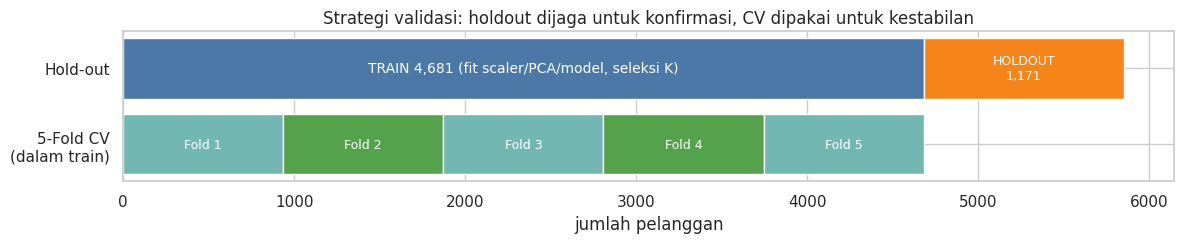

In [ ]:
# Diagram pembagian data
fig, ax = plt.subplots(figsize=(12, 2.6))
n_all, n_tr, n_ho = len(cust), len(cust_tr), len(cust_ho)
ax.barh(1, n_tr, color="#4C78A8"); ax.barh(1, n_ho, left=n_tr, color="#F58518")
ax.text(n_tr / 2, 1, f"TRAIN {n_tr:,} (fit scaler/PCA/model, seleksi K)", ha="center", va="center", color="white", fontsize=10)
ax.text(n_tr + n_ho / 2, 1, f"HOLDOUT\n{n_ho:,}", ha="center", va="center", color="white", fontsize=9)
fold = n_tr / CFG["N_FOLDS"]
for i in range(CFG["N_FOLDS"]):
    ax.barh(0, fold, left=i * fold, color="#72B7B2" if i % 2 == 0 else "#54A24B", edgecolor="white")
    ax.text(i * fold + fold / 2, 0, f"Fold {i+1}", ha="center", va="center", color="white", fontsize=9)
ax.set_yticks([0, 1]); ax.set_yticklabels(["5-Fold CV\n(dalam train)", "Hold-out"]); ax.set_xlabel("jumlah pelanggan")
ax.set_title("Strategi validasi: holdout dijaga untuk konfirmasi, CV dipakai untuk kestabilan"); plt.tight_layout(); plt.show()

In [ ]:
# ===== H2. KESTABILAN: 5-Fold CV (Pipeline di-fit ulang pada tiap fold) =====
def make_km_pipeline(cols, k, n_init=10):
    return Pipeline([("prep", make_preprocessor(cols)), ("km", KMeans(k, n_init=n_init, random_state=RS))])

def cv_cluster_stability(cols, k, df_tr, n_folds):
    ref = make_km_pipeline(cols, k).fit(df_tr[cols])                       # referensi: model dari seluruh train
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RS); out = []
    for i, (a, b) in enumerate(kf.split(df_tr), 1):
        fold_tr, fold_val = df_tr.iloc[a], df_tr.iloc[b]
        pipe = make_km_pipeline(cols, k).fit(fold_tr[cols])                # scaler & KMeans HANYA dari fold-train
        Xv = pipe.named_steps["prep"].transform(fold_val[cols]); lv = pipe.named_steps["km"].predict(Xv)
        m = cluster_metrics(Xv, lv)
        out.append({"Fold": f"Fold {i}", "silhouette": m["silhouette"], "davies_bouldin": m["davies_bouldin"],
                    "ARI vs model train penuh": adjusted_rand_score(ref.predict(fold_val[cols]), lv)})
    t = pd.DataFrame(out).set_index("Fold")
    summ = pd.DataFrame({"Rata-rata": t.mean(), "Standar Deviasi": t.std(ddof=1)}).T
    return pd.concat([t, summ])

for k in sorted({K0, K_STAR}):
    section(f"H2. 5-Fold CV — K-Means K={k} (RFM)")
    res = cv_cluster_stability(RFM, k, cust_tr, CFG["N_FOLDS"]); display(res)
    cv_last = res


H2. 5-Fold CV — K-Means K=3 (RFM)


,silhouette,davies_bouldin,ARI vs model train penuh
Fold 1,0.356,1.021,0.970
Fold 2,0.349,1.034,0.960
Fold 3,0.320,1.097,0.960
Fold 4,0.357,1.029,0.934
Fold 5,0.341,1.040,0.906
Rata-rata,0.345,1.044,0.946
Standar Deviasi,0.015,0.030,0.026



H2. 5-Fold CV — K-Means K=4 (RFM)


,silhouette,davies_bouldin,ARI vs model train penuh
Fold 1,0.371,0.934,0.992
Fold 2,0.369,0.938,0.983
Fold 3,0.345,0.946,0.988
Fold 4,0.373,0.923,0.960
Fold 5,0.358,0.948,0.893
Rata-rata,0.363,0.938,0.963
Standar Deviasi,0.012,0.010,0.041


In [ ]:
# ===== H3. KESTABILAN: banyak seed (inisialisasi) =====
def seed_stability(X, k, init, n_init, seeds):
    labs, inert = [], []
    for s in seeds:
        km = KMeans(k, init=init, n_init=n_init, random_state=s).fit(X); labs.append(km.labels_); inert.append(km.inertia_)
    aris = [adjusted_rand_score(labs[0], l) for l in labs[1:]]
    return dict(inertia_mean=np.mean(inert), inertia_std=np.std(inert), inertia_terburuk=np.max(inert),
                ARI_vs_seed0_mean=np.mean(aris), ARI_vs_seed0_min=np.min(aris))

seeds = list(range(CFG["N_SEEDS"]))
rows = {}
for k in sorted({K0, K_STAR}):
    rows[f"K={k} | random, n_init=1"]    = seed_stability(X_tr, k, "random", 1, seeds)
    rows[f"K={k} | k-means++, n_init=1"] = seed_stability(X_tr, k, "k-means++", 1, seeds)
    rows[f"K={k} | k-means++, n_init=10"] = seed_stability(X_tr, k, "k-means++", 10, seeds)
seed_tab = pd.DataFrame(rows).T; display(seed_tab)
print("Praktik yang direkomendasikan (W06): k-means++ dengan n_init > 1 dan ambil inertia terkecil.")

,inertia_mean,inertia_std,inertia_terburuk,ARI_vs_seed0_mean,ARI_vs_seed0_min
"K=3 | random, n_init=1","5,087.341",0.498,"5,087.924",0.951,0.894
"K=3 | k-means++, n_init=1","5,087.273",0.554,"5,088.016",0.941,0.894
"K=3 | k-means++, n_init=10","5,086.756",0.044,"5,086.803",0.971,0.931
"K=4 | random, n_init=1","3,935.069",1.049,"3,935.886",0.930,0.906
"K=4 | k-means++, n_init=1","3,978.312",131.342,"4,372.324",0.900,0.499
"K=4 | k-means++, n_init=10","3,933.452",0.016,"3,933.470",0.999,0.998


Praktik yang direkomendasikan (W06): k-means++ dengan n_init > 1 dan ambil inertia terkecil.


In [ ]:
# ===== H4. Konfirmasi pada HOLDOUT (dipakai sekali) =====
final_km = KMeans(K_STAR, n_init=20, random_state=RS).fit(X_tr)
lab_fin_tr, lab_fin_ho = final_km.labels_, final_km.predict(X_ho)
conf = pd.DataFrame({"train": cluster_metrics(X_tr, lab_fin_tr), "holdout": cluster_metrics(X_ho, lab_fin_ho)})
display(conf)
print("(Calinski-Harabasz tidak sebanding antar ukuran sampel; gunakan Silhouette/DB untuk membandingkan train vs holdout.)")
dist_tr = size_table(lab_fin_tr)["persen"]; dist_ho = size_table(lab_fin_ho)["persen"]
display(pd.DataFrame({"train_%": dist_tr, "holdout_%": dist_ho, "selisih_pp": dist_ho - dist_tr}))

,train,holdout
silhouette,0.365,0.376
davies_bouldin,0.939,0.930
calinski_harabasz,"4,006.891","1,015.032"


(Calinski-Harabasz tidak sebanding antar ukuran sampel; gunakan Silhouette/DB untuk membandingkan train vs holdout.)


,train_%,holdout_%,selisih_pp
0,19.056,18.787,-0.268
1,34.672,36.038,1.365
2,25.166,23.655,-1.511
3,21.107,21.520,0.413


In [ ]:
# ===== H5. Interpretasi kestabilan, ensemble, dan keseimbangan cluster =====
stab_final = cv_cluster_stability(RFM, K_STAR, cust_tr, CFG["N_FOLDS"])
ari_mean, ari_std = stab_final.loc["Rata-rata", "ARI vs model train penuh"], stab_final.loc["Standar Deviasi", "ARI vs model train penuh"]
sil_mean, sil_std = stab_final.loc["Rata-rata", "silhouette"], stab_final.loc["Standar Deviasi", "silhouette"]
verdict = "stabil" if ari_mean >= 0.8 else ("cukup stabil" if ari_mean >= 0.6 else "kurang stabil")
print("INTERPRETASI PERTEMUAN 5")
print("-" * 90)
print(f"1) Kestabilan: K={K_STAR} -> ARI antar-fold {ari_mean:.3f} ± {ari_std:.3f}, silhouette fold {sil_mean:.3f} ± {sil_std:.3f} => segmentasi {verdict} (patokan heuristik: ARI>=0.8 stabil, 0.6-0.8 cukup).")
print(f"2) Generalisasi: silhouette train {conf.loc['silhouette','train']:.3f} vs holdout {conf.loc['silhouette','holdout']:.3f}; komposisi cluster holdout berbeda maks {np.abs(dist_ho - dist_tr).max():.1f} poin persentase.")
print("3) Ensemble: tidak relevan sebagai 'peningkat akurasi' karena tidak ada target. Yang dipakai: perbandingan metode (G3) & uji multi-seed; ARI antar metode = ukuran konsensus.")
print("4) Imbalance: bukan klasifikasi; yang diperiksa adalah keseimbangan UKURAN cluster. Cluster kecil dengan kontribusi Monetary besar = segmen bernilai (mis. grosir), bukan noise.")
print("5) Keterbatasan: satu periode data, RFM mengabaikan kategori produk/musiman, 'ground truth' tidak ada, pelanggan tanpa ID tidak tercakup.")

INTERPRETASI PERTEMUAN 5
------------------------------------------------------------------------------------------
1) Kestabilan: K=4 -> ARI antar-fold 0.963 ± 0.041, silhouette fold 0.363 ± 0.012 => segmentasi stabil (patokan heuristik: ARI>=0.8 stabil, 0.6-0.8 cukup).
2) Generalisasi: silhouette train 0.365 vs holdout 0.376; komposisi cluster holdout berbeda maks 1.5 poin persentase.
3) Ensemble: tidak relevan sebagai 'peningkat akurasi' karena tidak ada target. Yang dipakai: perbandingan metode (G3) & uji multi-seed; ARI antar metode = ukuran konsensus.
4) Imbalance: bukan klasifikasi; yang diperiksa adalah keseimbangan UKURAN cluster. Cluster kecil dengan kontribusi Monetary besar = segmen bernilai (mis. grosir), bukan noise.
5) Keterbatasan: satu periode data, RFM mengabaikan kategori produk/musiman, 'ground truth' tidak ada, pelanggan tanpa ID tidak tercakup.


## I. Reduksi Dimensi (Pertemuan 6): PCA, t-SNE, dan UMAP (opsional)
**Aturan W06:** PCA berada di dalam Pipeline setelah scaling dan di-fit hanya pada train; t-SNE/UMAP **hanya untuk visualisasi** (bukan fitur, ukuran/jarak cluster pada plot tidak bermakna). Dengan hanya 3–6 fitur, *curse of dimensionality* bukan masalah di sini; PCA dipakai untuk menguji redundansi dan membuat proyeksi 2D.

,explained_variance,kumulatif
PC1,0.531,0.531
PC2,0.169,0.700
PC3,0.159,0.859
PC4,0.088,0.946
PC5,0.053,0.999
PC6,0.001,1.000


Komponen untuk 90% varians: 4 | untuk 95%: 5 dari 6 fitur


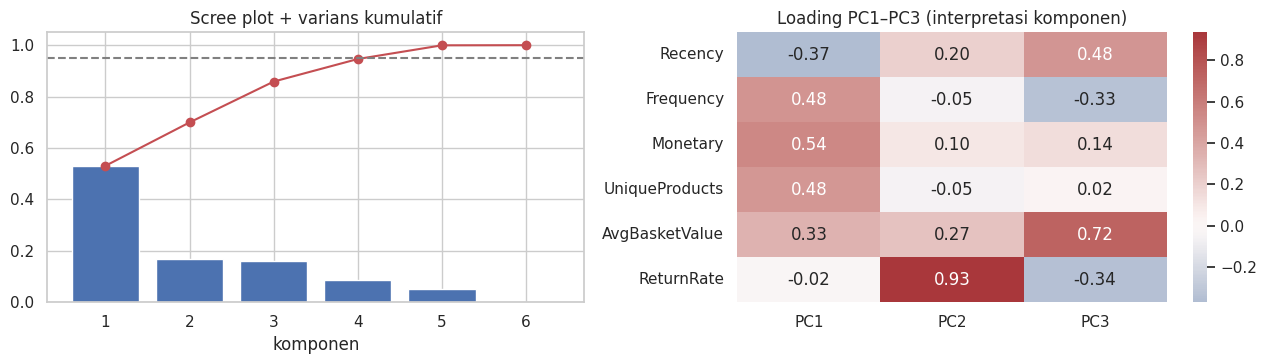

PCA(0.95) memakai 5 komponen | ARI vs K-Means RFM+ tanpa PCA = 1.000 | ARI vs K-Means RFM = 0.369
PC6 hanya menjelaskan 0.05% varians -> ada kombinasi fitur yang hampir kolinear (AvgBasketValue = Monetary/Frequency, sehingga log-nya ≈ selisih log Monetary dan Frequency).
PCA mengurangi redundansi tetapi menurunkan interpretabilitas (komponen = campuran fitur).


In [ ]:
# ===== I1. PCA pada RFM+ (6 fitur) =====
pca_full = PCA(random_state=RS).fit(Xp_tr)
evr = pca_full.explained_variance_ratio_
pca_tab = pd.DataFrame({"explained_variance": evr, "kumulatif": np.cumsum(evr)}, index=[f"PC{i+1}" for i in range(len(evr))])
display(pca_tab)
n90, n95 = int(np.searchsorted(np.cumsum(evr), 0.90) + 1), int(np.searchsorted(np.cumsum(evr), 0.95) + 1)
print(f"Komponen untuk 90% varians: {n90} | untuk 95%: {n95} dari {Xp_tr.shape[1]} fitur")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(range(1, len(evr) + 1), evr); ax[0].plot(range(1, len(evr) + 1), np.cumsum(evr), "ro-"); ax[0].axhline(0.95, ls="--", c="gray")
ax[0].set_title("Scree plot + varians kumulatif"); ax[0].set_xlabel("komponen")
load = pd.DataFrame(pca_full.components_[:3].T, index=RFM_PLUS, columns=["PC1", "PC2", "PC3"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1]); ax[1].set_title("Loading PC1–PC3 (interpretasi komponen)")
plt.tight_layout(); plt.show()

# Pipeline bebas leakage: prep -> PCA(95%) -> KMeans
pipe_pca = Pipeline([("prep", make_preprocessor(RFM_PLUS)), ("pca", PCA(n_components=0.95, random_state=RS)),
                     ("km", KMeans(K_STAR, n_init=10, random_state=RS))]).fit(cust_tr[RFM_PLUS])
lab_pca_tr = pipe_pca.named_steps["km"].labels_
print(f"PCA(0.95) memakai {pipe_pca.named_steps['pca'].n_components_} komponen | "
      f"ARI vs K-Means RFM+ tanpa PCA = {adjusted_rand_score(lab_plus_tr, lab_pca_tr):.3f} | "
      f"ARI vs K-Means RFM = {adjusted_rand_score(labels_tr[ref_name], lab_pca_tr):.3f}")
print(f"PC{len(evr)} hanya menjelaskan {evr[-1]*100:.2f}% varians -> ada kombinasi fitur yang hampir kolinear "
      "(AvgBasketValue = Monetary/Frequency, sehingga log-nya ≈ selisih log Monetary dan Frequency).")
print("PCA mengurangi redundansi tetapi menurunkan interpretabilitas (komponen = campuran fitur).")

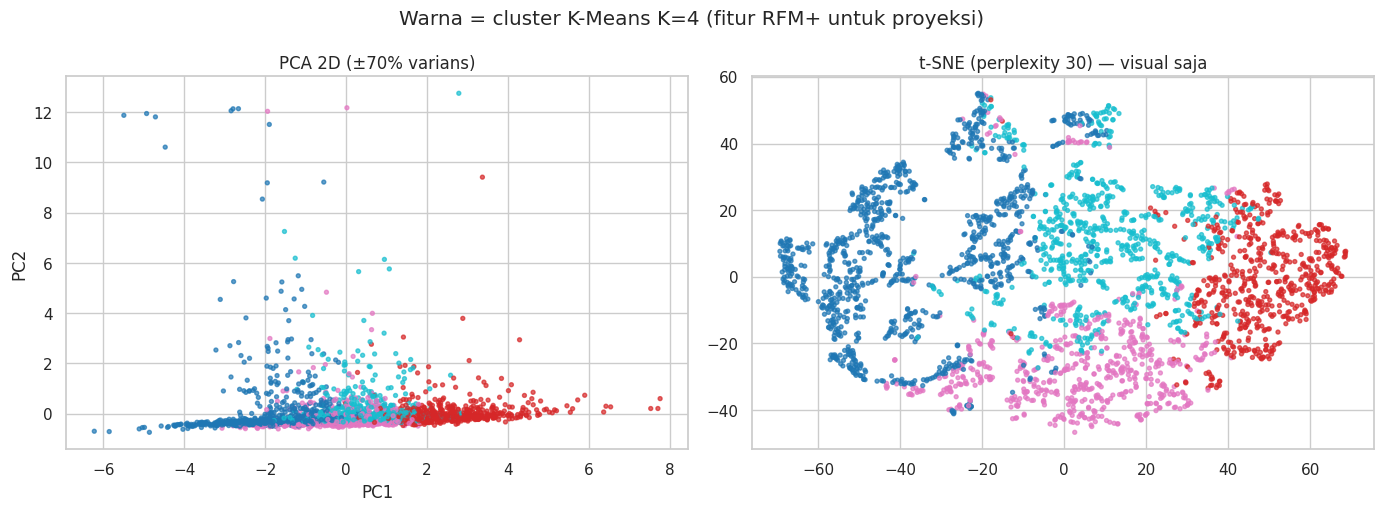

Awas: jarak/ukuran cluster di t-SNE tidak bermakna; hasil berubah menurut perplexity & seed; jangan menyimpulkan jumlah cluster dari plot saja.


In [ ]:
# ===== I2. Visualisasi 2D: PCA (linear) vs t-SNE (non-linear, hanya untuk melihat) =====
rng = np.random.default_rng(RS)
n_vis = min(CFG["TSNE_MAX_POINTS"], len(Xp_tr)); vis_idx = rng.choice(len(Xp_tr), n_vis, replace=False)
Xv, lv = Xp_tr[vis_idx], labels_tr[ref_name][vis_idx]
Z_pca = PCA(2, random_state=RS).fit_transform(Xv)
Z_tsne = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=RS).fit_transform(Xv)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, Z, t in [(ax[0], Z_pca, f"PCA 2D (±{pca_full.explained_variance_ratio_[:2].sum()*100:.0f}% varians)"), (ax[1], Z_tsne, "t-SNE (perplexity 30) — visual saja")]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=lv, cmap="tab10", s=8, alpha=.7); a.set_title(t)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); plt.suptitle(f"Warna = cluster K-Means K={K_STAR} (fitur RFM+ untuk proyeksi)"); plt.tight_layout(); plt.show()
print("Awas: jarak/ukuran cluster di t-SNE tidak bermakna; hasil berubah menurut perplexity & seed; jangan menyimpulkan jumlah cluster dari plot saja.")

### I3–I6. Pelengkap target P6: rekonstruksi, memilih jumlah komponen, dan sensitivitas visualisasi
W06 meminta: (a) PCA dipahami sebagai **kompresi dengan kehilangan** (rekonstruksi), (b) jumlah komponen dipilih dengan **tiga cara** (ambang varians, scree, validasi tugas hilir), dan (c) t-SNE/UMAP dipakai **bertanggung jawab** (hasil berubah menurut perplexity & seed; hanya untuk melihat data).


I3. Galat rekonstruksi PCA vs jumlah komponen (RFM+ terstandarisasi)


,varians_kumulatif,MSE_train,MSE_holdout,1 - varians_kumulatif
komponen_k,,,,
1,0.531,0.469,0.579,0.469
2,0.700,0.300,0.297,0.300
3,0.859,0.141,0.138,0.141
4,0.946,0.054,0.051,0.054
5,0.999,0.001,0.001,0.001
6,1.000,0.000,0.000,0.000


Pemeriksaan teori: tiap fitur sudah berskala varians ~1, sehingga MSE rekonstruksi ~ (1 - varians kumulatif). Selisih maks = 0.0000.


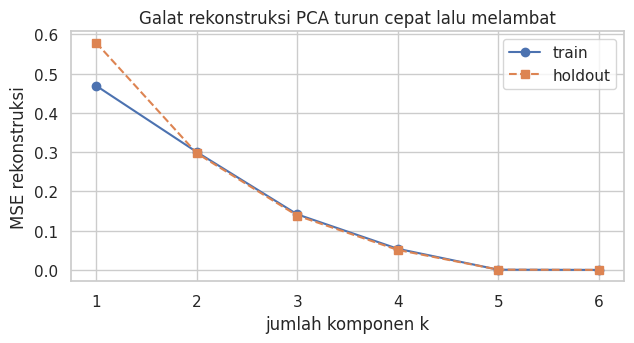

Dengan k=2 (dipakai untuk plot 2D) varians yang tertangkap 70.0% -> 30.0% informasi dibuang; plot 2D hanya ilustrasi, bukan dasar keputusan.


In [ ]:
# ===== I3. Rekonstruksi PCA: berapa informasi yang hilang? (W06: "PCA = kompresi dengan kehilangan") =====
section("I3. Galat rekonstruksi PCA vs jumlah komponen (RFM+ terstandarisasi)")
cum = np.cumsum(pca_full.explained_variance_ratio_)
rows = []
for k in range(1, Xp_tr.shape[1] + 1):
    p = PCA(n_components=k, random_state=RS).fit(Xp_tr)                                   # fit hanya train
    mse_tr = np.mean((Xp_tr - p.inverse_transform(p.transform(Xp_tr))) ** 2)
    mse_ho = np.mean((Xp_ho - p.inverse_transform(p.transform(Xp_ho))) ** 2)              # holdout: hanya transform
    rows.append({"komponen_k": k, "varians_kumulatif": cum[k - 1], "MSE_train": mse_tr, "MSE_holdout": mse_ho,
                 "1 - varians_kumulatif": 1 - cum[k - 1]})
recon = pd.DataFrame(rows).set_index("komponen_k"); display(recon)
gap = float(np.abs(recon["MSE_train"] - recon["1 - varians_kumulatif"]).max())
print(f"Pemeriksaan teori: tiap fitur sudah berskala varians ~1, sehingga MSE rekonstruksi ~ (1 - varians kumulatif). Selisih maks = {gap:.4f}.")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(recon.index, recon["MSE_train"], "o-", label="train"); ax.plot(recon.index, recon["MSE_holdout"], "s--", label="holdout")
ax.set_xlabel("jumlah komponen k"); ax.set_ylabel("MSE rekonstruksi"); ax.set_title("Galat rekonstruksi PCA turun cepat lalu melambat"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Dengan k=2 (dipakai untuk plot 2D) varians yang tertangkap {cum[1]*100:.1f}% -> {100-cum[1]*100:.1f}% informasi dibuang; plot 2D hanya ilustrasi, bukan dasar keputusan.")


In [ ]:
# ===== I4. Jumlah komponen untuk clustering: ambang varians, scree, dan VALIDASI TUGAS HILIR =====
section("I4. Jumlah komponen PCA — PCA di-fit ulang pada tiap subsampel (tanpa leakage)")
d = Xp_tr.shape[1]; rows = []
for k in range(2, d):
    mk = lambda k=k: Pipeline([("pca", PCA(n_components=k, random_state=RS)), ("km", KMeans(K_STAR, n_init=10, random_state=RS))])
    pk = mk().fit(Xp_tr); lab_k = pk.named_steps["km"].labels_; Zk = pk.named_steps["pca"].transform(Xp_tr)
    st_m, st_s = subsample_stability(mk, Xp_tr, CFG["N_SUBSAMPLE"], CFG["SUBSAMPLE_FRAC"], RS)
    rows.append({"n_komponen": k, "varians_kumulatif": cum[k - 1], "ARI vs RFM+ tanpa PCA": adjusted_rand_score(lab_plus_tr, lab_k),
                 "stabilitas_ARI": st_m, "stabilitas_std": st_s, "silhouette (ruang PCA-k)": cluster_metrics(Zk, lab_k)["silhouette"]})
rows.append({"n_komponen": f"{d} (tanpa PCA)", "varians_kumulatif": 1.0, "ARI vs RFM+ tanpa PCA": 1.0,
             "stabilitas_ARI": stab_plus[0], "stabilitas_std": stab_plus[1], "silhouette (ruang PCA-k)": mp["silhouette"]})
pca_k_tab = pd.DataFrame(rows).set_index("n_komponen"); display(pca_k_tab)
print("PERINGATAN (W06): kolom silhouette dihitung di ruang berbeda -> TIDAK sebanding antar baris; gunakan ARI vs tanpa PCA dan stabilitas.")
_ok = pca_k_tab.iloc[:-1]; _ok = _ok[_ok["ARI vs RFM+ tanpa PCA"] >= 0.90]
k_down = int(_ok.index[0]) if len(_ok) else None
print("\nRingkasan tiga cara memilih jumlah komponen (RFM+):")
print(f" 1) Ambang varians : {n90} komponen (90%) atau {n95} komponen (95%)  [I1]")
print(f" 2) Scree plot     : lihat I1 — siku dipakai sebagai petunjuk, bukan aturan keras")
print(f" 3) Tugas hilir    : komponen minimum yang mempertahankan partisi K-Means (ARI >= 0.90 vs tanpa PCA) = {k_down if k_down else 'tidak ada (semua komponen diperlukan)'}")
print("Catatan: dengan hanya 6 fitur, PCA di sini bertujuan menguji redundansi, bukan mengatasi curse of dimensionality.")



I4. Jumlah komponen PCA — PCA di-fit ulang pada tiap subsampel (tanpa leakage)


,varians_kumulatif,ARI vs RFM+ tanpa PCA,stabilitas_ARI,stabilitas_std,silhouette (ruang PCA-k)
n_komponen,,,,,
2,0.700,0.775,0.743,0.181,0.443
3,0.859,0.940,0.961,0.025,0.330
4,0.946,0.959,0.968,0.022,0.275
5,0.999,1.000,0.919,0.137,0.253
6 (tanpa PCA),1.000,1.000,0.918,0.138,0.253


PERINGATAN (W06): kolom silhouette dihitung di ruang berbeda -> TIDAK sebanding antar baris; gunakan ARI vs tanpa PCA dan stabilitas.

Ringkasan tiga cara memilih jumlah komponen (RFM+):
 1) Ambang varians : 4 komponen (90%) atau 5 komponen (95%)  [I1]
 2) Scree plot     : lihat I1 — siku dipakai sebagai petunjuk, bukan aturan keras
 3) Tugas hilir    : komponen minimum yang mempertahankan partisi K-Means (ARI >= 0.90 vs tanpa PCA) = 3
Catatan: dengan hanya 6 fitur, PCA di sini bertujuan menguji redundansi, bukan mengatasi curse of dimensionality.



I5. t-SNE tidak unik: hasil berubah menurut perplexity dan seed


,trustworthiness@10
proyeksi,
PCA 2D,0.872
"t-SNE perplexity=5, seed=42",0.990
"t-SNE perplexity=30, seed=42",0.994
"t-SNE perplexity=50, seed=42",0.993
"t-SNE perplexity=30, seed=43",0.994


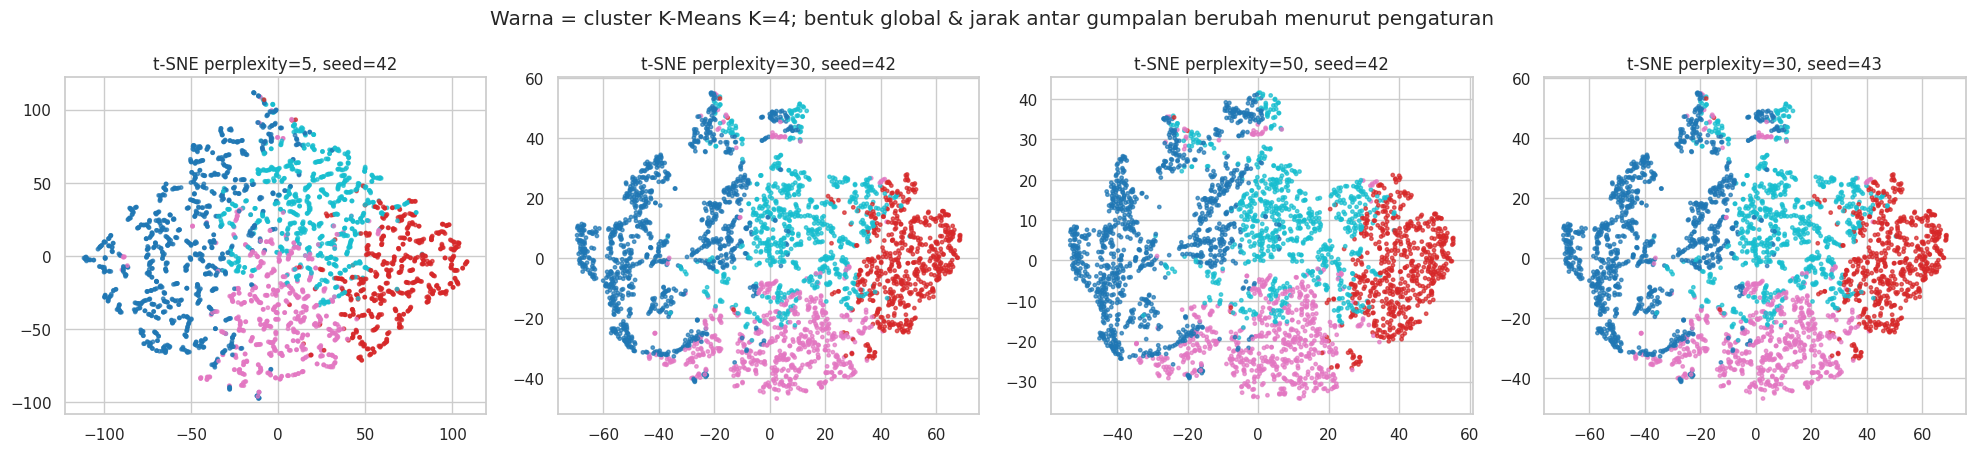

Trustworthiness@10 (1 = tetangga terdekat di plot juga tetangga di ruang asli): 0.872 – 0.994 di semua proyeksi.
Catatan: init='pca' membuat embedding relatif stabil terhadap seed; yang biasanya paling mengubah tampilan adalah perplexity. Tetap laporkan keduanya.
Trustworthiness hanya menilai kualitas LOKAL. Ukuran cluster & jarak antar cluster pada t-SNE tetap tidak bermakna; jangan menyimpulkan jumlah cluster dari plot.


In [ ]:
# ===== I5. Sensitivitas t-SNE: perplexity dan seed (W06: "coba beberapa nilai") + trustworthiness =====
from sklearn.manifold import trustworthiness
section("I5. t-SNE tidak unik: hasil berubah menurut perplexity dan seed")
configs = [(5, RS), (30, RS), (50, RS), (30, RS + 1)]
embeds = {}
for perp, sd in configs:
    embeds[(perp, sd)] = Z_tsne if (perp, sd) == (30, RS) else TSNE(2, perplexity=perp, init="pca", learning_rate="auto", random_state=sd).fit_transform(Xv)
rows = [{"proyeksi": "PCA 2D", "trustworthiness@10": trustworthiness(Xv, Z_pca, n_neighbors=10)}]
for (perp, sd), Z in embeds.items():
    rows.append({"proyeksi": f"t-SNE perplexity={perp}, seed={sd}", "trustworthiness@10": trustworthiness(Xv, Z, n_neighbors=10)})
trust = pd.DataFrame(rows).set_index("proyeksi"); display(trust)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for a, ((perp, sd), Z) in zip(axes, embeds.items()):
    a.scatter(Z[:, 0], Z[:, 1], c=lv, cmap="tab10", s=6, alpha=.7); a.set_title(f"t-SNE perplexity={perp}, seed={sd}")
plt.suptitle(f"Warna = cluster K-Means K={K_STAR}; bentuk global & jarak antar gumpalan berubah menurut pengaturan"); plt.tight_layout(); plt.show()
_tt = trust["trustworthiness@10"]
print(f"Trustworthiness@10 (1 = tetangga terdekat di plot juga tetangga di ruang asli): {_tt.min():.3f} – {_tt.max():.3f} di semua proyeksi.")
print("Catatan: init='pca' membuat embedding relatif stabil terhadap seed; yang biasanya paling mengubah tampilan adalah perplexity. Tetap laporkan keduanya.")
print("Trustworthiness hanya menilai kualitas LOKAL. Ukuran cluster & jarak antar cluster pada t-SNE tetap tidak bermakna; jangan menyimpulkan jumlah cluster dari plot.")



I6. UMAP (opsional) — jika pustaka tidak tersedia, sel ini dilewati tanpa memengaruhi hasil lain


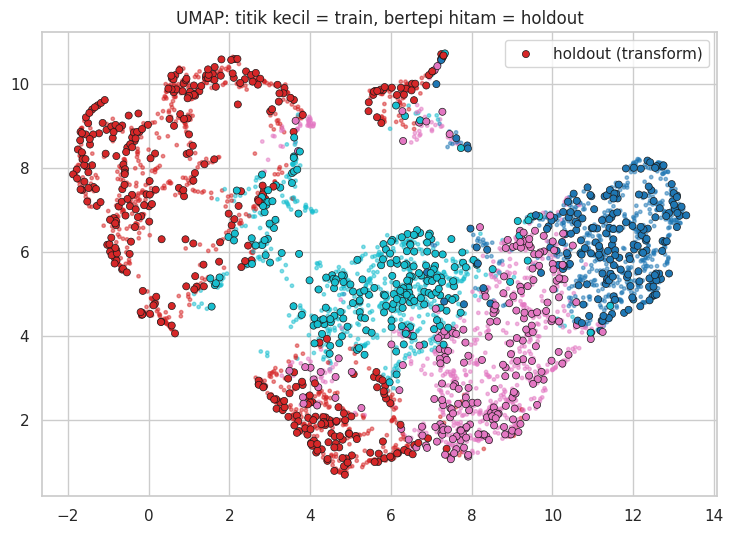

Trustworthiness@10 UMAP = 0.979 (bandingkan dengan tabel I5).
Awas: seperti t-SNE, ukuran/jarak cluster di UMAP tidak bermakna; gunakan untuk melihat, bukan sebagai fitur atau bukti jumlah cluster.


In [ ]:
# ===== I6. UMAP (opsional): non-linear, dapat men-transform data baru; tetap hanya untuk visualisasi =====
section("I6. UMAP (opsional) — jika pustaka tidak tersedia, sel ini dilewati tanpa memengaruhi hasil lain")
try:
    ensure("umap-learn", "umap")
    import umap
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RS)
    Z_umap = reducer.fit_transform(Xv)                                              # fit pada sampel TRAIN
    ho_pick = np.random.default_rng(RS).choice(len(Xp_ho), min(1000, len(Xp_ho)), replace=False)
    Z_umap_ho = reducer.transform(Xp_ho[ho_pick])                                   # data baru: hanya transform (t-SNE sklearn tidak bisa)
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    ax.scatter(Z_umap[:, 0], Z_umap[:, 1], c=lab_fin_tr[vis_idx], cmap="tab10", s=6, alpha=.5)
    ax.scatter(Z_umap_ho[:, 0], Z_umap_ho[:, 1], c=lab_fin_ho[ho_pick], cmap="tab10", s=26, edgecolor="k", linewidth=.5, label="holdout (transform)")
    ax.set_title("UMAP: titik kecil = train, bertepi hitam = holdout"); ax.legend(); plt.tight_layout(); plt.show()
    print(f"Trustworthiness@10 UMAP = {trustworthiness(Xv, Z_umap, n_neighbors=10):.3f} (bandingkan dengan tabel I5).")
    print("Awas: seperti t-SNE, ukuran/jarak cluster di UMAP tidak bermakna; gunakan untuk melihat, bukan sebagai fitur atau bukti jumlah cluster.")
except Exception as e:
    print("UMAP dilewati:", repr(e)[:200])


## J. Segmentasi Final-Kandidat, Ekspor, Checklist, dan Rencana
Model di sini adalah **kandidat terbaik berdasarkan bukti saat ini** (bukan keputusan final; sesuai aturan P4, model final baru dapat dipertanggungjawabkan setelah validasi, error analysis, dan tuning pada tahap UAS).

,n_pelanggan,persen_pelanggan,Recency,Frequency,Monetary,UniqueProducts,AvgBasketValue,ReturnRate,persen_total_Monetary
cluster,,,,,,,,,
0,1112,19.002,15.000,13.000,"5,088.075",167.500,362.349,0.010,71.486
1,1455,24.863,157.000,5.000,"1,594.690",69.000,320.843,0.003,18.514
2,1240,21.189,24.000,3.000,700.515,42.000,252.402,0.000,5.878
3,2045,34.945,401.000,1.000,292.010,18.000,204.500,0.000,4.123


,n_pelanggan,persen_pelanggan,persen_total_Monetary,Recency,Frequency,Monetary,saran_nama,tindakan_saran
cluster,,,,,,,,
0,1112,19.002,71.486,15.000,13.000,"5,088.075",Champions / Loyal High-Value,"Program loyalitas/VIP, akses awal produk, jang..."
1,1455,24.863,18.514,157.000,5.000,"1,594.690",At Risk (dulu aktif),Kampanye win-back dengan penawaran personal se...
2,1240,21.189,5.878,24.000,3.000,700.515,New / Recent Low-Frequency,"Onboarding, voucher pembelian kedua, rekomenda..."
3,2045,34.945,4.123,401.000,1.000,292.010,Dormant / Lost,"Reaktivasi biaya rendah (email), evaluasi apak..."


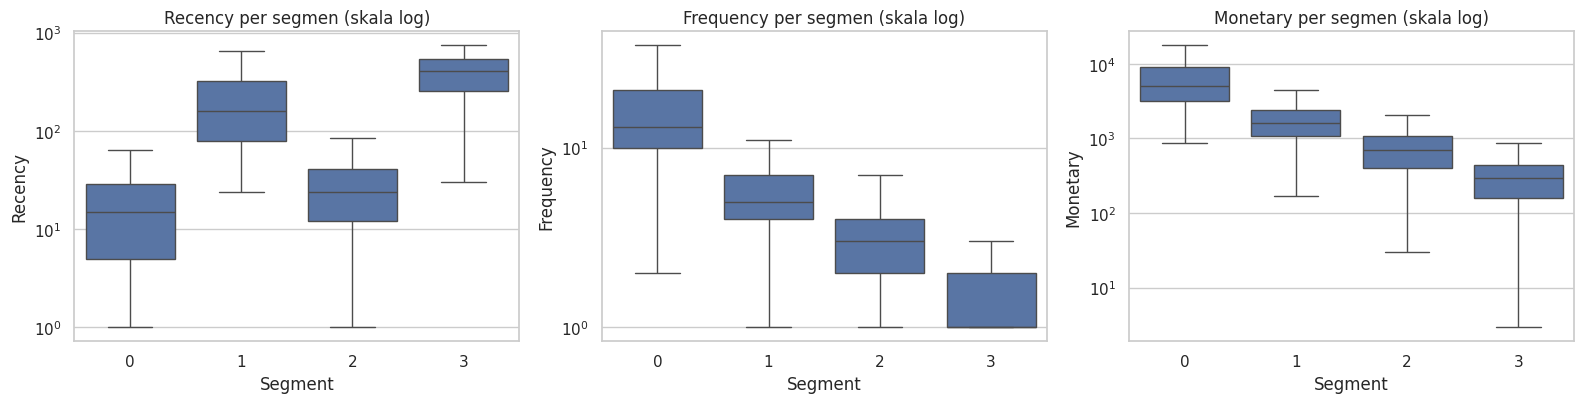

In [ ]:
# ===== J1. Pipeline kandidat + penugasan segmen untuk SEMUA pelanggan =====
final_pipe = make_km_pipeline(RFM, K_STAR, n_init=20).fit(cust_tr[RFM])     # fit hanya train
raw_lab = pd.Series(final_pipe.predict(cust[RFM]), index=cust.index)         # holdout hanya predict

# Urutkan ID segmen berdasar median Monetary menurun agar stabil & mudah dibaca (0 = nilai tertinggi)
order = cust.assign(c=raw_lab).groupby("c")["Monetary"].median().sort_values(ascending=False).index
remap = {old: new for new, old in enumerate(order)}
seg = raw_lab.map(remap).rename("Segment")
cust_seg = cust.join(seg); cust_seg["Split"] = np.where(cust_seg.index.isin(train_idx), "train", "holdout")

prof = profile_table(cust_seg, cust_seg["Segment"], RFM_PLUS)
display(prof)

# Saran nama segmen: aturan berbasis z-skor median log terhadap populasi (analis tetap memvalidasi)
log_all = np.log1p(cust[RFM]); mu, sd = log_all.mean(), log_all.std()
def suggest_name(row):
    z = {c: (np.log1p(row[c]) - mu[c]) / sd[c] for c in RFM}
    if z["Frequency"] > 0.5 and z["Monetary"] > 0.5 and z["Recency"] < 0:  return "Champions / Loyal High-Value"
    if z["Recency"] > 0.5 and z["Frequency"] < 0:                          return "Dormant / Lost"
    if z["Recency"] < 0 and z["Frequency"] < 0:                            return "New / Recent Low-Frequency"
    if z["Recency"] > 0 and z["Frequency"] >= 0:                           return "At Risk (dulu aktif)"
    return "Regular Active"
prof["saran_nama"] = prof.apply(suggest_name, axis=1)
ACTION = {
    "Champions / Loyal High-Value": "Program loyalitas/VIP, akses awal produk, jangan diskon berlebihan.",
    "Regular Active":               "Cross-sell & bundling, dorong naik frekuensi/keranjang.",
    "New / Recent Low-Frequency":   "Onboarding, voucher pembelian kedua, rekomendasi produk.",
    "At Risk (dulu aktif)":         "Kampanye win-back dengan penawaran personal sebelum hilang.",
    "Dormant / Lost":               "Reaktivasi biaya rendah (email), evaluasi apakah layak dikejar.",
}
prof["tindakan_saran"] = prof["saran_nama"].map(ACTION)
display(prof[["n_pelanggan", "persen_pelanggan", "persen_total_Monetary", "Recency", "Frequency", "Monetary", "saran_nama", "tindakan_saran"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for a, c in zip(axes, RFM):
    sns.boxplot(data=cust_seg, x="Segment", y=c, ax=a, showfliers=False); a.set_yscale("log"); a.set_title(f"{c} per segmen (skala log)")
plt.tight_layout(); plt.show()


J1b-1. Profil rata-rata per segmen dalam satuan asli (pelengkap median di J1)


,n_pelanggan,Recency,Frequency,Monetary,UniqueProducts,AvgBasketValue,ReturnRate
Segment,,,,,,,
0,1112,24.612,19.816,"10,972.715",211.922,557.046,0.022
1,1455,206.326,5.499,"2,171.851",87.865,488.449,0.026
2,1240,29.018,2.930,809.046,55.460,312.620,0.017
3,2045,395.112,1.430,344.090,23.816,260.029,0.027



J1b-2. Indeks terhadap rata-rata populasi (100 = sama dengan populasi)


,Recency,Frequency,Monetary,UniqueProducts,AvgBasketValue,ReturnRate
Segment,,,,,,
0,12.294,316.886,376.202,257.845,144.911,95.578
1,103.061,87.938,74.462,106.905,127.066,109.718
2,14.495,46.853,27.738,67.478,81.326,70.202
3,197.361,22.873,11.797,28.977,67.645,113.558


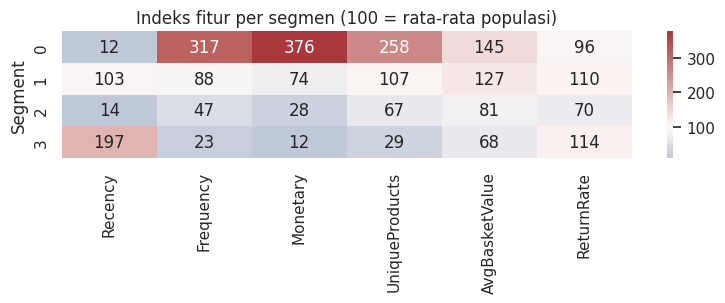


J1b-3. Fitur yang paling membedakan segmen (eta-squared; log1p kecuali ReturnRate)


,eta_squared,dipakai_untuk_clustering
Frequency,0.749,True
Recency,0.720,True
Monetary,0.691,True
UniqueProducts,0.447,False
AvgBasketValue,0.132,False
ReturnRate,0.002,False


Fitur paling membedakan: Frequency (eta2=0.75).
Fitur di luar RFM (tidak dipakai saat clustering) yang paling membedakan: UniqueProducts (eta2=0.45, efek besar; ambang Cohen 0.06/0.14) -> bukti tambahan bahwa segmen bermakna di luar fitur pembentuknya.


In [ ]:
# ===== J1b. Profil RATA-RATA (satuan asli) + fitur yang paling membedakan segmen (W06: profilkan cluster) =====
section("J1b-1. Profil rata-rata per segmen dalam satuan asli (pelengkap median di J1)")
mean_prof = cust_seg.groupby("Segment")[RFM_PLUS].mean()
mean_prof.insert(0, "n_pelanggan", cust_seg.groupby("Segment").size())
display(mean_prof)

section("J1b-2. Indeks terhadap rata-rata populasi (100 = sama dengan populasi)")
idx_prof = cust_seg.groupby("Segment")[RFM_PLUS].mean() / cust_seg[RFM_PLUS].mean() * 100
display(idx_prof)
plt.figure(figsize=(8, 3.2)); sns.heatmap(idx_prof, annot=True, fmt=".0f", cmap="vlag", center=100); plt.title("Indeks fitur per segmen (100 = rata-rata populasi)"); plt.tight_layout(); plt.show()

def eta_squared(values, groups):
    # Porsi variasi fitur yang dijelaskan oleh keanggotaan segmen (0..1); makin besar = makin membedakan.
    v = pd.Series(np.asarray(values)); g = pd.Series(np.asarray(groups)); grand = v.mean(); ss_tot = ((v - grand) ** 2).sum()
    ss_bet = sum(len(x) * (x.mean() - grand) ** 2 for _, x in v.groupby(g))
    return ss_bet / ss_tot if ss_tot > 0 else np.nan
eta = {c: eta_squared(np.log1p(cust_seg[c]) if c in LOG_COLS(RFM_PLUS) else cust_seg[c], cust_seg["Segment"]) for c in RFM_PLUS}
eta = pd.DataFrame({"eta_squared": pd.Series(eta), "dipakai_untuk_clustering": [c in RFM for c in RFM_PLUS]}).sort_values("eta_squared", ascending=False)
section("J1b-3. Fitur yang paling membedakan segmen (eta-squared; log1p kecuali ReturnRate)"); display(eta)
_top = eta.index[0]; _ext = eta[~eta["dipakai_untuk_clustering"]]
print(f"Fitur paling membedakan: {_top} (eta2={eta.loc[_top,'eta_squared']:.2f}).")
if len(_ext):
    _e = _ext["eta_squared"].idxmax(); _v = _ext.loc[_e, "eta_squared"]
    _lvl = "besar" if _v >= 0.14 else ("sedang" if _v >= 0.06 else "kecil")
    _msg = {"besar": "bukti tambahan bahwa segmen bermakna di luar fitur pembentuknya",
            "sedang": "dukungan sedang bahwa segmen bermakna di luar fitur pembentuknya",
            "kecil": "segmen praktis tidak membedakan fitur ini -> jangan mengklaim makna bisnis pada fitur tersebut"}[_lvl]
    print(f"Fitur di luar RFM (tidak dipakai saat clustering) yang paling membedakan: {_e} (eta2={_v:.2f}, efek {_lvl}; ambang Cohen 0.06/0.14) -> {_msg}.")
_o = Path(CFG["OUTPUT_DIR"]); mean_prof.to_csv(_o / "segment_profile_mean.csv"); eta.to_csv(_o / "segment_feature_eta2.csv")


In [ ]:
# ===== J2. Ekspor artefak & contoh inferensi pelanggan baru =====
out = Path(CFG["OUTPUT_DIR"])
cust_seg.reset_index().to_csv(out / "customer_segments.csv", index=False)
prof.to_csv(out / "segment_profile.csv")
compare.to_csv(out / "model_comparison.csv"); ksweep.to_csv(out / "kmeans_k_sweep.csv")
joblib.dump({"pipeline": final_pipe, "segment_remap": remap, "features": RFM, "snapshot": SNAPSHOT}, out / "segmentation_pipeline.joblib")
print("Tersimpan di:", out.resolve(), "->", sorted(p.name for p in out.iterdir()))

# Contoh pelanggan baru: 20 hari sejak beli, 12 invoice, total 4.500
new = pd.DataFrame([{"Recency": 20, "Frequency": 12, "Monetary": 4500.0}])
print("Segmen pelanggan contoh:", int(remap[int(final_pipe.predict(new[RFM])[0])]))

Tersimpan di: /content/outputs -> ['customer_segments.csv', 'kmeans_k_sweep.csv', 'model_comparison.csv', 'segment_feature_eta2.csv', 'segment_profile.csv', 'segment_profile_mean.csv', 'segmentation_pipeline.joblib']
Segmen pelanggan contoh: 0


In [ ]:
# ===== J3. Checklist dan output wajib P5 (rencana pasca-UTS ada di L3) =====
print("OUTPUT WAJIB PERTEMUAN 5")
for item in [
    "Strategi validasi & alasan            -> H1 (+ diagram)",
    "Hasil validasi / Cross-Validation     -> H2 (per fold, rata-rata, std), H3 (multi-seed), H4 (holdout)",
    "Tabel perbandingan baseline-kandidat  -> G3 (+ G4 varian fitur)",
    "Ensemble                              -> tidak relevan (unsupervised); diganti perbandingan metode & ARI konsensus",
    "Imbalance                             -> bukan classification; keseimbangan ukuran cluster diperiksa (H5, J1)",
    "Interpretasi & keterbatasan           -> F, G5, H5",
    "Rencana pasca-UTS                     -> L3 (dipicu temuan, menuju UAS)",
]: print(" [x]", item)

print("\nCHECKLIST UNSUPERVISED (W06)")
for item in ["Standarisasi (log1p + StandardScaler dalam Pipeline)", "Pilih K bijak (Elbow+Silhouette+DB+CH+bisnis)",
             "Sesuaikan bentuk (Ward/GMM/DBSCAN dibandingkan)", "Profilkan cluster (satuan asli, diberi nama)",
             "Hindari leakage (fit di train; CV memfit ulang per fold)", "Laporkan jujur (seed, ukuran cluster, batas interpretasi)"]:
    print(" [x]", item)

print("\nRencana pasca-UTS disusun di bagian L3: setiap tahap dipicu temuan nyata (bukan daftar umum).")


OUTPUT WAJIB PERTEMUAN 5
 [x] Strategi validasi & alasan            -> H1 (+ diagram)
 [x] Hasil validasi / Cross-Validation     -> H2 (per fold, rata-rata, std), H3 (multi-seed), H4 (holdout)
 [x] Tabel perbandingan baseline-kandidat  -> G3 (+ G4 varian fitur)
 [x] Ensemble                              -> tidak relevan (unsupervised); diganti perbandingan metode & ARI konsensus
 [x] Imbalance                             -> bukan classification; keseimbangan ukuran cluster diperiksa (H5, J1)
 [x] Interpretasi & keterbatasan           -> F, G5, H5
 [x] Rencana pasca-UTS                     -> L3 (dipicu temuan, menuju UAS)

CHECKLIST UNSUPERVISED (W06)
 [x] Standarisasi (log1p + StandardScaler dalam Pipeline)
 [x] Pilih K bijak (Elbow+Silhouette+DB+CH+bisnis)
 [x] Sesuaikan bentuk (Ward/GMM/DBSCAN dibandingkan)
 [x] Profilkan cluster (satuan asli, diberi nama)
 [x] Hindari leakage (fit di train; CV memfit ulang per fold)
 [x] Laporkan jujur (seed, ukuran cluster, batas interpretasi)

Re

## K. Reproducibility & Dokumentasi Eksperimen (Pertemuan 7)
Prinsip P7: *jika eksperimen tidak bisa dijalankan ulang dengan hasil yang sama, hasil itu belum bisa diklaim sebagai temuan.* Bagian ini menutup **tiga pilar** (random seed, environment, data versioning), lalu menambahkan **uji konsistensi**, **log eksperimen terstruktur**, **model card**, dan **checklist** sebelum penyerahan. Semua angka dalam dokumen dihasilkan otomatis dari run ini.

> Tahap error analysis mendalam, tuning, dan pemilihan model final termasuk Milestone UAS dan **sengaja tidak dikerjakan** di sini.

In [ ]:
# ===== K1. Tiga pilar reproducibility: seed, environment, data versioning =====
import platform, hashlib, json, datetime
import importlib.metadata as _im
out_dir = Path(CFG["OUTPUT_DIR"]); out_dir.mkdir(parents=True, exist_ok=True)

section("K1a. Random seed")
print(f"RANDOM_STATE = {RS} (CFG) dan np.random.seed({RS}) di setup. Seed eksplisit dipakai pada: train_test_split, KFold, KMeans, GMM, PCA, t-SNE, UMAP, dan subsampel stabilitas.")

section("K1b. Environment (versi library yang benar-benar dipakai pada run ini)")
env = {}
for _p in ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "openpyxl", "umap-learn", "kagglehub"]:
    try: env[_p] = _im.version(_p)
    except _im.PackageNotFoundError: pass
(out_dir / "requirements.txt").write_text("\n".join(f"{k}=={v}" for k, v in env.items()) + "\n")
print("Python", platform.python_version(), "|", platform.platform())
display(pd.Series(env, name="versi").to_frame())
print("Tersimpan: outputs/requirements.txt  (pip install -r requirements.txt untuk membangun ulang environment).")

section("K1c. Versioning data (sidik jari dataset)")
def _find_data_file():
    p = _find_local()
    if p: return p
    hits = [h for h in glob.glob(os.path.expanduser("~/.cache/kagglehub/datasets/**/*"), recursive=True)
            if h.lower().endswith((".csv", ".xlsx", ".xls"))]
    return sorted(hits, key=os.path.getsize, reverse=True)[0] if hits else None

def _sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

data_path = _find_data_file()
content_hash = hashlib.sha256(pd.util.hash_pandas_object(raw, index=False).values.tobytes()).hexdigest()
manifest = {
    "tanggal_run": datetime.datetime.now().isoformat(timespec="seconds"),
    "sumber_dataset": CFG["KAGGLE_SLUG"],
    "file": Path(data_path).name if data_path else None,
    "file_sha256": _sha256_file(data_path) if data_path else None,
    "ukuran_file_MB": round(os.path.getsize(data_path) / 1e6, 1) if data_path else None,
    "baris_mentah": int(len(raw)), "kolom": list(raw.columns),
    "rentang_waktu": [str(raw["InvoiceDate"].min()), str(raw["InvoiceDate"].max())],
    "sha256_isi_dataframe": content_hash,
    "baris_penjualan_sah": int(len(sales)), "pelanggan_dianalisis": int(len(cust)), "snapshot_recency": str(SNAPSHOT.date()),
    "split": {"train": int(len(cust_tr)), "holdout": int(len(cust_ho)), "test_size": CFG["TEST_SIZE"], "random_state": RS},
    "hasil_seleksi": {"K_STAR": int(K_STAR), "EPS_STAR": float(EPS_STAR), "MIN_SAMPLES": int(MIN_SAMPLES)},
    "CFG": CFG,
}
(out_dir / "data_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
display(pd.Series({k: v for k, v in manifest.items() if k not in ("CFG", "kolom", "split", "hasil_seleksi")}, name="nilai").to_frame())
if not data_path:
    print("File sumber tidak ditemukan di folder umum; sidik jari isi dataset (sha256_isi_dataframe) tetap dicatat.")
print("Tersimpan: outputs/data_manifest.json (versi data + konfigurasi run). Jika sha256 berbeda dari run sebelumnya, datanya berubah.")



K1a. Random seed
RANDOM_STATE = 42 (CFG) dan np.random.seed(42) di setup. Seed eksplisit dipakai pada: train_test_split, KFold, KMeans, GMM, PCA, t-SNE, UMAP, dan subsampel stabilitas.

K1b. Environment (versi library yang benar-benar dipakai pada run ini)
Python 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39


,versi
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
scipy,1.16.3
matplotlib,3.10.0
seaborn,0.13.2
joblib,1.6.0
openpyxl,3.1.5
umap-learn,0.5.12
kagglehub,1.0.3


Tersimpan: outputs/requirements.txt  (pip install -r requirements.txt untuk membangun ulang environment).

K1c. Versioning data (sidik jari dataset)


,nilai
tanggal_run,2026-11-04T12:32:13
sumber_dataset,adilhabib/online-retail-data-clustering
file,online_retail_II.xlsx
file_sha256,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4a...
ukuran_file_MB,45.600
baris_mentah,1067371
rentang_waktu,"[2009-12-01 07:45:00, 2011-12-09 12:50:00]"
sha256_isi_dataframe,4d3b2f7fce67a9054dcd1be5c51429f5e4f0196998ee9e...
baris_penjualan_sah,776579
pelanggan_dianalisis,5852


Tersimpan: outputs/data_manifest.json (versi data + konfigurasi run). Jika sha256 berbeda dari run sebelumnya, datanya berubah.


In [ ]:
# ===== K2. Uji konsistensi: pipeline sama + seed sama harus memberi hasil identik =====
section("K2. Reproducibility run-to-run (seed sama)")
rerun = make_km_pipeline(RFM, K_STAR, n_init=20).fit(cust_tr[RFM])
lab_a, lab_b = final_pipe.predict(cust[RFM]), rerun.predict(cust[RFM])
same_labels = bool(np.array_equal(lab_a, lab_b))
same_centers = bool(np.allclose(final_pipe.named_steps["km"].cluster_centers_, rerun.named_steps["km"].cluster_centers_))
tr2, ho2 = train_test_split(cust.index, test_size=CFG["TEST_SIZE"], random_state=RS)
same_split = bool(np.array_equal(tr2, train_idx) and np.array_equal(ho2, hold_idx))
m_rr = cluster_metrics(rerun.named_steps["prep"].transform(cust_tr[RFM]), rerun.named_steps["km"].labels_)
m_ref = cluster_metrics(X_tr, final_km.labels_)
same_metrics = all(np.isclose(m_rr[k], m_ref[k]) for k in m_rr)
repro = pd.DataFrame({"hasil": {"label segmen seluruh pelanggan identik": same_labels, "pusat cluster identik": same_centers,
                                "pembagian train/holdout identik": same_split, "metrik (silhouette/DB/CH) identik": same_metrics},
                      "nilai": {"label segmen seluruh pelanggan identik": f"ARI={adjusted_rand_score(lab_a, lab_b):.3f}",
                                "pusat cluster identik": f"maks selisih={np.abs(final_pipe.named_steps['km'].cluster_centers_ - rerun.named_steps['km'].cluster_centers_).max():.2e}",
                                "pembagian train/holdout identik": f"{len(tr2):,}/{len(ho2):,}",
                                "metrik (silhouette/DB/CH) identik": f"silhouette {m_rr['silhouette']:.4f} vs {m_ref['silhouette']:.4f}"}})
display(repro)
require(same_labels and same_split, "Hasil tidak identik pada seed yang sama: periksa sumber non-determinisme (seed belum di-set, urutan data berubah).")
print("LULUS: hasil identik pada seed yang sama.")
print("Kontras: dengan SEED BERBEDA hasil boleh sedikit bergeser (lihat H3: ARI antar seed). Karena itu seed dilaporkan, dan inisialisasi memakai k-means++ dengan n_init > 1.")



K2. Reproducibility run-to-run (seed sama)


,hasil,nilai
label segmen seluruh pelanggan identik,True,ARI=1.000
pusat cluster identik,True,maks selisih=0.00e+00
pembagian train/holdout identik,True,"4,681/1,171"
metrik (silhouette/DB/CH) identik,True,silhouette 0.3650 vs 0.3650


LULUS: hasil identik pada seed yang sama.
Kontras: dengan SEED BERBEDA hasil boleh sedikit bergeser (lihat H3: ARI antar seed). Karena itu seed dilaporkan, dan inisialisasi memakai k-means++ dengan n_init > 1.


In [ ]:
# ===== K3. Log eksperimen terstruktur (run, model, fitur, seed, metrik, catatan) =====
section("K3. Log eksperimen")
today = datetime.date.today().isoformat(); data_tag = content_hash[:8]
cv_k0 = cv_cluster_stability(RFM, K0, cust_tr, CFG["N_FOLDS"])
def _cv_txt(df): return f"{df.loc['Rata-rata','ARI vs model train penuh']:.3f} ± {df.loc['Standar Deviasi','ARI vs model train penuh']:.3f}"
def _stab_txt(r): return f"{r['stabilitas_ARI_mean']:.3f} ± {r['stabilitas_ARI_std']:.3f}"
nm = list(compare.index)                      # urutan = factories di G3: baseline, K*, Ward, GMM, DBSCAN
def _from_compare(rid, name, fitur, param, cat, cv="-"):
    r = compare.loc[name]
    return dict(run=rid, tanggal=today, data=data_tag, model=name, fitur=fitur, param=param, seed=RS, silhouette=r["silhouette"],
                davies_bouldin=r["davies_bouldin"], stabilitas_subsampel_ARI=_stab_txt(r), CV_ARI=cv, catatan=cat)
runs = [
    _from_compare("R01", nm[0], "RFM (3)", f"K={K0}, k-means++, n_init=10", "Baseline: K awal, belum dioptimalkan", _cv_txt(cv_k0)),
    _from_compare("R02", nm[1], "RFM (3)", f"K={K_STAR}, k-means++, n_init=10", "Kandidat konsensus peringkat Silhouette/DB/CH (bukan final)", _cv_txt(stab_final)),
    _from_compare("R03", nm[2], "RFM (3)", f"ward, K={K_STAR}", "Tidak ada predict untuk data baru; O(n^2) memori"),
    _from_compare("R04", nm[3], "RFM (3)", f"full cov, K={K_STAR}, n_init=3", "Soft assignment; asumsi Gaussian"),
    _from_compare("R05", nm[4], "RFM (3)", f"eps={EPS_STAR:.2f}, min_samples={MIN_SAMPLES}",
                  f"{int(compare.loc[nm[4],'n_cluster'])} cluster, noise {compare.loc[nm[4],'noise_%']:.1f}%" +
                  ("; jumlah cluster < K* -> stabilitas tidak setara dengan baris lain" if compare.loc[nm[4],'n_cluster'] < K_STAR else "")),
]
runs.append(dict(run="R06", tanggal=today, data=data_tag, model=f"K-Means K={K_STAR}", fitur="RFM+ (6)", param=f"K={K_STAR}, n_init=10", seed=RS,
                 silhouette=mp["silhouette"], davies_bouldin=mp["davies_bouldin"], stabilitas_subsampel_ARI=f"{stab_plus[0]:.3f} ± {stab_plus[1]:.3f}",
                 CV_ARI="-", catatan="Ruang fitur berbeda -> silhouette tidak sebanding dengan R01-R05"))
Zp = pipe_pca[:-1].transform(cust_tr[RFM_PLUS]); mpca = cluster_metrics(Zp, lab_pca_tr)
stab_pca = subsample_stability(lambda: Pipeline([("pca", PCA(0.95, random_state=RS)), ("km", KMeans(K_STAR, n_init=10, random_state=RS))]),
                               Xp_tr, CFG["N_SUBSAMPLE"], CFG["SUBSAMPLE_FRAC"], RS)
runs.append(dict(run="R07", tanggal=today, data=data_tag, model=f"PCA(95%) + K-Means K={K_STAR}", fitur="RFM+ (6)",
                 param=f"{pipe_pca.named_steps['pca'].n_components_} komponen, K={K_STAR}", seed=RS, silhouette=mpca["silhouette"],
                 davies_bouldin=mpca["davies_bouldin"], stabilitas_subsampel_ARI=f"{stab_pca[0]:.3f} ± {stab_pca[1]:.3f}", CV_ARI="-",
                 catatan=f"ARI vs R06 = {adjusted_rand_score(lab_plus_tr, lab_pca_tr):.3f}; silhouette di ruang PCA (tidak sebanding)"))
exp_log = pd.DataFrame(runs).set_index("run"); display(exp_log)
exp_log.to_csv(out_dir / "experiment_log.csv")
print(f"Tersimpan: outputs/experiment_log.csv ({len(exp_log)} run). Setiap eksperimen baru: tambahkan baris (jangan hanya mengandalkan ingatan).")
print("Catatan: kolom silhouette hanya sebanding antar baris yang memakai ruang fitur sama (R01-R05); baris lain dibandingkan lewat stabilitas & ARI.")



K3. Log eksperimen


,tanggal,data,model,fitur,param,seed,silhouette,davies_bouldin,stabilitas_subsampel_ARI,CV_ARI,catatan
run,,,,,,,,,,,
R01,2026-11-04,4d3b2f7f,K-Means K=3 (baseline),RFM (3),"K=3, k-means++, n_init=10",42,0.346,1.039,0.935 ± 0.037,0.946 ± 0.026,"Baseline: K awal, belum dioptimalkan"
R02,2026-11-04,4d3b2f7f,K-Means K=4,RFM (3),"K=4, k-means++, n_init=10",42,0.365,0.939,0.949 ± 0.056,0.963 ± 0.041,Kandidat konsensus peringkat Silhouette/DB/CH ...
R03,2026-11-04,4d3b2f7f,Ward K=4,RFM (3),"ward, K=4",42,0.306,0.938,0.472 ± 0.084,-,Tidak ada predict untuk data baru; O(n^2) memori
R04,2026-11-04,4d3b2f7f,GMM K=4,RFM (3),"full cov, K=4, n_init=3",42,0.214,1.156,0.877 ± 0.154,-,Soft assignment; asumsi Gaussian
R05,2026-11-04,4d3b2f7f,DBSCAN eps=0.37,RFM (3),"eps=0.37, min_samples=6",42,0.277,1.013,0.980 ± 0.005,-,"2 cluster, noise 2.8%; jumlah cluster < K* -> ..."
R06,2026-11-04,4d3b2f7f,K-Means K=4,RFM+ (6),"K=4, n_init=10",42,0.253,1.148,0.918 ± 0.138,-,Ruang fitur berbeda -> silhouette tidak seband...
R07,2026-11-04,4d3b2f7f,PCA(95%) + K-Means K=4,RFM+ (6),"5 komponen, K=4",42,0.253,1.147,0.919 ± 0.137,-,ARI vs R06 = 1.000; silhouette di ruang PCA (t...


Tersimpan: outputs/experiment_log.csv (7 run). Setiap eksperimen baru: tambahkan baris (jangan hanya mengandalkan ingatan).
Catatan: kolom silhouette hanya sebanding antar baris yang memakai ruang fitur sama (R01-R05); baris lain dibandingkan lewat stabilitas & ARI.


In [ ]:
# ===== K4. Model card ringkas — dihasilkan otomatis dari hasil run ini =====
from sklearn.metrics import silhouette_samples
_km_lab = pd.Series(final_pipe.named_steps["km"].labels_).map(remap).values
sil_seg = pd.Series(silhouette_samples(X_tr, final_pipe.named_steps["km"].labels_)).groupby(_km_lab).mean()
seg_lines = "\n".join(
    f"  - **Segmen {s} — {r['saran_nama']}**: {int(r['n_pelanggan']):,} pelanggan ({r['persen_pelanggan']:.1f}%), {r['persen_total_Monetary']:.1f}% total Monetary; "
    f"median Recency={r['Recency']:.0f} hari, Frequency={r['Frequency']:.0f}, Monetary={r['Monetary']:,.0f}; silhouette rata-rata segmen (train)={sil_seg.get(s, float('nan')):.3f}"
    for s, r in prof.sort_index().iterrows())
cr = stab_final.loc["Rata-rata", "ARI vs model train penuh"]; cs = stab_final.loc["Standar Deviasi", "ARI vs model train penuh"]
_s = conf.loc["silhouette", "train"]
_struct_txt = (f"Struktur bersifat kontinum (silhouette tergolong *{sil_band(_s).split(' (')[0]}*): batas antar segmen tidak tegas, sehingga pelanggan di perbatasan dapat berpindah segmen."
               if _s < 0.51 else f"Pemisahan segmen relatif tegas (silhouette tergolong *{sil_band(_s).split(' (')[0]}*), namun tetap perlu divalidasi secara bisnis.")
_red_txt = (f"; fitur RFM sebagian redundan ({strongest[0]}–{strongest[1]}, Spearman {pairs[strongest]:.2f})" if abs(pairs[strongest]) >= 0.7 else "")
card = f"""# Model Card — Segmentasi Pelanggan (K-Means, K={K_STAR})
*Dihasilkan otomatis pada {today} · tag data `{data_tag}` · seed {RS}. Status: **kandidat terbaik berdasarkan bukti saat ini, bukan model final.***

## 1. Tujuan & konteks
- **Masalah:** toko online perlengkapan hadiah (banyak pelanggan grosir; deskripsi UCI) memperlakukan semua pelanggan sama; model mengelompokkan pelanggan berdasarkan perilaku pembelian (Recency, Frequency, Monetary) tanpa label.
- **Pengguna:** tim pemasaran/CRM untuk membedakan promosi, retensi, dan layanan per segmen.
- **Batas penggunaan:** hanya untuk pelanggan teridentifikasi (punya CustomerID); bukan untuk keputusan individual berisiko tinggi; nama segmen adalah usulan analis, bukan fakta dari data.

## 2. Data
- **Sumber:** {CFG['KAGGLE_SLUG']} ({manifest['file'] or 'file lokal'}); {len(raw):,} baris mentah, periode {raw['InvoiceDate'].min().date()} s.d. {raw['InvoiceDate'].max().date()}.
- **Setelah pembersihan:** {len(sales):,} baris penjualan sah → {len(cust):,} pelanggan (train {len(cust_tr):,} / holdout {len(cust_ho):,}).
- **Potensi bias/keterbatasan data:** {miss_cust_pct:.1f}% baris tanpa CustomerID dibuang; {uk_share:.0f}% baris dari United Kingdom; pelanggan grosir (outlier nilai tinggi) dipertahankan; satu periode waktu.

## 3. Metodologi
- **Fitur:** RFM → `log1p` + `StandardScaler` di dalam Pipeline (fit hanya pada train).
- **Algoritma:** K-Means K={K_STAR} (`k-means++`, n_init=20, seed {RS}); K dipilih dari konsensus peringkat Silhouette/Davies-Bouldin/Calinski-Harabasz pada K∈[{CFG['K_BUSINESS'][0]},{CFG['K_BUSINESS'][1]}].
- **Validasi:** holdout 20% (dipakai sekali), 5-Fold CV, {CFG['N_SEEDS']} seed, {CFG['N_SUBSAMPLE']} subsampel.
- **Pembanding:** baseline K-Means K={K0}; Ward, GMM, DBSCAN, varian fitur RFM+, PCA+K-Means.

## 4. Hasil & evaluasi
- **Metrik internal:** silhouette train={conf.loc['silhouette','train']:.3f} / holdout={conf.loc['silhouette','holdout']:.3f}; Davies-Bouldin train={conf.loc['davies_bouldin','train']:.3f} / holdout={conf.loc['davies_bouldin','holdout']:.3f}. Interpretasi silhouette: **{sil_band(conf.loc['silhouette','train'])}**.
- **Ketidakpastian:** ARI antar-fold = {cr:.3f} ± {cs:.3f}; stabilitas subsampel = {compare.loc[ref_name,'stabilitas_ARI_mean']:.3f} ± {compare.loc[ref_name,'stabilitas_ARI_std']:.3f}.
- **Performa per subgrup (segmen):**
{seg_lines}
- **Error analysis:** belum dilakukan (termasuk Milestone UAS); titik berisiko yang akan ditelaah: pelanggan dengan silhouette < 0 dan segmen terkecil.

## 5. Keterbatasan & risiko
- {_struct_txt}
- Hasil dapat berubah bila K, fitur, atau seed diubah{_red_txt}.
- Tidak ada ground truth; kebermaknaan bisnis harus divalidasi pemangku kepentingan.
- Diperkirakan berkinerja buruk pada: pelanggan baru tanpa riwayat, perubahan musiman/tren, pasar di luar UK.
- **Pemantauan setelah penerapan:** fit ulang berkala, pantau pergeseran komposisi segmen (drift), dan bandingkan dengan data periode berikutnya.

## 6. Pelaporan jujur
Seed={RS}; ukuran segmen dilaporkan di atas; batas interpretasi: nama & tindakan segmen adalah usulan, bukan hasil dari data.
"""
(out_dir / "MODEL_CARD.md").write_text(card, encoding="utf-8")
try:
    from IPython.display import Markdown, display as _ipy_display
    _ipy_display(Markdown(card))
except Exception:
    print(card)
print("Tersimpan: outputs/MODEL_CARD.md")


# Model Card — Segmentasi Pelanggan (K-Means, K=4)
*Dihasilkan otomatis pada 2026-11-04 · tag data `4d3b2f7f` · seed 42. Status: **kandidat terbaik berdasarkan bukti saat ini, bukan model final.***

## 1. Tujuan & konteks
- **Masalah:** toko online perlengkapan hadiah (banyak pelanggan grosir; deskripsi UCI) memperlakukan semua pelanggan sama; model mengelompokkan pelanggan berdasarkan perilaku pembelian (Recency, Frequency, Monetary) tanpa label.
- **Pengguna:** tim pemasaran/CRM untuk membedakan promosi, retensi, dan layanan per segmen.
- **Batas penggunaan:** hanya untuk pelanggan teridentifikasi (punya CustomerID); bukan untuk keputusan individual berisiko tinggi; nama segmen adalah usulan analis, bukan fakta dari data.

## 2. Data
- **Sumber:** adilhabib/online-retail-data-clustering (online_retail_II.xlsx); 1,067,371 baris mentah, periode 2009-12-01 s.d. 2011-12-09.
- **Setelah pembersihan:** 776,579 baris penjualan sah → 5,852 pelanggan (train 4,681 / holdout 1,171).
- **Potensi bias/keterbatasan data:** 22.8% baris tanpa CustomerID dibuang; 92% baris dari United Kingdom; pelanggan grosir (outlier nilai tinggi) dipertahankan; satu periode waktu.

## 3. Metodologi
- **Fitur:** RFM → `log1p` + `StandardScaler` di dalam Pipeline (fit hanya pada train).
- **Algoritma:** K-Means K=4 (`k-means++`, n_init=20, seed 42); K dipilih dari konsensus peringkat Silhouette/Davies-Bouldin/Calinski-Harabasz pada K∈[3,8].
- **Validasi:** holdout 20% (dipakai sekali), 5-Fold CV, 10 seed, 10 subsampel.
- **Pembanding:** baseline K-Means K=3; Ward, GMM, DBSCAN, varian fitur RFM+, PCA+K-Means.

## 4. Hasil & evaluasi
- **Metrik internal:** silhouette train=0.365 / holdout=0.376; Davies-Bouldin train=0.939 / holdout=0.930. Interpretasi silhouette: **lemah (struktur bisa jadi artifisial/kontinum)**.
- **Ketidakpastian:** ARI antar-fold = 0.963 ± 0.041; stabilitas subsampel = 0.949 ± 0.056.
- **Performa per subgrup (segmen):**
  - **Segmen 0 — Champions / Loyal High-Value**: 1,112 pelanggan (19.0%), 71.5% total Monetary; median Recency=15 hari, Frequency=13, Monetary=5,088; silhouette rata-rata segmen (train)=0.340
  - **Segmen 1 — At Risk (dulu aktif)**: 1,455 pelanggan (24.9%), 18.5% total Monetary; median Recency=157 hari, Frequency=5, Monetary=1,595; silhouette rata-rata segmen (train)=0.304
  - **Segmen 2 — New / Recent Low-Frequency**: 1,240 pelanggan (21.2%), 5.9% total Monetary; median Recency=24 hari, Frequency=3, Monetary=701; silhouette rata-rata segmen (train)=0.291
  - **Segmen 3 — Dormant / Lost**: 2,045 pelanggan (34.9%), 4.1% total Monetary; median Recency=401 hari, Frequency=1, Monetary=292; silhouette rata-rata segmen (train)=0.468
- **Error analysis:** belum dilakukan (termasuk Milestone UAS); titik berisiko yang akan ditelaah: pelanggan dengan silhouette < 0 dan segmen terkecil.

## 5. Keterbatasan & risiko
- Struktur bersifat kontinum (silhouette tergolong *lemah*): batas antar segmen tidak tegas, sehingga pelanggan di perbatasan dapat berpindah segmen.
- Hasil dapat berubah bila K, fitur, atau seed diubah; fitur RFM sebagian redundan (Frequency–Monetary, Spearman 0.86).
- Tidak ada ground truth; kebermaknaan bisnis harus divalidasi pemangku kepentingan.
- Diperkirakan berkinerja buruk pada: pelanggan baru tanpa riwayat, perubahan musiman/tren, pasar di luar UK.
- **Pemantauan setelah penerapan:** fit ulang berkala, pantau pergeseran komposisi segmen (drift), dan bandingkan dengan data periode berikutnya.

## 6. Pelaporan jujur
Seed=42; ukuran segmen dilaporkan di atas; batas interpretasi: nama & tindakan segmen adalah usulan, bukan hasil dari data.


Tersimpan: outputs/MODEL_CARD.md


In [ ]:
# ===== K5. Checklist reproducibility sebelum menyerahkan proyek (P7) — diverifikasi otomatis bila memungkinkan =====
def _rs_explicit(est):
    ps = est.get_params(deep=True); ks = [k for k in ps if k.split("__")[-1] == "random_state"]
    return len(ks) > 0 and all(ps[k] is not None for k in ks)
estimators = {"baseline KMeans": base_km, "final KMeans": final_km, "pipeline final": final_pipe, "pipeline PCA+KMeans": pipe_pca, "PCA penuh": pca_full}
rs_report = {n: _rs_explicit(e) for n, e in estimators.items()}
checks = [
    ("random_state eksplisit pada semua estimator utama " + str(list(estimators)), all(rs_report.values())),
    ("requirements.txt disertakan dan sesuai environment yang dipakai", (out_dir / "requirements.txt").exists()),
    ("Versi data dicatat (data_manifest.json)", (out_dir / "data_manifest.json").exists()),
    ("Hasil identik antar run pada seed yang sama (K2)", same_labels and same_split),
    ("Model card / dokumentasi ringkas disertakan (MODEL_CARD.md)", (out_dir / "MODEL_CARD.md").exists()),
    (f"Log eksperimen disertakan ({len(exp_log)} run, minimal 5)", len(exp_log) >= 5),
]
section("K5. CHECKLIST REPRODUCIBILITY (P7)")
for text, ok in checks: print(" [x]" if ok else " [ ]", text)
print(" [ ] (uji manual) Kode berjalan dari awal sampai akhir tanpa error pada mesin bersih: Runtime -> Restart session and run all; centang setelah berhasil.")
if not all(rs_report.values()): print("Estimator tanpa random_state eksplisit:", [n for n, v in rs_report.items() if not v])
print("\nBerkas keluaran:", sorted(p.name for p in out_dir.iterdir()))



K5. CHECKLIST REPRODUCIBILITY (P7)
 [x] random_state eksplisit pada semua estimator utama ['baseline KMeans', 'final KMeans', 'pipeline final', 'pipeline PCA+KMeans', 'PCA penuh']
 [x] requirements.txt disertakan dan sesuai environment yang dipakai
 [x] Versi data dicatat (data_manifest.json)
 [x] Hasil identik antar run pada seed yang sama (K2)
 [x] Model card / dokumentasi ringkas disertakan (MODEL_CARD.md)
 [x] Log eksperimen disertakan (7 run, minimal 5)
 [ ] (uji manual) Kode berjalan dari awal sampai akhir tanpa error pada mesin bersih: Runtime -> Restart session and run all; centang setelah berhasil.

Berkas keluaran: ['MODEL_CARD.md', 'customer_segments.csv', 'data_manifest.json', 'experiment_log.csv', 'kmeans_k_sweep.csv', 'model_comparison.csv', 'requirements.txt', 'segment_feature_eta2.csv', 'segment_profile.csv', 'segment_profile_mean.csv', 'segmentation_pipeline.joblib']


### K6. Peta kesesuaian dengan target proyek (khusus Unsupervised Learning)
| Pertemuan | Target (versi unsupervised) | Lokasi di notebook |
|---|---|---|
| **P3** | Problem (rumusan, tujuan, target, fitur, jenis) · Dataset (sumber, jumlah, fitur, target, kualitas) · Preprocessing (langkah, alasan, data hasil) · Baseline K-Means konfigurasi awal · Evaluasi awal (jumlah, ukuran, karakteristik cluster, Silhouette) · Temuan awal | A · B1–B6 · C1–C3 (+C2, C2b) · D · E1–E3 · F |
| **P4** | Dataset/tujuan/fitur/preprocessing dipertahankan · baseline + kandidat metode + jumlah cluster + karakteristik + evaluasi · tabel perbandingan · kelebihan/kelemahan · 3–5 temuan · **model final belum diputuskan** | G1–G5 (+G3b) · J (berstatus kandidat) |
| **P5** | Strategi validasi + alasan · hasil CV · kestabilan clustering · perbandingan metode · ukuran & karakteristik cluster · metrik internal · interpretasi & keterbatasan · rencana | H1–H5 · J3 · L3 |
| **P6** | Checklist W06: standarisasi · pilih K bijak · sesuaikan bentuk · profilkan cluster · hindari leakage · laporkan jujur. PCA (varians, rekonstruksi, jumlah komponen); t-SNE/UMAP bertanggung jawab | C3 · G1 · G2–G3b · J1–J1b · Pipeline (C3, H2, I1, I4) · K4 · I1–I6 |
| **P7** | Seed eksplisit · environment · versi data · log eksperimen · model card · checklist penyerahan · hasil konsisten antar run | K1–K5 |

**Sengaja tidak dikerjakan (di luar jenis proyek atau di luar Milestone UTS):** metrik classification (accuracy/precision/recall/F1/confusion matrix), regression, text mining, ensemble sebagai peningkat akurasi, penanganan imbalance kelas (padanannya: keseimbangan ukuran cluster, H5), serta tuning, error analysis mendalam, dan pemilihan model final (Milestone UAS).

## L. Tabel Hasil Eksperimen Awal, Analisis, dan Rencana Pasca-UTS
Bagian ini merangkum luaran wajib UTS: **(4) tabel hasil eksperimen awal** (baseline, kandidat, metode validasi, metrik, hasil), **analisis hasil awal**, **(5) rencana pengembangan pasca-UTS**, serta **pemeriksaan konsistensi** agar angka laporan dapat ditelusuri ke notebook. Semua angka diambil dari variabel hasil eksperimen di atas, bukan diketik ulang.

In [ ]:
# ===== L1. TABEL HASIL EKSPERIMEN AWAL (luaran wajib #4): baseline, kandidat, metode validasi, metrik, hasil =====
section("L1. Tabel hasil eksperimen awal")
nm = list(compare.index)                                     # urutan G3: baseline, K*, Ward, GMM, DBSCAN
_sub = f"subsampel {CFG['N_SUBSAMPLE']}x{int(CFG['SUBSAMPLE_FRAC']*100)}%"
_full = f"Holdout {int(CFG['TEST_SIZE']*100)}% + {CFG['N_FOLDS']}-Fold CV + {_sub} + {CFG['N_SEEDS']} seed"
peran = {"R01": "Baseline", "R02": "Kandidat (K hasil seleksi)", "R03": "Kandidat (metode lain)", "R04": "Kandidat (metode lain)",
         "R05": "Kandidat (metode lain)", "R06": "Varian fitur (feature engineering)", "R07": "Reduksi dimensi + K-Means"}
val = {"R01": _full, "R02": _full,
       "R03": f"Metrik internal (train) + {_sub}; tanpa holdout (tidak ada predict)",
       "R04": f"Metrik internal (train) + {_sub}; tidak dievaluasi di holdout",
       "R05": f"Metrik internal (train, non-noise) + {_sub}; tanpa holdout (tidak ada predict)",
       "R06": f"Metrik internal (ruang RFM+) + {_sub}", "R07": f"Metrik internal (ruang PCA) + {_sub}"}
ch = {f"R0{i+1}": compare.loc[nm[i], "calinski_harabasz"] for i in range(5)}; ch["R06"] = mp["calinski_harabasz"]; ch["R07"] = mpca["calinski_harabasz"]
_rank = compare["silhouette"].rank(ascending=False).astype(int)
tabel_uts = exp_log.copy()
tabel_uts.insert(0, "peran", pd.Series(peran))
tabel_uts["metode_validasi"] = pd.Series(val)
tabel_uts["calinski_harabasz"] = pd.Series(ch)
tabel_uts["silhouette_holdout"] = pd.Series({"R01": m_ho["silhouette"], "R02": conf.loc["silhouette", "holdout"]})
tabel_uts["peringkat_silhouette (ruang RFM)"] = pd.Series({f"R0{i+1}": int(_rank[nm[i]]) for i in range(5)})
_cols = ["peran", "model", "fitur", "param", "metode_validasi", "silhouette", "davies_bouldin", "calinski_harabasz", "silhouette_holdout",
         "stabilitas_subsampel_ARI", "CV_ARI", "peringkat_silhouette (ruang RFM)", "seed", "catatan"]
tabel_uts = tabel_uts[_cols]
with pd.option_context("display.max_colwidth", 80, "display.width", 300):
    display(tabel_uts)
tabel_uts.to_csv(out_dir / "tabel_hasil_uts.csv")
print("Tersimpan: outputs/tabel_hasil_uts.csv")
print("Cara membaca: silhouette/DB/CH hanya sebanding antar baris dengan ruang fitur yang sama (R01-R05). R06 dan R07 dibandingkan lewat stabilitas dan ARI.")
print("Holdout hanya dipakai untuk konfirmasi baseline (R01) dan K-Means terpilih (R02); kandidat lain tidak menyentuh holdout.")



L1. Tabel hasil eksperimen awal


,peran,model,fitur,param,metode_validasi,silhouette,davies_bouldin,calinski_harabasz,silhouette_holdout,stabilitas_subsampel_ARI,CV_ARI,peringkat_silhouette (ruang RFM),seed,catatan
run,,,,,,,,,,,,,,
R01,Baseline,K-Means K=3 (baseline),RFM (3),"K=3, k-means++, n_init=10",Holdout 20% + 5-Fold CV + subsampel 10x80% + 10 seed,0.346,1.039,"4,118.384",0.356,0.935 ± 0.037,0.946 ± 0.026,2.000,42,"Baseline: K awal, belum dioptimalkan"
R02,Kandidat (K hasil seleksi),K-Means K=4,RFM (3),"K=4, k-means++, n_init=10",Holdout 20% + 5-Fold CV + subsampel 10x80% + 10 seed,0.365,0.939,"4,006.863",0.376,0.949 ± 0.056,0.963 ± 0.041,1.000,42,Kandidat konsensus peringkat Silhouette/DB/CH (bukan final)
R03,Kandidat (metode lain),Ward K=4,RFM (3),"ward, K=4",Metrik internal (train) + subsampel 10x80%; tanpa holdout (tidak ada predict),0.306,0.938,"3,374.052",NaN,0.472 ± 0.084,-,3.000,42,Tidak ada predict untuk data baru; O(n^2) memori
R04,Kandidat (metode lain),GMM K=4,RFM (3),"full cov, K=4, n_init=3",Metrik internal (train) + subsampel 10x80%; tidak dievaluasi di holdout,0.214,1.156,"2,403.233",NaN,0.877 ± 0.154,-,5.000,42,Soft assignment; asumsi Gaussian
R05,Kandidat (metode lain),DBSCAN eps=0.37,RFM (3),"eps=0.37, min_samples=6","Metrik internal (train, non-noise) + subsampel 10x80%; tanpa holdout (tidak ...",0.277,1.013,"2,255.014",NaN,0.980 ± 0.005,-,4.000,42,"2 cluster, noise 2.8%; jumlah cluster < K* -> stabilitas tidak setara dengan..."
R06,Varian fitur (feature engineering),K-Means K=4,RFM+ (6),"K=4, n_init=10",Metrik internal (ruang RFM+) + subsampel 10x80%,0.253,1.148,"1,911.413",NaN,0.918 ± 0.138,-,NaN,42,Ruang fitur berbeda -> silhouette tidak sebanding dengan R01-R05
R07,Reduksi dimensi + K-Means,PCA(95%) + K-Means K=4,RFM+ (6),"5 komponen, K=4",Metrik internal (ruang PCA) + subsampel 10x80%,0.253,1.147,"1,912.886",NaN,0.919 ± 0.137,-,NaN,42,ARI vs R06 = 1.000; silhouette di ruang PCA (tidak sebanding)


Tersimpan: outputs/tabel_hasil_uts.csv
Cara membaca: silhouette/DB/CH hanya sebanding antar baris dengan ruang fitur yang sama (R01-R05). R06 dan R07 dibandingkan lewat stabilitas dan ARI.
Holdout hanya dipakai untuk konfirmasi baseline (R01) dan K-Means terpilih (R02); kandidat lain tidak menyentuh holdout.


In [ ]:
# ===== L2. Ringkasan hasil & analisis awal: perbedaan hasil, temuan, keterbatasan, perbaikan =====
from sklearn.metrics import silhouette_samples
section("L2. Hasil dan analisis awal — angka bersumber dari G3, H2, H4, L1")
sil_all = compare["silhouette"]; same_k = compare[compare["n_cluster"] == K_STAR]
neg_k = float((silhouette_samples(X_tr, lab_fin_tr) < 0).mean() * 100)
ari_k = stab_final.loc["Rata-rata", "ARI vs model train penuh"]; ari_s = stab_final.loc["Standar Deviasi", "ARI vs model train penuh"]
sil_tr, sil_ho = conf.loc["silhouette", "train"], conf.loc["silhouette", "holdout"]
min_pct = float(dist_tr.min()); top_seg = prof["persen_total_Monetary"].idxmax()
print("1) PERBEDAAN HASIL ANTAR MODEL")
print(f"   - Silhouette (ruang RFM) tertinggi: {sil_all.idxmax()} ({sil_all.max():.3f}); terendah: {sil_all.idxmin()} ({sil_all.min():.3f}). DBSCAN dinilai pada titik non-noise sehingga tidak sepenuhnya sebanding.")
print(f"   - Kestabilan subsampel (model ber-K={K_STAR}): terbaik {same_k['stabilitas_ARI_mean'].idxmax()} ({same_k['stabilitas_ARI_mean'].max():.3f}); terendah {same_k['stabilitas_ARI_mean'].idxmin()} ({same_k['stabilitas_ARI_mean'].min():.3f}).")
_agree = {n.split(" (")[0]: compare.loc[n, f"ARI vs {ref_name}"] for n in compare.index if n != ref_name}
print(f"   - Kesepakatan partisi dengan {ref_name} (ARI): " + "; ".join(f"{k}={v:.3f}" for k, v in _agree.items()) + ".")
print("2) EVALUASI TERHADAP KRITERIA KEBERHASILAN (bagian A)")
for t, ok in [(f"Stabil: ARI antar-fold {ari_k:.3f} ± {ari_s:.3f} (>= 0,8)", ari_k >= 0.8),
              (f"Bukan artefak: silhouette train {sil_tr:.3f} dan holdout {sil_ho:.3f} (>= 0,26)", min(sil_tr, sil_ho) >= 0.26),
              (f"Tanpa segmen mikro: cluster terkecil {min_pct:.1f}% (>= 1%)", min_pct >= 1.0)]:
    print("   [x]" if ok else "   [ ]", t)
print("   [ ] Dapat ditafsirkan secara bisnis: nama segmen (J1) masih usulan analis; menunggu validasi pemangku kepentingan (L3).")
print("3) TEMUAN PENTING")
print(f"   - Segmen {top_seg} ({prof.loc[top_seg,'saran_nama']}): {prof.loc[top_seg,'persen_pelanggan']:.1f}% pelanggan menyumbang {prof.loc[top_seg,'persen_total_Monetary']:.1f}% total Monetary.")
if K0 != K_STAR:
    print(f"   - Granularitas: K={K0} -> K*={K_STAR} mengubah silhouette {compare.iloc[0]['silhouette']:.3f} -> {compare.loc[ref_name,'silhouette']:.3f} dan DB {compare.iloc[0]['davies_bouldin']:.3f} -> {compare.loc[ref_name,'davies_bouldin']:.3f}; ini perbedaan granularitas, bukan benar/salah.")
else:
    print(f"   - K terpilih (K*={K_STAR}) sama dengan K baseline; seleksi K (G1) tidak mengubah granularitas.")
_mc = prof_plus["persen_pelanggan"].idxmin(); plus_min = float(prof_plus.loc[_mc, "persen_pelanggan"]); plus_ret = float(prof_plus.loc[_mc, "ReturnRate"])
print(f"   - RFM+: cluster terkecil {plus_min:.1f}% pelanggan dengan median ReturnRate={plus_ret:.2f}" + (" -> segmen mikro berciri retur tinggi yang tidak terlihat pada RFM." if (plus_min < 5 and plus_ret >= 0.2) else ".")
      + f" Kesepakatan partisi RFM vs RFM+: ARI={variant.loc['RFM+ (6 fitur)','ARI antar varian']:.3f}.")
print("   - Metrik paling informatif: kestabilan (ARI) bersama silhouette pada ruang fitur yang sama; silhouette tidak boleh dibandingkan lintas ruang fitur.")
print("4) KETERBATASAN")
_band = sil_band(sil_tr).split(" (")[0]
print(f"   - Silhouette tergolong '{_band}'" + (" -> struktur cenderung kontinum" if sil_tr < 0.51 else "") + f"; {neg_k:.1f}% pelanggan bersilhouette negatif.")
if same_k["stabilitas_ARI_mean"].min() < 0.6: print(f"   - {same_k['stabilitas_ARI_mean'].idxmin()} kurang stabil (ARI={same_k['stabilitas_ARI_mean'].min():.3f}); partisinya peka terhadap sampel.")
print(f"   - Satu periode data, {uk_share:.0f}% baris dari UK, {miss_cust_pct:.1f}% baris tanpa CustomerID tidak tercakup, tidak ada ground truth.")
print("5) PERLU DIPERBAIKI -> lihat rencana pasca-UTS (L3).")



L2. Hasil dan analisis awal — angka bersumber dari G3, H2, H4, L1
1) PERBEDAAN HASIL ANTAR MODEL
   - Silhouette (ruang RFM) tertinggi: K-Means K=4 (0.365); terendah: GMM K=4 (0.214). DBSCAN dinilai pada titik non-noise sehingga tidak sepenuhnya sebanding.
   - Kestabilan subsampel (model ber-K=4): terbaik K-Means K=4 (0.949); terendah Ward K=4 (0.472).
   - Kesepakatan partisi dengan K-Means K=4 (ARI): K-Means K=3=0.622; Ward K=4=0.642; GMM K=4=0.337; DBSCAN eps=0.37=0.131.
2) EVALUASI TERHADAP KRITERIA KEBERHASILAN (bagian A)
   [x] Stabil: ARI antar-fold 0.963 ± 0.041 (>= 0,8)
   [x] Bukan artefak: silhouette train 0.365 dan holdout 0.376 (>= 0,26)
   [x] Tanpa segmen mikro: cluster terkecil 19.1% (>= 1%)
   [ ] Dapat ditafsirkan secara bisnis: nama segmen (J1) masih usulan analis; menunggu validasi pemangku kepentingan (L3).
3) TEMUAN PENTING
   - Segmen 0 (Champions / Loyal High-Value): 19.0% pelanggan menyumbang 71.5% total Monetary.
   - Granularitas: K=3 -> K*=4 mengubah silho

In [ ]:
# ===== L3. RENCANA PENGEMBANGAN PASCA-UTS (menuju UAS) — dipicu oleh temuan nyata di atas =====
section("L3. Rencana pasca-UTS")
_ward = compare.loc[f"Ward K={K_STAR}"]; _gmm = compare.loc[f"GMM K={K_STAR}"]; _db = compare.loc[[n for n in compare.index if n.startswith("DBSCAN")][0]]
_per = f"{raw['InvoiceDate'].min():%Y-%m} s.d. {raw['InvoiceDate'].max():%Y-%m}"
plan = [
 ("Perluas dan seleksi fitur; uji redundansi",
  f"Frequency-Monetary berkorelasi Spearman {pairs[strongest]:.2f}; RFM vs RFM+ sepakat ARI={variant.loc['RFM+ (6 fitur)','ARI antar varian']:.3f} dan silhouette lintas ruang tidak sebanding",
  "Bandingkan himpunan fitur (RFM, RFM tanpa salah satu fitur redundan, RFM+, + kategori produk/musiman/tenure) lewat ARI antar partisi, kestabilan, dan profil bisnis",
  "Tabel perbandingan fitur + keputusan fitur", "Himpunan fitur terpilih dengan kestabilan ARI >= 0,8 dan profil dapat ditafsirkan", "Model dikembangkan dan dibandingkan"),
 ("Tuning terstruktur kandidat",
  f"Kestabilan subsampel Ward {_ward['stabilitas_ARI_mean']:.3f}; std stabilitas GMM {_gmm['stabilitas_ARI_std']:.3f}; DBSCAN {int(_db['n_cluster'])} cluster pada eps={EPS_STAR:.2f}",
  "Grid terstruktur: K (3-8) x inisialisasi; GMM `covariance_type`; DBSCAN `eps`/`min_samples` via k-distance; Ward `linkage`; seleksi berbasis kestabilan + metrik internal pada ruang sama",
  "Tabel hasil tuning + log eksperimen (K3)", "Konfigurasi terbaik tiap metode dengan bukti kestabilan", "Model terbaik disetel dan dipilih berdasarkan bukti"),
 ("Validasi robustness dan out-of-time",
  f"Data hanya satu periode ({_per}); silhouette tergolong '{sil_band(sil_tr).split(' (')[0]}'",
  "Bentuk fitur per paruh periode; fit pada paruh awal, uji pada paruh akhir; ukur pergeseran komposisi segmen dan ARI",
  "Tabel stabilitas temporal", "Komposisi segmen dan ARI antar periode terdokumentasi", "Validasi dan analisis kesalahan"),
 ("Analisis kesalahan dan perbatasan segmen",
  f"{neg_k:.1f}% pelanggan bersilhouette negatif; segmen K-Means terkecil {min_pct:.1f}%; cluster terkecil RFM+ {plus_min:.1f}% dengan median ReturnRate {plus_ret:.2f}",
  "Telaah pelanggan silhouette < 0, probabilitas posterior GMM untuk pelanggan perbatasan, dan segmen mikro retur tinggi",
  "Daftar kasus batas + penjelasan penyebab", "Sebab utama kesalahan batas teridentifikasi", "Validasi dan analisis kesalahan"),
 ("Validasi bisnis dan sensitivitas K",
  "Nama dan tindakan segmen masih usulan analis; K dipilih terutama dari metrik",
  f"Tinjau nama/tindakan segmen bersama pemangku kepentingan; bandingkan profil K={max(2, K_STAR-1)}, {K_STAR}, {K_STAR+1}",
  "Tabel segmen + keputusan bisnis", "Segmen dapat dijelaskan dan ditindaklanjuti", "Interpretasi dan keterbatasan dijelaskan"),
 ("Pemilihan model final dan penyelesaian dokumentasi",
  "Model final belum boleh diputuskan di UTS (bukti belum cukup)",
  "Pilih model akhir dari tabel tuning; perbarui model card; uji restart & run all; susun laporan UAS, presentasi, dan persiapan defense",
  "Model final + laporan + presentasi", "Hasil dapat dijalankan ulang dengan seed sama (K2, K5)", "Kode dapat dijalankan kembali; presentasi dan defense"),
]
md = "| Tahap | Pekerjaan | Dipicu oleh temuan | Keluaran | Kriteria selesai | Capaian UAS terkait |\n|---|---|---|---|---|---|\n"
for i, (judul, pemicu, kerja, keluaran, selesai, uas) in enumerate(plan, 1):
    md += f"| **{i}. {judul}** | {kerja} | {pemicu} | {keluaran} | {selesai} | {uas} |\n"
md += "\n*Urutan mengikuti ketergantungan antar tahap (fitur → tuning → validasi → analisis kesalahan → keputusan final); jadwal mengikuti kalender akademik. Tuning menyeluruh, error analysis lengkap, dan model final termasuk Milestone UAS.*"
try:
    from IPython.display import Markdown, display as _ipy_display
    _ipy_display(Markdown(md))
except Exception:
    print(md)
(out_dir / "rencana_pasca_uts.md").write_text(md, encoding="utf-8")
print("Tersimpan: outputs/rencana_pasca_uts.md")



L3. Rencana pasca-UTS


| Tahap | Pekerjaan | Dipicu oleh temuan | Keluaran | Kriteria selesai | Capaian UAS terkait |
|---|---|---|---|---|---|
| **1. Perluas dan seleksi fitur; uji redundansi** | Bandingkan himpunan fitur (RFM, RFM tanpa salah satu fitur redundan, RFM+, + kategori produk/musiman/tenure) lewat ARI antar partisi, kestabilan, dan profil bisnis | Frequency-Monetary berkorelasi Spearman 0.86; RFM vs RFM+ sepakat ARI=0.369 dan silhouette lintas ruang tidak sebanding | Tabel perbandingan fitur + keputusan fitur | Himpunan fitur terpilih dengan kestabilan ARI >= 0,8 dan profil dapat ditafsirkan | Model dikembangkan dan dibandingkan |
| **2. Tuning terstruktur kandidat** | Grid terstruktur: K (3-8) x inisialisasi; GMM `covariance_type`; DBSCAN `eps`/`min_samples` via k-distance; Ward `linkage`; seleksi berbasis kestabilan + metrik internal pada ruang sama | Kestabilan subsampel Ward 0.472; std stabilitas GMM 0.154; DBSCAN 2 cluster pada eps=0.37 | Tabel hasil tuning + log eksperimen (K3) | Konfigurasi terbaik tiap metode dengan bukti kestabilan | Model terbaik disetel dan dipilih berdasarkan bukti |
| **3. Validasi robustness dan out-of-time** | Bentuk fitur per paruh periode; fit pada paruh awal, uji pada paruh akhir; ukur pergeseran komposisi segmen dan ARI | Data hanya satu periode (2009-12 s.d. 2011-12); silhouette tergolong 'lemah' | Tabel stabilitas temporal | Komposisi segmen dan ARI antar periode terdokumentasi | Validasi dan analisis kesalahan |
| **4. Analisis kesalahan dan perbatasan segmen** | Telaah pelanggan silhouette < 0, probabilitas posterior GMM untuk pelanggan perbatasan, dan segmen mikro retur tinggi | 1.6% pelanggan bersilhouette negatif; segmen K-Means terkecil 19.1%; cluster terkecil RFM+ 1.1% dengan median ReturnRate 0.50 | Daftar kasus batas + penjelasan penyebab | Sebab utama kesalahan batas teridentifikasi | Validasi dan analisis kesalahan |
| **5. Validasi bisnis dan sensitivitas K** | Tinjau nama/tindakan segmen bersama pemangku kepentingan; bandingkan profil K=3, 4, 5 | Nama dan tindakan segmen masih usulan analis; K dipilih terutama dari metrik | Tabel segmen + keputusan bisnis | Segmen dapat dijelaskan dan ditindaklanjuti | Interpretasi dan keterbatasan dijelaskan |
| **6. Pemilihan model final dan penyelesaian dokumentasi** | Pilih model akhir dari tabel tuning; perbarui model card; uji restart & run all; susun laporan UAS, presentasi, dan persiapan defense | Model final belum boleh diputuskan di UTS (bukti belum cukup) | Model final + laporan + presentasi | Hasil dapat dijalankan ulang dengan seed sama (K2, K5) | Kode dapat dijalankan kembali; presentasi dan defense |

*Urutan mengikuti ketergantungan antar tahap (fitur → tuning → validasi → analisis kesalahan → keputusan final); jadwal mengikuti kalender akademik. Tuning menyeluruh, error analysis lengkap, dan model final termasuk Milestone UAS.*

Tersimpan: outputs/rencana_pasca_uts.md


In [ ]:
# ===== L4. Konsistensi laporan <-> notebook <-> tabel hasil + angka rujukan laporan =====
section("L4-1. Pemeriksaan konsistensi otomatis")
_ok = lambda a, b: bool(np.isclose(float(a), float(b), rtol=1e-9, atol=1e-9, equal_nan=True))
nm = list(compare.index)
checks = [
 ("L1 == G3: silhouette R01-R05", all(_ok(tabel_uts.loc[f"R0{i+1}", "silhouette"], compare.loc[nm[i], "silhouette"]) for i in range(5))),
 ("L1 == G3: Davies-Bouldin R01-R05", all(_ok(tabel_uts.loc[f"R0{i+1}", "davies_bouldin"], compare.loc[nm[i], "davies_bouldin"]) for i in range(5))),
 ("Baseline: silhouette G3 == silhouette evaluasi awal (E)", _ok(compare.loc[nm[0], "silhouette"], m_tr["silhouette"])),
 ("L1 == H4: silhouette holdout K*", _ok(tabel_uts.loc["R02", "silhouette_holdout"], conf.loc["silhouette", "holdout"])),
 ("Log eksperimen (K3) == L1 untuk semua run", all(_ok(exp_log.loc[r, "silhouette"], tabel_uts.loc[r, "silhouette"]) for r in exp_log.index)),
 ("Ukuran cluster train menjumlah ke jumlah pelanggan train", int(size_table(lab_fin_tr)["jumlah"].sum()) == len(cust_tr)),
 ("Profil segmen (J1) menjumlah ke seluruh pelanggan", int(prof["n_pelanggan"].sum()) == len(cust)),
 ("Manifest (K1c) == data di memori: baris & pelanggan", manifest["baris_mentah"] == len(raw) and manifest["pelanggan_dianalisis"] == len(cust)),
 ("Manifest (K1c) == K* yang dipakai", manifest["hasil_seleksi"]["K_STAR"] == K_STAR),
 ("Model card memuat K* dan silhouette train yang sama", (str(K_STAR) in (out_dir / "MODEL_CARD.md").read_text(encoding="utf-8")) and (f"{conf.loc['silhouette','train']:.3f}" in (out_dir / "MODEL_CARD.md").read_text(encoding="utf-8"))),
]
for t, ok in checks: print(" [x]" if ok else " [ ]", t)
require(all(ok for _, ok in checks), "Ada ketidakkonsistenan antara tabel/log/manifest/model card: periksa item bertanda [ ] sebelum menulis laporan.")
print("LULUS: seluruh angka lintas tabel konsisten.")

section("L4-2. Angka rujukan untuk laporan (salin dari sini agar dapat ditelusuri)")
_sil = lambda n: compare.loc[n, "silhouette"]
report_numbers = pd.DataFrame([
 ("Baris data mentah", f"{len(raw):,}", "B1"), ("Fitur mentah", raw.shape[1], "B1"),
 ("Rentang waktu", f"{raw['InvoiceDate'].min():%Y-%m-%d} s.d. {raw['InvoiceDate'].max():%Y-%m-%d}", "B1"),
 ("Pelanggan di data mentah", f"{raw['CustomerID'].nunique():,}", "B1 / C2b"), ("Baris penjualan sah", f"{len(sales):,}", "C1"),
 ("Pelanggan dianalisis (unit analisis)", f"{len(cust):,}", "C2"), ("Train / holdout", f"{len(cust_tr):,} / {len(cust_ho):,}", "C3"),
 ("Baseline: K", K0, "D"), ("K terpilih (K*)", K_STAR, "G1"), ("DBSCAN eps / min_samples", f"{EPS_STAR:.2f} / {MIN_SAMPLES}", "G2"),
 ("Silhouette baseline (train)", f"{_sil(nm[0]):.3f}", "G3 / L1"), ("Silhouette K* (train)", f"{_sil(nm[1]):.3f}", "G3 / L1"),
 ("Davies-Bouldin K* (train)", f"{compare.loc[nm[1],'davies_bouldin']:.3f}", "G3 / L1"),
 ("Silhouette K* (holdout)", f"{conf.loc['silhouette','holdout']:.3f}", "H4 / L1"),
 ("ARI antar-fold K* (5-Fold CV)", f"{ari_k:.3f} ± {ari_s:.3f}", "H2 / H5"),
 ("Kestabilan subsampel K*", f"{compare.loc[nm[1],'stabilitas_ARI_mean']:.3f} ± {compare.loc[nm[1],'stabilitas_ARI_std']:.3f}", "G3 / L1"),
 ("Komponen PCA untuk 90% / 95% varians (RFM+)", f"{n90} / {n95}", "I1"), ("Seed", RS, "CFG"), ("Tag versi data (sha256 8 awal)", data_tag, "K1c"),
], columns=["angka", "nilai", "lokasi (bagian notebook)"]).set_index("angka")
display(report_numbers); report_numbers.to_csv(out_dir / "report_numbers.csv")
print("Tersimpan: outputs/report_numbers.csv — setiap angka di laporan PDF harus berasal dari sini atau dari tabel L1.")



L4-1. Pemeriksaan konsistensi otomatis
 [x] L1 == G3: silhouette R01-R05
 [x] L1 == G3: Davies-Bouldin R01-R05
 [x] Baseline: silhouette G3 == silhouette evaluasi awal (E)
 [x] L1 == H4: silhouette holdout K*
 [x] Log eksperimen (K3) == L1 untuk semua run
 [x] Ukuran cluster train menjumlah ke jumlah pelanggan train
 [x] Profil segmen (J1) menjumlah ke seluruh pelanggan
 [x] Manifest (K1c) == data di memori: baris & pelanggan
 [x] Manifest (K1c) == K* yang dipakai
 [x] Model card memuat K* dan silhouette train yang sama
LULUS: seluruh angka lintas tabel konsisten.

L4-2. Angka rujukan untuk laporan (salin dari sini agar dapat ditelusuri)


,nilai,lokasi (bagian notebook)
angka,,
Baris data mentah,"1,067,371",B1
Fitur mentah,8,B1
Rentang waktu,2009-12-01 s.d. 2011-12-09,B1
Pelanggan di data mentah,"5,942",B1 / C2b
Baris penjualan sah,"776,579",C1
Pelanggan dianalisis (unit analisis),"5,852",C2
Train / holdout,"4,681 / 1,171",C3
Baseline: K,3,D
K terpilih (K*),4,G1


Tersimpan: outputs/report_numbers.csv — setiap angka di laporan PDF harus berasal dari sini atau dari tabel L1.


## M. Peta Rubrik UTS → Bukti di Notebook
Penilaian berbasis bukti yang dapat diperiksa; tiap baris menunjuk sel tempat bukti dapat dilihat dan dijalankan ulang.

| # | Komponen (bobot) | Bukti di notebook |
|---|---|---|
| 1 | Perumusan masalah (15) | **A**: rumusan, alasan penting, tujuan, target analisis/luaran, unit analisis, kriteria keberhasilan, batasan proyek; dievaluasi terhadap kriteria di **L2** |
| 2 | Dataset dan pemahaman data (15) | **B** (sumber, tautan, sitasi, lisensi, cara akses), **B1** (jumlah observasi/fitur, tipe), **B2–B5** (missing, duplikat, outlier, kualitas), **B6** (unit observasi, kamus data), **C2b-1** (rekonsiliasi pelanggan) |
| 3 | EDA dan temuan awal (10) | **B4**, **C2** (distribusi, skew, korelasi), **C2b** (nilai pelanggan, frekuensi, tren, temuan + implikasi) |
| 4 | Preprocessing (10) | **C** (tabel langkah + alasan + status leakage), **C1** (jejak audit tiap langkah), **C3** (Pipeline, split) |
| 5 | Feature engineering awal (10) | **C2** (dokumentasi definisi/alasan/dampak + kode), **G4** (dampak aktual RFM+), **J1b** (fitur pembeda) |
| 6 | Baseline model (10) | **D**, **E1–E3**, **F** |
| 7 | Model kandidat awal (10) | **G1–G5**, **G3b**, tabel kelebihan/kelemahan/alasan, **L1** |
| 8 | Rancangan evaluasi (10) | **H1** (pembagian, validasi, metrik + alasan, leakage), **H2–H4**, diagram pembagian data |
| 9 | Hasil dan analisis awal (5) | **L1** (tabel), **L2** (perbedaan, temuan, keterbatasan), **F**, **G5**, **H5** |
| 10 | Dokumentasi dan rencana lanjutan (5) | **K1–K5** (seed, environment, versi data, log, model card, checklist), **L3** (rencana berbasis temuan), **L4** (konsistensi), cara menjalankan di awal notebook |

**Berkas yang dinilai:** (1) *Laporan PDF* — disusun terpisah; angka rujukan ada di `outputs/report_numbers.csv` dan tabel di L1. (2) Notebook ini. (3) Sumber dataset: bagian B. (4) Tabel hasil: L1 (`outputs/tabel_hasil_uts.csv`). (5) Rencana pasca-UTS: L3 (`outputs/rencana_pasca_uts.md`).

**Di luar Milestone UTS (sengaja tidak dikerjakan):** tuning menyeluruh, pemilihan model final, error analysis lengkap, serta presentasi dan tanya jawab.